# TP 3 · Prompter des LLM locaux sur Tiny Shakespeare


Je cherche à attribuer une réplique à un locuteur avec des modèles déjà entraînés. Je conserve les données des TP1 et TP2 pour comparer leurs prédictions à celles de LinearSVC.


Que change le prompt dans l’attribution d’une réplique, et jusqu’où mes comparaisons permettent-elles de conclure ?


| Étape | Section | Ce que je vérifie |
|---|---|---|
| 1. Prompting | 1 | Données communes, mise au point, blocs du prompt et règle de décision |
| 2. Modèle LLM | 2 | Réglages, métadonnées et contrôles locaux des appels |
| 3. Sortie générée | 3 | Traitement des réponses, versions, raisonnement et prédictions sur le développement |
| 4. Évaluation | 4 | Scores, erreurs, coût, simulation hybride et test exploratoire |


## 0. Mon problème et les acquis des TP1 et TP2


Je prédis une étiquette de locuteur à partir du texte. Je conserve le filtrage des TP précédents pour comparer les mêmes répliques. Les étiquettes extraites ne garantissent pas une identité unique de personnage.


Je n’ajuste aucun poids des LLM dans ce TP. Je peux ajouter des exemples au prompt, mais j’ignore si leur préentraînement contenait ces passages de Shakespeare.


| Point de départ | Question pour le TP3 |
|---|---|
| LinearSVC atteint 0,482 de F1 macro en validation croisée et 0,563 sur le test du TP1 | Jusqu’où va un LLM sans ajustement local ? |
| Des noms figurent parmi les coefficients élevés du TP1 | Le contexte des personnages aide-t-il, sans confondre coefficient et explication d’une prédiction ? |
| JULIET–ROMEO et GLOUCESTER–DUKE VINCENTIO se confondent dans le TP1 | Quelles erreurs les modèles partagent-ils ? |
| Le TP2 ajuste ses transformations dans chaque pli | Je garde les prédictions ML hors pli et j’explicite la provenance des exemples de prompt. |
| Les sorties ML sont des classes | Une réponse générée doit encore devenir une étiquette mesurable. |
| Le TP2 compare plusieurs représentations | Ici, les modèles préentraînés, leurs tokenizers et leurs quantifications diffèrent aussi. |


> *Mes hypothèses :*
>
> - **H1, connaissance préalable.** Sans exemple, le LLM dépasse la classe majoritaire mais reste sous les 0,482 de LinearSVC, car le texte seul doit lui suffire pour reconnaître dix personnages. Testée dans les sections 3.1 et 3.6.
> - **H2, contexte.** Donner la pièce et le rôle de chaque personnage corrige surtout les répliques qui citent un nom. Le modèle relie un nom à une pièce plus sûrement qu'à un locuteur. Testée dans la section 3.4.
> - **H3, exemples.** Dix puis trente exemples tirés du train gagnent au moins 0,05 de F1 macro sur la meilleure version sans exemple, mais un autre tirage change le score. Testée dans les sections 3.4 et 3.6.
> - **H4, format.** Contraindre la sortie change la conformité plus que la qualité. Les sorties hors liste tombent donc à zéro sans écart de F1 macro au-delà de la dispersion des folds. Testée dans la section 3.3.
> - **H5, coût.** Le LLM coûte au moins cent fois la latence de LinearSVC par réplique. Il ne se justifie donc que si son F1 macro dépasse LinearSVC de plus que la dispersion des folds. Testée dans la section 4.3.
> - **H6, modèle à budget mémoire comparable.** Le grand modèle fortement quantifié dépasse le petit en F1 macro sur les mêmes prompts directs. Il coûte pourtant au moins deux fois sa latence par réplique. Testée dans les sections 3.6 et 4.3.
> - **H7, transfert du prompt.** Les gains obtenus en itérant sur un modèle se retrouvent sur l'autre avec le même signe, mais pas la même ampleur. Un prompt est en effet réglé contre le comportement d'un modèle. Testée dans les sections 3.4 et 3.6.
> - **H8, raisonnement.** Demander une sortie structurée peut déclencher un raisonnement interne, donc le mode de sortie et le raisonnement varient ensemble. Le raisonnement corrige surtout les répliques sans nom cité, au prix d'environ vingt fois plus de tokens générés. Testée dans les sections 3.3 et 3.5.

Je conserve ces hypothèses de départ pour montrer ce que les résultats m’obligent à réviser. Le développement sert à sélectionner les versions. Le test déjà consulté aux TP1 et TP2 reste exploratoire.


### Mon environnement

Je conserve l’environnement Python fixé dans `requirements.txt` et les deux images Ollama utilisées lors des expériences.

```sh
uv pip install --python .venv/bin/python -r requirements.txt
ollama serve
ollama pull hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL
ollama pull hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL
```

Les appels d’inférence visent le serveur local. Le nom d’image reste dans le journal, mais ce tag ne prouve pas que les poids sont immuables. Je conserve les métadonnées déclarées avec cette limite.

Pour cette relecture, je réutilise les réponses du cache sans nouvelle génération. Les sorties des contrôles en direct et des chronométrages restent historiques. Leurs numéros d’exécution ne décrivent donc pas une nouvelle exécution intégrale.

Le contrôle hors réseau s’arrête si une réponse nécessaire manque. Les figures temporelles reprennent les mesures disponibles, parfois seulement arrondies. Je ne reconstitue pas une précision brute que les sorties n’ont pas conservée.


In [1]:
# Environnement : versions, matériel, seed, client Ollama et présence des deux modèles.
import json
import platform
import random
import subprocess
import sys
import urllib.request
from importlib.metadata import version

import numpy as np
import ollama

# Seed fixée ici pour random et numpy, puis transmise au serveur à chaque appel (section 2.3).
RANDOM_STATE = 42
random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)

# Serveur Ollama local, puis les deux modèles comparés
URL_OLLAMA = 'http://localhost:11434'
MODELES = {
    'gemma': 'hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL',
    'qwen': 'hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL',
}
MODELE_DEV, MODELE_COMPARAISON = 'gemma', 'qwen'
client = ollama.Client(host=URL_OLLAMA)

# Versions et dépendances
print(f'Python : {platform.python_version()} — {sys.executable}')
for paquet in ('numpy', 'pandas', 'matplotlib', 'scikit-learn', 'ipykernel', 'ollama'):
    print(f'{paquet} : {version(paquet)}')

# Système et processeur
print(f'Système : {platform.platform()} — {platform.machine()}')
if sys.platform == 'darwin':
    processeur, ram = subprocess.check_output(
        ['sysctl', '-n', 'machdep.cpu.brand_string', 'hw.memsize'], text=True,
    ).splitlines()
    print(f'Processeur : {processeur} — RAM : {int(ram) / 2**30:g} Gio')

# Serveur : sa version, puis la présence des deux modèles et leur taille sur disque
with urllib.request.urlopen(f'{URL_OLLAMA}/api/version', timeout=10) as reponse:
    version_serveur = json.load(reponse)['version']
tailles = {modele.model: modele.size for modele in client.list().models}
for cle, nom in MODELES.items():
    assert nom in tailles, f'{nom} absent, à installer avec ollama pull {nom}'
    print(f'{cle} : {nom} — {tailles[nom] / 2**30:.2f} Gio')
print(f'Ollama : {version_serveur} — mise au point sur {MODELE_DEV} — Seed : {RANDOM_STATE}')

Python : 3.14.7 — /Users/hopy/Documents/ING3_GIA/ING3_IA_GB_S1/NLP/.venv/bin/python
numpy : 2.5.3
pandas : 3.0.5
matplotlib : 3.11.1
scikit-learn : 1.9.0
ipykernel : 7.3.0
ollama : 0.6.2
Système : macOS-26.5-arm64-arm-64bit-Mach-O — arm64
Processeur : Apple M3 Max — RAM : 36 Gio
gemma : hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL — 9.04 Gio
qwen : hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL — 10.81 Gio
Ollama : 0.32.5 — mise au point sur gemma — Seed : 42


## 1. Prompting


### 1.1 Les mêmes répliques


Je reprends le parseur du TP1 pour conserver les mêmes indices et textes. Il garde les blocs dont la première ligne ressemble à une étiquette suivie de deux-points. Il rassemble leurs lignes suivantes et ignore les autres blocs.


Je transmets la casse et la ponctuation conservées par ce parseur. Cela fixe l’entrée textuelle des comparaisons de prompts sur un même modèle. Les comparaisons entre modèles changent aussi le tokenizer et les poids préentraînés.


In [2]:
# Corpus : téléchargement de Tiny Shakespeare, parser du TP1 et jeu retenu, comme au TP2.
import re

import pandas as pd
from IPython.display import display

pd.set_option('display.max_columns', None)

URL = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
SEUIL_MOTS, NB_LOCUTEURS = 10, 10

# Téléchargement du texte brut
with urllib.request.urlopen(URL, timeout=30) as reponse:
    texte = reponse.read().decode('utf-8')


def parser_repliques(txt: str) -> pd.DataFrame:
    """Reprend les règles du TP1 : un bloc, une étiquette et sa réplique."""
    lignes = []
    for bloc in txt.split("\n\n"):
        bloc = bloc.strip()
        if not bloc:
            continue
        parties = bloc.split("\n")
        entete = re.match(r"^([A-Z][A-Za-z' ]*):$", parties[0])  # Nom en majuscules puis « : »
        if entete and len(parties) > 1:
            lignes.append({
                'locuteur': entete.group(1).strip(),
                'replique': " ".join(p.strip() for p in parties[1:]).strip(),
            })
    return pd.DataFrame(lignes)


# Seuil de longueur avant de compter les locuteurs, ordre et indices du TP1 conservés
df = parser_repliques(texte)
longueurs = df['replique'].str.split().str.len()
locuteurs = df.loc[longueurs >= SEUIL_MOTS, 'locuteur'].value_counts().head(NB_LOCUTEURS).index
donnees = df.loc[(longueurs >= SEUIL_MOTS) & df['locuteur'].isin(locuteurs),
                 ['replique', 'locuteur']].copy()

Je contrôle ensuite le jeu retenu, car il doit être identique à celui des TP1 et TP2 pour que les scores restent comparables.


In [3]:
# Contrôles du jeu retenu : effectifs, longueurs, valeurs manquantes, doublons.
effectifs = donnees['locuteur'].value_counts()
longueurs_retenues = donnees['replique'].str.split().str.len()

# Comptes globaux
print(f'Extraction : {len(df):,} répliques, {df["locuteur"].nunique()} labels')
print(f'Jeu retenu : {len(donnees)} répliques, {len(effectifs)} classes')
print(f'Longueurs (mots) : min {longueurs_retenues.min()}, '
      f'médiane {longueurs_retenues.median():g}, max {longueurs_retenues.max()}')
print(f'Valeurs manquantes : {donnees.isna().sum().sum()}')
print(f'Répliques vides : {donnees["replique"].str.strip().eq("").sum()}')
print(f'Textes dupliqués dans le jeu retenu : {donnees["replique"].duplicated().sum()}')
display(effectifs.rename('Répliques').to_frame())

Extraction : 7,094 répliques, 297 labels
Jeu retenu : 962 répliques, 10 classes
Longueurs (mots) : min 10, médiane 31, max 578
Valeurs manquantes : 0
Répliques vides : 0
Textes dupliqués dans le jeu retenu : 0


,Répliques
locuteur,
GLOUCESTER,129
DUKE VINCENTIO,125
MENENIUS,107
PETRUCHIO,95
ROMEO,94
CORIOLANUS,87
JULIET,85
LEONTES,82
ISABELLA,80


> *Mes observations :*
>
> Le parseur extrait 7 094 répliques et 297 étiquettes distinctes. Le filtrage conserve 962 répliques dans dix classes, avec 78 à 129 exemples par classe. Je ne trouve ni valeur manquante, ni texte vide, ni doublon exact.
>
> Les longueurs vont de 10 à 578 mots, avec une médiane de 31. Ces contrôles décrivent le sous-corpus retenu. L’absence de doublons ne rend pas indépendantes les répliques d’une même scène.


### 1.2 Partitions, plis et jeu de mise au point


Je conserve le découpage stratifié et les cinq plis pour comparer les mêmes prédictions à LinearSVC. Je contrôle les séries complètes et leur ordre, puis les indices de chaque pli. Le test sera consulté de nouveau dans la section 4.4.


In [4]:
# Découpage développement / test du TP1, 80/20 stratifié, seed 42, puis les cinq folds du TP2.
from sklearn.model_selection import StratifiedKFold, train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    donnees['replique'], donnees['locuteur'],
    test_size=0.2, stratify=donnees['locuteur'], random_state=RANDOM_STATE,
)
assert set(X_train.index).isdisjoint(X_test.index)  # Aucun indice partagé
assert not set(X_train).intersection(X_test)  # Aucun texte partagé

# Cinq folds stratifiés, indices d'origine utilisables avec .loc
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
folds = [{'train': X_train.index[train], 'validation': X_train.index[validation]}
         for train, validation in cv.split(X_train, y_train)]
assert all(y_train.loc[fold['validation']].nunique() == y_train.nunique() for fold in folds)

# Tailles, empreinte du découpage, puis taille des folds
print(f'Développement : {len(X_train)} répliques, test : {len(X_test)}')
print(f'Premiers indices du test : {list(X_test.index[:10])}')
display(pd.DataFrame([{nom: len(indices) for nom, indices in fold.items()} for fold in folds],
                     index=pd.RangeIndex(1, len(folds) + 1, name='Fold')))

Développement : 769 répliques, test : 193
Premiers indices du test : [3009, 6783, 5903, 1321, 3338, 2294, 3344, 2875, 3378, 2212]


,train,validation
Fold,,
1,615,154
2,615,154
3,615,154
4,615,154
5,616,153


Je compare maintenant les empreintes des séries complètes à celles des TP1 et TP2 exécutés. Chaque empreinte inclut l’ordre, les indices et les textes ou étiquettes. Les plis sont représentés par leurs positions dans ces séries.


In [5]:
# Je contrôle toutes les séries et les cinq plis face aux références exécutées.
import hashlib

DEMO_EMPREINTES = {
    'X_train': 'fa6781386828f5732ccc98fabebe8dd85a87428ac76648f8c227ed72e61d793a',
    'X_test': '4abf425c4a9084bcf927e9679fdd313d1a9590607a9bd1354d288a4ab4b80799',
    'y_train': 'ac3369279023ea48589d6b3251e8c29c29fd9223d74d94694fe71390a9f6d541',
    'y_test': 'decc7f964fff98c8d45e96bc024f6b039f7b73bc985ea20ee285ba9778f975db',
    'plis': 'ca8eb4d04e89b6f70d486cab3441924e0650b20a6a6f2d18caaaa0cadb69edf9',
}
for demo_nom, demo_serie in (('X_train', X_train), ('X_test', X_test),
                            ('y_train', y_train), ('y_test', y_test)):
    demo_valeurs = [list(map(int, demo_serie.index)), demo_serie.tolist()]
    demo_hash = hashlib.sha256(json.dumps(demo_valeurs, ensure_ascii=False).encode()).hexdigest()
    assert demo_hash == DEMO_EMPREINTES[demo_nom]
    print(f'{demo_nom} : indices, ordre et valeurs identiques aux références TP1 et TP2')
demo_plis = [[X_train.index.get_indexer(demo_pli[demo_nom]).tolist()
              for demo_nom in ('train', 'validation')] for demo_pli in folds]
demo_hash = hashlib.sha256(json.dumps(demo_plis, ensure_ascii=False).encode()).hexdigest()
assert demo_hash == DEMO_EMPREINTES['plis']
print('Les cinq plis correspondent aux deux références exécutées.')


X_train : indices, ordre et valeurs identiques aux références TP1 et TP2
X_test : indices, ordre et valeurs identiques aux références TP1 et TP2
y_train : indices, ordre et valeurs identiques aux références TP1 et TP2
y_test : indices, ordre et valeurs identiques aux références TP1 et TP2
Les cinq plis correspondent aux deux références exécutées.


Je réserve cinq répliques par classe à la mise au point, car je veux comparer plusieurs prompts avec un nombre limité d’appels. Les 719 autres fournissent les exemples des variantes few-shot. Ces exemples restent distincts des 50 répliques alors évaluées.


Une réponse supplémentaire sur 50 vaut deux points d’accuracy. Je fixe un seuil de trois réponses nettes dans la section 1.4. Ce choix pratique ne constitue pas un test statistique.


In [6]:
# Jeu de mise au point : 5 répliques par classe parmi les 769, seed 42, et réserve des 719 autres.
PAR_CLASSE = 5
MISE_AU_POINT = (y_train.groupby(y_train).sample(PAR_CLASSE, random_state=RANDOM_STATE)
                 .index.sort_values())
RESERVE = X_train.index.difference(MISE_AU_POINT)

# Vérifications : 5 par classe, disjonction et réserve complémentaire
assert (y_train.loc[MISE_AU_POINT].value_counts() == PAR_CLASSE).all()
assert not MISE_AU_POINT.isin(RESERVE).any()
assert len(MISE_AU_POINT) + len(RESERVE) == len(X_train)

# Tailles, répartition dans les folds et longueur face aux 769
fold_de = pd.Series({indice: numero for numero, fold in enumerate(folds, start=1)
                     for indice in fold['validation']})
mots = X_train.str.split().str.len()
print(f'Mise au point : {len(MISE_AU_POINT)} répliques, réserve : {len(RESERVE)}')
print(f'Répliques de mise au point par fold de validation : '
      f'{fold_de.loc[MISE_AU_POINT].value_counts().sort_index().to_dict()}')
print(f'Longueur médiane (mots) : {mots.loc[MISE_AU_POINT].median():g} sur les 50, '
      f'{mots.median():g} sur les 769')

Mise au point : 50 répliques, réserve : 719
Répliques de mise au point par fold de validation : {1: 9, 2: 14, 3: 4, 4: 15, 5: 8}
Longueur médiane (mots) : 27 sur les 50, 31 sur les 769


> *Mes observations :*
>
> Les contrôles des séries et des plis retrouvent le découpage des TP précédents. Le développement compte 769 répliques et le test 193. Les plis gardent 615 ou 616 exemples d’entraînement.
>
> Les 50 répliques de mise au point se répartissent de 4 à 15 par pli. Leur longueur médiane vaut 27 mots contre 31 sur le développement. Je comparerai les modèles sur ces mêmes indices, sans attribuer leurs écarts à cette longueur seule.


Je reprends la classe majoritaire et le pipeline TF–IDF avec LinearSVC du TP1. Leurs prédictions hors pli fournissent une référence mesurée sur chaque réplique. Retrouver un score connu complète les contrôles directs du découpage, sans les remplacer.


In [7]:
# Outils d'évaluation du TP2 : scores, registre et évaluateur ML sur les cinq folds.
import time

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, f1_score
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

PARAMS_TFIDF = dict(ngram_range=(1, 2), min_df=2, max_df=1.0, stop_words=None, sublinear_tf=True)
PARAMS_SVC = dict(C=1.0, class_weight=None, max_iter=5000, random_state=42)  # Réglages du TP1
resultats = {}  # nom -> scores par fold et prédictions de validation par indice


def pourcentage(partie: float, total: float) -> float:
    """Part en pourcentage."""
    return 100 * partie / total


def scores(vrais, predits) -> dict:
    """F1 macro et accuracy, les deux métriques de comparaison."""
    return {'F1 macro': f1_score(vrais, predits, average='macro', zero_division=0),
            'Accuracy': accuracy_score(vrais, predits)}


def resumer(nom: str) -> pd.DataFrame:
    """Moyenne et écart-type entre folds des scores d'un modèle du registre."""
    table = resultats[nom]['folds']
    return pd.DataFrame({'moyenne': table.mean(), 'écart-type': table.std()}).T.round(3)


def evaluer_ml(nom: str, construire_pipeline) -> pd.DataFrame:
    """Ajuste un pipeline neuf sur chaque fold, garde scores, temps et prédictions par indice."""
    lignes, predictions = [], pd.Series(index=X_train.index, dtype=object)
    for numero, fold in enumerate(folds, start=1):
        debut = time.perf_counter()
        textes, cibles = X_train.loc[fold['train']], y_train.loc[fold['train']]
        pipeline = construire_pipeline().fit(textes, cibles)
        predit = pipeline.predict(X_train.loc[fold['validation']])
        predictions.loc[fold['validation']] = predit
        f1_train = scores(cibles, pipeline.predict(textes))['F1 macro']
        lignes.append({'Fold': numero, 'F1 train': f1_train,
                       **scores(y_train.loc[fold['validation']], predit),
                       'Temps (s)': time.perf_counter() - debut})
    resultats[nom] = {'famille': 'ML', 'folds': pd.DataFrame(lignes).set_index('Fold'),
                      'predictions': predictions}
    return resultats[nom]['folds'].round(3)


def construire_svc_tp1() -> Pipeline:
    """Pipeline exact du TP1 : TF–IDF par défaut de scikit-learn puis LinearSVC."""
    return Pipeline([('tfidf', TfidfVectorizer(lowercase=True, **PARAMS_TFIDF)),
                     ('svc', LinearSVC(**PARAMS_SVC))])

Je lance les deux repères sur les cinq folds, puis je lis le score de LinearSVC sur les 50 répliques de mise au point.


In [7]:
# Repères ML sur les cinq folds : classe majoritaire et LinearSVC du TP1, puis LinearSVC sur les 50.
REPERES = {'Majoritaire': lambda: DummyClassifier(strategy='most_frequent'),
           'LinearSVC TP1': construire_svc_tp1}
for nom, construire in REPERES.items():
    print(nom)
    display(evaluer_ml(nom, construire))
display(pd.concat({nom: resumer(nom) for nom in REPERES}))

# Sur les 50, LinearSVC garde ses prédictions hors fold, donc aucune réplique vue à l'entraînement
predit_50 = resultats['LinearSVC TP1']['predictions'].loc[MISE_AU_POINT]
score_50 = scores(y_train.loc[MISE_AU_POINT], predit_50)
print(f'LinearSVC TP1 sur les 50 répliques de mise au point : F1 macro {score_50["F1 macro"]:.3f}, '
      f'accuracy {score_50["Accuracy"]:.3f}, '
      f'{(predit_50 == y_train.loc[MISE_AU_POINT]).sum()} justes sur 50')

Majoritaire


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,0.024,0.024,0.136,0.005
2,0.024,0.024,0.136,0.004
3,0.024,0.024,0.136,0.004
4,0.024,0.023,0.130,0.004
5,0.024,0.023,0.131,0.004


LinearSVC TP1


,F1 train,F1 macro,Accuracy,Temps (s)
Fold,,,,
1,1.0,0.453,0.461,0.057
2,1.0,0.429,0.435,0.054
3,1.0,0.500,0.513,0.053
4,1.0,0.511,0.519,0.052
5,1.0,0.517,0.529,0.053


F1 train  F1 macro  Accuracy  Temps (s)
Majoritaire   moyenne        0.024     0.024     0.134      0.004
              écart-type     0.000     0.001     0.003      0.001
LinearSVC TP1 moyenne        1.000     0.482     0.492      0.054
              écart-type     0.000     0.039     0.041      0.002

LinearSVC TP1 sur les 50 répliques de mise au point : F1 macro 0.303, accuracy 0.320, 16 justes sur 50


> *Mes observations :*
>
> LinearSVC retrouve un F1 moyen de 0,482 et une accuracy moyenne de 0,492. Son écart-type vaut 0,039 avec le diviseur n − 1, contre 0,035 avec le diviseur n. Le repère majoritaire atteint 0,024 de F1.
>
> Sur les 50 répliques, LinearSVC trouve 16 étiquettes, soit 0,320 d’accuracy et 0,303 de F1. Cette sélection lui réussit moins bien que le développement complet. Sa longueur médiane plus faible ne suffit pas à expliquer la différence.


### 1.3 Le prompt en blocs


Je sépare les instructions en six blocs pour retrouver le changement associé à chaque version. Leur ordre d’assemblage est `objectif`, `contexte`, `criteres`, `contraintes`, `format`, puis `exemples`. Le registre conserve parent, hypothèse et décision.


Le message system porte les instructions stables. Le message user contient les exemples puis la réplique entre guillemets. Ces délimiteurs explicitent son rôle de donnée, sans garantir que le modèle ignorera toute instruction contenue dans le texte.


Je place la réplique en dernier pour conserver un préfixe commun entre appels. La section 2.4 examine son effet local sur le temps. Je garde l’anglais des répliques sans avoir comparé plusieurs langues de prompt.


In [9]:
# Le prompt en six blocs, le registre des versions, puis v0, la version zero-shot minimale.
# Ordre d'assemblage des blocs dans le prompt
BLOCS = ['objectif', 'contexte', 'criteres', 'contraintes', 'format', 'exemples']
NOMS = sorted(locuteurs)  # Liste fermée des dix locuteurs
VERSIONS = {}  # nom -> parent, bloc, blocs, appel, tirage d'exemples, hypothèse, décision
APPEL_DIRECT = {'format': None, 'think': False}  # Sans format imposé et sans raisonnement


def declarer_version(nom: str, parent, bloc: str, valeur, hypothese: str,
                     appel: dict | None = None, tirage: dict | None = None) -> dict:
    """Copie blocs, appel et tirage d'exemples du parent, puis change un seul bloc, ou fixe v0."""
    blocs = dict(VERSIONS[parent]['blocs']) if parent else dict.fromkeys(BLOCS, '')
    changements = valeur if isinstance(valeur, dict) else {bloc: valeur}
    assert set(changements) <= set(BLOCS), changements
    blocs.update(changements)
    base = VERSIONS[parent] if parent else {'appel': APPEL_DIRECT, 'tirage': None}
    VERSIONS[nom] = {'parent': parent, 'bloc': bloc, 'blocs': blocs,
                     'appel': {**base['appel'], **(appel or {})},
                     'tirage': tirage or base['tirage'], 'hypothese': hypothese, 'decision': None}
    return VERSIONS[nom]


def formater_exemples(paires: list) -> str:
    """Exemples réplique puis locuteur, dans le même format que la réplique à classer."""
    return '\n\n'.join(f'Reply: "{replique}"\nSpeaker: {locuteur}' for replique, locuteur in paires)


def assembler_messages(version: dict, replique: str, exemples: list | None = None) -> list:
    """System avec les blocs stables, user avec les exemples puis la réplique, en dernier."""
    blocs = version['blocs']
    systeme = '\n\n'.join(blocs[bloc] for bloc in BLOCS if bloc != 'exemples' and blocs[bloc])
    utilisateur = []
    if exemples:
        utilisateur += [blocs['exemples'], formater_exemples(exemples)]
    utilisateur.append(f'Reply: "{replique}"\nSpeaker:')
    return [{'role': 'system', 'content': systeme},
            {'role': 'user', 'content': '\n\n'.join(part for part in utilisateur if part)}]


declarer_version('v0', None, 'objectif, contraintes', {
    'objectif': ('Identify which Shakespeare character speaks the reply. The speaker is one of: '
                 + ', '.join(NOMS) + '.'),
    'contraintes': 'Answer with one name from the list.',
}, 'H1')
print(f'{len(NOMS)} noms dans la liste fermée, versions déclarées : {list(VERSIONS)}')

10 noms dans la liste fermée, versions déclarées : ['v0']


Je regarde enfin les messages de v0 tels que le modèle les recevra, pour une réplique de mise au point.


In [10]:
# Messages de v0 pour la première réplique de mise au point, puis un exemple de la réserve.
premiere = MISE_AU_POINT[0]
for message in assembler_messages(VERSIONS['v0'], X_train.loc[premiere]):
    print(f"[{message['role']}]\n{message['content']}\n")
print(f'Locuteur réel : {y_train.loc[premiere]}\n')
print('Un exemple de la réserve, au format que prendront les exemples du prompt :')
print(formater_exemples([(X_train.loc[RESERVE[0]], y_train.loc[RESERVE[0]])]))

[system]
Identify which Shakespeare character speaks the reply. The speaker is one of: CORIOLANUS, DUKE VINCENTIO, GLOUCESTER, ISABELLA, JULIET, KING RICHARD II, LEONTES, MENENIUS, PETRUCHIO, ROMEO.

Answer with one name from the list.

[user]
Reply: "The senators of Rome are this good belly, And you the mutinous members; for examine Their counsels and their cares, digest things rightly Touching the weal o' the common, you shall find No public benefit which you receive But it proceeds or comes from them to you And no way from yourselves. What do you think, You, the great toe of this assembly?"
Speaker:

Locuteur réel : MENENIUS

Un exemple de la réserve, au format que prendront les exemples du prompt :
Reply: "What work's, my countrymen, in hand? where go you With bats and clubs? The matter? speak, I pray you."
Speaker: MENENIUS


> *Mes observations :*
>
> V0 contient l’objectif et la contrainte d’un seul nom parmi les dix étiquettes. Le message user termine la réplique par « Speaker: ». Je mesure ainsi cette configuration minimale, qui mobilise les poids préentraînés sans isoler une connaissance précise des personnages.


### 1.4 L’échelle d’itérations et la règle de décision


Je prévois de changer un bloc à la fois pour faciliter la comparaison avec son parent. Un mode imposé au serveur peut toutefois changer aussi le décodage. Je conserverai les variantes refusées pour ne pas effacer les hypothèses non soutenues.


| Version | Changement prévu | Question |
|---|---|---|
| v0 | Objectif et contrainte | Que donne le prompt minimal ? |
| v1 | Texte strict, JSON demandé ou schéma imposé | Le format change-t-il les sorties exploitables et les scores ? |
| v2 | Critères explicites | Les indications sur les indices corrigent-elles les erreurs relues ? |
| v3 | Contexte des personnages | Le contexte aide-t-il sur les mêmes répliques ? |
| v4 | Dix exemples de la réserve | Un exemple par classe aide-t-il ? |
| v5 | Trente exemples de la réserve | Ce jeu plus long fait-il mieux ? |
| v6 | Exemples que LinearSVC classe mal | Cette autre sélection aide-t-elle davantage ? |
| v7 | Justification demandée ou option de réflexion | Quel effet sur qualité, couverture et coût ? |


Je retiens une version si elle gagne au moins trois réponses nettes sur 50, sans baisse de conformité, et respecte le budget du prompt. Ce seuil représente six points d’accuracy. Il ne fixe aucun seuil de F1 ni de significativité.


Je compte séparément les réponses corrigées et dégradées pour voir ce que masque leur différence. Les exemples restent équilibrés par classe, sans supposer que cet équilibre garantit de bonnes prédictions. Gemma mène les itérations et Qwen reçoit les paliers retenus.


In [11]:
# Règle de décision de l'échelle : bilan d'une version face à son parent, puis décision.
SEUIL_GAIN = 3  # Répliques nettes sur 50, soit 6 points d'accuracy


def bilan_changement(vrais, predit_parent, predit_version) -> dict:
    """Répliques corrigées et cassées par une version face à son parent, et gain net."""
    vrais, parent, version = map(np.asarray, (vrais, predit_parent, predit_version))
    corrigees = int(((version == vrais) & (parent != vrais)).sum())
    cassees = int(((version != vrais) & (parent == vrais)).sum())
    return {'Corrigées': corrigees, 'Cassées': cassees, 'Gain net': corrigees - cassees}


def regle_decision(gain_net: int, conformite_version: float, conformite_parent: float,
                   tokens_prompt: int, budget: int) -> tuple:
    """La version remplace son parent si les trois conditions de la section 1.4 tiennent."""
    if gain_net < SEUIL_GAIN:
        return 'parent gardé', f'gain net {gain_net} < {SEUIL_GAIN}'
    if conformite_version < conformite_parent:
        return 'parent gardé', 'conformité en baisse'
    if tokens_prompt > budget:
        return 'parent gardé', f'prompt de {tokens_prompt} tokens > budget de {budget}'
    return 'version retenue', f'gain net {gain_net}, conformité et budget tenus'


# Exemple construit sur 8 répliques : la version corrige 4 erreurs du parent et en casse 1
vrais = ['ROMEO', 'JULIET', 'ROMEO', 'GLOUCESTER', 'ISABELLA', 'LEONTES', 'MENENIUS', 'PETRUCHIO']
parent = ['ROMEO', 'ROMEO', 'JULIET', 'DUKE VINCENTIO', 'CORIOLANUS', 'LEONTES', 'MENENIUS',
          'PETRUCHIO']
version = ['ROMEO', 'JULIET', 'ROMEO', 'GLOUCESTER', 'ISABELLA', 'LEONTES', 'CORIOLANUS',
           'PETRUCHIO']
bilan = bilan_changement(vrais, parent, version)
print(bilan)
for conformite, tokens in ((1.0, 300), (0.96, 300), (1.0, 5000)):
    print(f'conformité {conformite}, prompt de {tokens} tokens, budget fictif de 2000 : '
          f'{regle_decision(bilan["Gain net"], conformite, 0.98, tokens, 2000)}')

{'Corrigées': 4, 'Cassées': 1, 'Gain net': 3}
conformité 1.0, prompt de 300 tokens, budget fictif de 2000 : ('version retenue', 'gain net 3, conformité et budget tenus')
conformité 0.96, prompt de 300 tokens, budget fictif de 2000 : ('parent gardé', 'conformité en baisse')
conformité 1.0, prompt de 5000 tokens, budget fictif de 2000 : ('parent gardé', 'prompt de 5000 tokens > budget de 2000')


> *Mes observations :*
>
> L’exemple construit corrige quatre erreurs et dégrade une réponse, soit un gain net de trois. La règle accepte ce cas, puis refuse une baisse de conformité ou un dépassement du budget. Ce petit exemple vérifie la règle de comptage, sans reprendre la taille du jeu de mise au point.


## 2. Modèle LLM


### 2.1 Un serveur local et une boîte noire


Je contrôle les messages et les options transmis au serveur. Je conserve contenu, éventuel texte de raisonnement et compteurs renvoyés. Ces sorties permettent d’évaluer l’appel sans révéler le mécanisme interne qui produit la réponse.


Le cache disque utilise une empreinte du tag du modèle, des messages, des options, du format et de `think`. Il garde la réponse et ses mesures historiques. Le relire reproduit ces données enregistrées, sans mesurer un nouvel appel ni garantir une révision immuable des poids.


In [12]:
# Appeler un modèle avec un cache sur disque, puis lire contenu, raisonnement, tokens et durées.
import hashlib
from pathlib import Path

DOSSIER_CACHE = Path('cache_llm')
DECODAGE = {'temperature': 0, 'seed': RANDOM_STATE}  # Complété dans la section 2.3
NS = 1e9  # Le serveur compte les durées en nanosecondes


def cle_cache(corps: dict) -> str:
    """Empreinte SHA-256 de la requête : modèle, messages, options, format et réflexion."""
    texte = json.dumps(corps, sort_keys=True, ensure_ascii=False)
    return hashlib.sha256(texte.encode('utf-8')).hexdigest()


def appeler_llm(modele: str, messages: list, options: dict, format=None, think=False,
                cache: bool = True) -> dict:
    """Réponse lue dans le cache, sinon demandée au serveur puis enregistrée en JSON."""
    corps = {'model': MODELES[modele], 'messages': messages, 'options': options,
             'format': format, 'think': think}
    chemin = DOSSIER_CACHE / f'{cle_cache(corps)}.json'
    if cache and chemin.exists():
        return {**json.loads(chemin.read_text(encoding='utf-8')), 'provenance': 'cache'}
    # Un argument à None n'est pas transmis, donc think=None laisse le modèle décider
    envoi = {cle: valeur for cle, valeur in corps.items() if valeur is not None}
    reponse = client.chat(**envoi).model_dump(mode='json')
    if cache:  # Un appel de contrôle hors cache n'écrase pas la mesure enregistrée
        chemin.write_text(json.dumps(reponse, ensure_ascii=False), encoding='utf-8')
    return {**reponse, 'provenance': 'appel'}


def extraire_mesures(reponse: dict) -> dict:
    """Contenu, raisonnement, tokens, durées en secondes, raison d'arrêt et provenance."""
    message = reponse['message']
    return {'contenu': message.get('content') or '', 'raisonnement': message.get('thinking') or '',
            'tokens prompt': reponse.get('prompt_eval_count') or 0,
            'tokens générés': reponse.get('eval_count') or 0,
            'durée (s)': (reponse.get('total_duration') or 0) / NS,
            'chargement (s)': (reponse.get('load_duration') or 0) / NS,
            'évaluation du prompt (s)': (reponse.get('prompt_eval_duration') or 0) / NS,
            'génération (s)': (reponse.get('eval_duration') or 0) / NS,
            'arrêt': reponse.get('done_reason'), 'provenance': reponse['provenance']}


# Un appel de v0 sur la première réplique de mise au point, avec Gemma
mesures_demo = extraire_mesures(
    appeler_llm('gemma', assembler_messages(VERSIONS['v0'], X_train.loc[premiere]), DECODAGE))
print(pd.Series(mesures_demo).to_string())
print(f'Locuteur réel : {y_train.loc[premiere]}')

contenu                     CORIOLANUS
raisonnement                          
tokens prompt                      163
tokens générés                       6
durée (s)                     6.201595
chargement (s)                5.767783
évaluation du prompt (s)       0.28702
génération (s)                0.131934
arrêt                             stop
provenance                       cache
Locuteur réel : MENENIUS


> *Mes observations :*
>
> Le premier appel conservé répond CORIOLANUS pour une réplique de MENENIUS. Il produit six tokens pour un prompt de 163 tokens, sans texte dans le canal de raisonnement. Sur environ 6,2 secondes, 5,8 correspondent au chargement, ce qui motive sa séparation dans les tableaux.


### 2.2 Les cartes des deux modèles


Je conserve les cartes lues lors des expériences pour documenter les modèles réellement appelés. Je distingue capacités déclarées, fenêtre maximale, réglages de l’expérience et taille sur disque. La taille des fichiers ne mesure pas la mémoire utilisée pendant l’inférence.


Je garde la quantification du tag et celle déclarée par le serveur quand elles diffèrent. Ces deux indications ne décrivent pas nécessairement chaque tenseur du modèle. Les cartes ci-dessous restent des observations historiques du serveur.


In [12]:
# Carte de chaque modèle lue sur le serveur, face au nom de son image et à sa taille sur disque.


def carte(cle: str) -> dict:
    """Famille, paramètres, quantification, contexte, capacités et taille d'un modèle."""
    nom = MODELES[cle]
    infos = client.show(nom).model_dump()
    details, modelinfo = infos['details'], infos['modelinfo']
    architecture = modelinfo['general.architecture']
    return {'Image': nom, 'Famille': details['family'], 'Paramètres': details['parameter_size'],
            'Quantification annoncée par le serveur': details['quantization_level'],
            "Quantification du nom de l'image": nom.rsplit(':', 1)[1],
            'Contexte maximal (tokens)': modelinfo[f'{architecture}.context_length'],
            'Capacités déclarées': ', '.join(infos['capabilities']),
            'Taille sur disque (Gio)': round(tailles[nom] / 2**30, 2)}


display(pd.DataFrame({cle: carte(cle) for cle in MODELES}))

,gemma,qwen
Image,hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL,hf.co/unsloth/Qwen3.8-27B-GGUF:UD-Q2_K_XL
Famille,gemma4,qwen35
Paramètres,7.52B,27.3B
Quantification annoncée par le serveur,Q8_0,Q4_K_S
Quantification du nom de l'image,UD-Q8_K_XL,UD-Q2_K_XL
Contexte maximal (tokens),131072,262144
Capacités déclarées,"tools, completion, vision, audio","tools, thinking, completion, vision"
Taille sur disque (Gio),9.04,10.81


> *Mes observations :*
>
> Les cartes annoncent 7,52 milliards de paramètres pour Gemma et 27,3 pour Qwen. Les tailles sur disque sont de 9,04 et 10,81 Gio. Cette proximité ne démontre pas un budget mémoire égal.
>
> Le serveur annonce Q8_0 pour Gemma et Q4_K_S pour Qwen, avec des tags de quantification différents. Seul Qwen déclare `thinking`. Les maxima de contexte annoncés, 131 072 et 262 144 tokens, dépassent la fenêtre configurée dans la section suivante.


### 2.3 Décodage et budget de sortie


Je conserve température zéro et graine 42 pour limiter la variabilité, puis j’examine une paire d’appels identiques dans la section 2.4. Je garde top-p et top-k par défaut. Les configurations directes transmettent `think=False`.


Je fixe `num_predict` à 2 048 et `num_ctx` à 8 192. La première borne peut couper une génération avant son étiquette finale. Je regarde donc la raison d’arrêt en plus du contenu, même lorsqu’un texte partiel existe.


Je mesure les tokens du prompt pour les configurations testées et réserve une place à la sortie maximale. Une réponse courte ne consomme pas toute cette sortie. Ce contrôle ne garantit pas que toute future réplique produira une réponse courte.


In [14]:
# Décodage commun, trois modes de sortie, puis tokens générés et tokens du prompt par modèle.
OPTIONS = {cle: {**DECODAGE, 'num_predict': 2048, 'num_ctx': 8192} for cle in MODELES}
SCHEMA = {'type': 'object', 'properties': {'speaker': {'type': 'string', 'enum': NOMS}},
          'required': ['speaker']}
FORMATS = {  # Bloc format du prompt, puis format imposé au serveur, pour la section 3.3
    'texte': ('Answer with the exact name only, with no other word.', None),
    'json': ('Answer in JSON as {"speaker": "<name from the list>"}.', None),
    'schema': ('Answer in JSON as {"speaker": "<name from the list>"}.', SCHEMA),
}
DIX, CINQ = MISE_AU_POINT[:10], MISE_AU_POINT[:5]


def tirer_exemples(pool, par_classe: int, seed: int = RANDOM_STATE) -> list:
    """Paires réplique et locuteur, équilibrées par classe, puis mélangées."""
    cibles = y_train.loc[pool]
    tirage = cibles.groupby(cibles).sample(par_classe, random_state=seed).sample(frac=1,
                                                                                random_state=seed)
    return [(X_train.loc[indice], y_train.loc[indice]) for indice in tirage.index]


def mesurer_appels(modele: str, version: dict, indices, format=None, think=False,
                   exemples: list | None = None, options: dict | None = None,
                   textes: pd.Series = X_train) -> pd.DataFrame:
    """Une ligne de mesures par réplique pour une version, un modèle et un réglage d'appel."""
    lignes = []
    for indice in indices:
        messages = assembler_messages(version, textes.loc[indice], exemples)
        reponse = appeler_llm(modele, messages, options or OPTIONS[modele], format, think)
        lignes.append({'indice': indice, **extraire_mesures(reponse)})
    return pd.DataFrame(lignes).set_index('indice')


def avec_format(mode: str) -> dict:
    """v0 avec le bloc format d'un mode, sans l'enregistrer comme version."""
    return {'blocs': {**VERSIONS['v0']['blocs'], 'format': FORMATS[mode][0]}}


def resumer_mesures(modele: str, configuration: str, table: pd.DataFrame) -> dict:
    """Appels, tokens générés et du prompt, arrêts sur la borne et latence hors chargement."""
    generes = table['tokens générés']
    return {'Modèle': modele, 'Configuration': configuration, 'Appels': len(table),
            'Générés min': generes.min(), 'Générés médiane': generes.median(),
            'Générés max': generes.max(), 'Prompt médiane': table['tokens prompt'].median(),
            'Arrêts sur la borne': int((table['arrêt'] == 'length').sum()),
            'Latence médiane (s)': (table['durée (s)'] - table['chargement (s)']).median()}


# Tous les appels d'un modèle avant ceux de l'autre
EXEMPLES = {10: tirer_exemples(RESERVE, 1), 30: tirer_exemples(RESERVE, 3)}
mesures = []
for modele in MODELES:
    mesures.append((modele, 'v0, direct', mesurer_appels(modele, VERSIONS['v0'], MISE_AU_POINT)))
    for mode, (_, format_serveur) in FORMATS.items():
        mesures.append((modele, f'{mode}, direct',
                        mesurer_appels(modele, avec_format(mode), DIX, format_serveur)))
    for nombre, paires in EXEMPLES.items():
        mesures.append((modele, f'v0, {nombre} exemples',
                        mesurer_appels(modele, VERSIONS['v0'], DIX[:1], exemples=paires)))
    if modele == 'gemma':  # think laissé au modèle : Gemma raisonne seul en sortie structurée
        for mode in ('json', 'schema'):
            mesures.append((modele, f'{mode}, think non transmis',
                            mesurer_appels(modele, avec_format(mode), CINQ, FORMATS[mode][1],
                                           None)))
    else:  # Qwen accepte le drapeau de réflexion
        mesures.append((modele, 'v0, think=True',
                        mesurer_appels(modele, VERSIONS['v0'], CINQ, think=True)))
display(pd.DataFrame([resumer_mesures(*mesure) for mesure in mesures])
        .set_index(['Modèle', 'Configuration']).round(2))

Appels  Générés min  Générés médiane  \
Modèle Configuration                                                      
gemma  v0, direct                      50            3              5.0   
       texte, direct                   10            4              4.0   
       json, direct                    10            8             18.0   
       schema, direct                  10           17             19.0   
       v0, 10 exemples                  1            5              5.0   
       v0, 30 exemples                  1            4              4.0   
       json, think non transmis         5          437            737.0   
       schema, think non transmis       5          437            737.0   
qwen   v0, direct                      50            3              5.0   
       texte, direct                   10            5              5.5   
       json, direct                    10           10             10.5   
       schema, direct                  10           10             10.5   
       v0, 10 exemples                  1            5              5.0   
       v0, 30 exemples                  1            5              5.0   
       v0, think=True                   5          171           1076.0   

                                   Générés max  Prompt médiane  \
Modèle Configuration                                             
gemma  v0, direct                            6           126.5   
       texte, direct                         6           140.0   
       json, direct                         20           142.0   
       schema, direct                       20           142.0   
       v0, 10 exemples                       5           884.0   
       v0, 30 exemples                       4          2567.0   
       json, think non transmis           1049           143.0   
       schema, think non transmis         1049           143.0   
qwen   v0, direct                            7           132.0   
       texte, direct                         6           145.0   
       json, direct                         11           147.0   
       schema, direct                       11           147.0   
       v0, 10 exemples                       5           901.0   
       v0, 30 exemples                       5          2579.0   
       v0, think=True                     2048           168.0   

                                   Arrêts sur la borne  Latence médiane (s)  
Modèle Configuration                                                         
gemma  v0, direct                                    0                 0.26  
       texte, direct                                 0                 0.29  
       json, direct                                  0                 0.66  
       schema, direct                                0                 0.62  
       v0, 10 exemples                               0                 1.03  
       v0, 30 exemples                               0                 0.12  
       json, think non transmis                      0                19.30  
       schema, think non transmis                    0                21.02  
qwen   v0, direct                                    0                 1.09  
       texte, direct                                 0                 1.22  
       json, direct                                  0                 1.48  
       schema, direct                                0                 1.43  
       v0, 10 exemples                               0                 6.41  
       v0, 30 exemples                               0                 0.49  
       v0, think=True                                2                91.13

> *Mes observations :*
>
> Dans cet échantillon, les configurations directes produisent de 3 à 20 tokens sans atteindre la borne. Le JSON augmente leur longueur. Quand `think` n’est pas transmis, Gemma produit aussi du texte de raisonnement dans les appels structurés testés.
>
> Qwen avec `think=True` atteint la borne dans deux appels sur cinq. Je conserverai donc la borne plus élevée prévue dans la section 3.5. Les compteurs mesurent les tokens générés au total, sans séparer exactement tokens de justification et tokens d’étiquette.


Je vérifie ensuite la borne de sortie et le budget du prompt sur toutes ces mesures, avant de fixer `BUDGET_TOKENS` pour la règle de la section 1.4.


In [15]:
# Borne de sortie et budget du prompt, vérifiés sur toutes les mesures de la section.
NUM_PREDICT, NUM_CTX = OPTIONS['gemma']['num_predict'], OPTIONS['gemma']['num_ctx']
toutes = pd.concat([table.assign(Modèle=modele, Configuration=configuration)
                    for modele, configuration, table in mesures], ignore_index=True)
plus_long = toutes.loc[toutes['tokens générés'].idxmax()]
directes = toutes[~toutes['Configuration'].str.contains('think')]
BUDGET_TOKENS = NUM_CTX - NUM_PREDICT  # Le prompt doit laisser toute la sortie possible
prompt_30 = toutes.loc[toutes['Configuration'] == 'v0, 30 exemples', 'tokens prompt'].max()

print(f'Appels mesurés : {len(toutes)}, arrêtés sur la borne : '
      f'{int((toutes["arrêt"] == "length").sum())}')
print(f'Plus longue génération : {plus_long["tokens générés"]} tokens '
      f'({plus_long["Modèle"]}, {plus_long["Configuration"]}), pour une borne de {NUM_PREDICT}')
print(f'Plus longue génération sans raisonnement : {directes["tokens générés"].max()} tokens')
print(f'BUDGET_TOKENS = {NUM_CTX} - {NUM_PREDICT} = {BUDGET_TOKENS} tokens de prompt')
print(f'Prompt à trente exemples : {prompt_30} tokens au plus, soit '
      f'{pourcentage(prompt_30, BUDGET_TOKENS):.0f} % du budget')

Appels mesurés : 179, arrêtés sur la borne : 2
Plus longue génération : 2048 tokens (qwen, v0, think=True), pour une borne de 2048
Plus longue génération sans raisonnement : 20 tokens
BUDGET_TOKENS = 8192 - 2048 = 6144 tokens de prompt
Prompt à trente exemples : 2579 tokens au plus, soit 42 % du budget


> *Mes observations :*
>
> Les 179 appels contiennent deux arrêts sur la borne, tous deux avec la réflexion de Qwen. Le budget réservé au prompt vaut 8 192 − 2 048 = 6 144 tokens. Le plus grand prompt à trente exemples atteint 2 579 tokens, soit 42 %.
>
> Je garde ce budget pour les décisions directes. La longueur dépend des exemples et du tokenizer. Une moyenne par exemple ne permet pas de garantir combien d’exemples supplémentaires tiendraient.


### 2.4 Contrôles avant d’itérer


Je compare deux appels identiques hors cache disque, à température zéro puis à 0,7, avec la même graine. Cela vérifie leur accord sur le prompt testé. Je ne dispose pas ici de répétitions couvrant toutes les configurations.


Je compare aussi un premier envoi, sa répétition puis une autre réplique partageant le préfixe. Ce contrôle porte sur le cache de préfixe du serveur. Les sorties des appels en direct ci-dessous sont historiques et ne sont pas relancées pendant la relecture.


In [15]:
# Contrôles sur les deux modèles : déterminisme hors cache, cache de préfixe, latence.
REPLIQUE_CONTROLE = MISE_AU_POINT[0]


def appel_controle(modele: str, messages: list, temperature: float = 0) -> dict:
    """Appel hors cache, à une température donnée, avec les autres options de la section 2.3."""
    options = {**OPTIONS[modele], 'temperature': temperature}
    return extraire_mesures(appeler_llm(modele, messages, options, cache=False))


# Déterminisme, puis cache de préfixe avec trente exemples, modèle par modèle
determinisme, prefixe = [], []
for modele in MODELES:
    messages = assembler_messages(VERSIONS['v0'], X_train.loc[REPLIQUE_CONTROLE])
    for temperature in (0, 0.7):
        sorties = [appel_controle(modele, messages, temperature)['contenu'] for _ in range(2)]
        determinisme.append({'Modèle': modele, 'Température': temperature, 'Sortie 1': sorties[0],
                             'Sortie 2': sorties[1], 'Identiques': sorties[0] == sorties[1]})
    for envoi, indice in (('premier envoi', REPLIQUE_CONTROLE), ('même prompt', REPLIQUE_CONTROLE),
                          ('autre réplique', MISE_AU_POINT[1])):
        mesure = appel_controle(modele, assembler_messages(VERSIONS['v0'], X_train.loc[indice],
                                                           EXEMPLES[30]))
        prefixe.append({'Modèle': modele, 'Envoi': envoi,
                        'Tokens du prompt': mesure['tokens prompt'],
                        'Évaluation du prompt (s)': mesure['évaluation du prompt (s)']})

# Latence hors chargement et vitesse de génération, depuis v0 sur les 50 (section 2.3)
latence = pd.DataFrame([
    {'Modèle': modele,
     'Latence médiane hors chargement (s)': (table['durée (s)'] - table['chargement (s)']).median(),
     'Génération médiane (tokens/s)': (table['tokens générés'] / table['génération (s)']).median()}
    for modele, configuration, table in mesures if configuration == 'v0, direct'])
display(pd.DataFrame(determinisme))
display(pd.DataFrame(prefixe).round(3))
display(latence.set_index('Modèle').round(2))

,Modèle,Température,Sortie 1,Sortie 2,Identiques
0,gemma,0.0,CORIOLANUS,CORIOLANUS,True
1,gemma,0.7,CORIOLANUS,CORIOLANUS,True
2,qwen,0.0,MENENIUS,MENENIUS,True
3,qwen,0.7,MENENIUS,MENENIUS,True


,Modèle,Envoi,Tokens du prompt,Évaluation du prompt (s)
0,gemma,premier envoi,2567,2.652
1,gemma,même prompt,2567,0.032
2,gemma,autre réplique,2517,0.115
3,qwen,premier envoi,2579,15.762
4,qwen,même prompt,2579,0.201
5,qwen,autre réplique,2524,15.398


,Latence médiane hors chargement (s),Génération médiane (tokens/s)
Modèle,,
gemma,0.26,47.42
qwen,1.09,16.48


> *Mes observations :*
>
> Chaque paire testée rend le même texte aux deux températures. Répéter le prompt réduit son temps d’évaluation chez les deux modèles. Après changement de réplique, cette réduction persiste chez Gemma dans cette séquence d’appels, mais pas chez Qwen.
>
> Je conserve graine et température pour les expériences suivantes. Cette observation locale ne garantit pas le déterminisme général ni le comportement futur du cache serveur. Le cache disque, lui, rend simplement la réponse déjà enregistrée.


### 2.5 Le modèle de mise au point et la règle de bascule


Je mesure le chargement lors d’une alternance de modèles pour décider comment grouper les appels. Les bascules ci-dessous sont des observations historiques. Les autres durées proviennent des réponses conservées.


Je multiplie ensuite la latence médiane par le nombre de répliques pour estimer un budget. Cette projection aide à choisir les expériences. Elle ne représente ni leur durée cumulée exacte ni le temps total passé sur le TP.


In [16]:
# Coût de bascule, latence directe face à trente exemples, budget par modèle, groupement.
# Quatre bascules, puis un appel sans bascule
ALTERNANCE = ['gemma', 'qwen', 'gemma', 'qwen', 'qwen']


def grouper_par_modele(travaux: list) -> list:
    """Exécute les travaux (modèle, fonction) d'un modèle avant ceux de l'autre, ordre rendu."""
    sorties = {}
    for modele in MODELES:
        for rang, (cle, fonction) in enumerate(travaux):
            if cle == modele:
                sorties[rang] = fonction()
    return [sorties[rang] for rang in range(len(travaux))]


def ligne_budget(modele: str, configuration: str, table: pd.DataFrame) -> dict:
    """Latence médiane hors chargement et durée de 50, 769 et 193 appels, en minutes."""
    latence = (table['durée (s)'] - table['chargement (s)']).median()
    return {'Modèle': modele, 'Configuration': configuration, 'Latence médiane (s)': latence,
            **{f'{nombre} appels (min)': nombre * latence / 60 for nombre in (50, 769, 193)}}


# Chargement payé à chaque bascule, appels hors cache
messages = assembler_messages(VERSIONS['v0'], X_train.loc[REPLIQUE_CONTROLE])
bascules = pd.DataFrame([{'Appel': rang, 'Modèle': modele,
                          'Chargement (s)': appel_controle(modele, messages)['chargement (s)']}
                         for rang, modele in enumerate(ALTERNANCE, start=1)]).set_index('Appel')

# Trente exemples sur les dix mêmes répliques, puis budget de chaque configuration
travaux = [(modele, lambda modele=modele: mesurer_appels(modele, VERSIONS['v0'], DIX,
                                                         exemples=EXEMPLES[30]))
           for modele in MODELES]
avec_exemples = dict(zip(MODELES, grouper_par_modele(travaux)))
budget = [ligne_budget(modele, configuration, table) for modele, configuration, table in mesures
          if configuration in ('v0, direct', 'json, think non transmis', 'v0, think=True')]
budget += [ligne_budget(modele, 'v0, 30 exemples', table)
           for modele, table in avec_exemples.items()]
display(bascules.round(2))
display(pd.DataFrame(budget).set_index(['Modèle', 'Configuration']).sort_index().round(2))

,Modèle,Chargement (s)
Appel,,
1,gemma,4.29
2,qwen,2.84
3,gemma,3.75
4,qwen,3.08
5,qwen,0.15


Latence médiane (s)  50 appels (min)  \
Modèle Configuration                                                    
gemma  json, think non transmis                19.30            16.09   
       v0, 30 exemples                          0.28             0.23   
       v0, direct                               0.26             0.22   
qwen   v0, 30 exemples                          6.87             5.73   
       v0, direct                               1.09             0.91   
       v0, think=True                          91.13            75.94   

                                 769 appels (min)  193 appels (min)  
Modèle Configuration                                                 
gemma  json, think non transmis            247.42             62.10  
       v0, 30 exemples                       3.60              0.90  
       v0, direct                            3.37              0.85  
qwen   v0, 30 exemples                      88.09             22.11  
       v0, direct                           14.01              3.52  
       v0, think=True                     1168.03            293.15

> *Mes observations :*
>
> Les quatre bascules enregistrées coûtent plusieurs secondes, contre moins de 0,2 seconde pour l’appel suivant au même modèle. Les projections directes sur 769 répliques valent environ 3,4 minutes pour Gemma et 14 pour Qwen. Avec trente exemples, elles valent environ 3,6 et 88 minutes.
>
> Je conserve Gemma pour mener les itérations et je groupe les appels par modèle. Les projections du raisonnement sont beaucoup plus longues. Je limite donc ses comparaisons aux 50 répliques prévues.


## 3. Sortie générée


### 3.1 Première génération avec v0


> *Mon hypothèse :* sans exemple, v0 dépasse la classe majoritaire mais reste sous LinearSVC sur les 50 répliques, car le texte seul doit suffire à reconnaître dix personnages. C'est un premier test de H1.


Je lance v0 sur les 50 répliques de mise au point et j'affiche cinq sorties brutes avec le locuteur réel. Je regarde le texte, sa longueur et la raison d'arrêt, car une sortie générée n'est pas encore une prédiction.


In [18]:
# Évaluer une version sur des répliques, puis v0 sur les 50 répliques de mise au point.
ESSAIS = {}  # (version, modèle) -> une ligne de mesures par réplique


def evaluer_version(nom: str, modele: str, indices=MISE_AU_POINT, pool=RESERVE) -> pd.DataFrame:
    """Appels d'une version, exemples tirés dans pool, locuteur réel ajouté, rangés dans ESSAIS."""
    version, exemples = VERSIONS[nom], None
    if version['tirage']:
        assert pd.Index(pool).intersection(indices).empty  # Aucune réplique évaluée en exemple
        exemples = exemples_pour(version, pool)  # Défini dans la section 3.4
    appel = version['appel']
    options = {**OPTIONS[modele], **appel.get('options', {})}  # Borne relevée pour la réflexion
    table = mesurer_appels(modele, version, indices, appel['format'], appel['think'], exemples,
                           options)
    table['vrai'] = y_train.loc[indices]
    ESSAIS[(nom, modele)] = table
    return table


for modele in MODELES:  # Toutes les répliques de Gemma, puis celles de Qwen
    evaluer_version('v0', modele)

# Cinq premières répliques avec la sortie brute de chaque modèle
COLONNES = ['contenu', 'tokens générés', 'arrêt']
apercu = pd.concat({'réel': y_train.loc[MISE_AU_POINT[:5]].to_frame('locuteur'),
                    **{modele: ESSAIS[('v0', modele)].loc[MISE_AU_POINT[:5], COLONNES]
                       for modele in MODELES}}, axis=1)
display(apercu)

# Sorties distinctes et les plus fréquentes de chaque modèle sur les 50
for modele in MODELES:
    sorties = ESSAIS[('v0', modele)]['contenu']
    frequentes = sorties.value_counts().head(5)
    print(f'{modele} : {sorties.nunique()} sorties distinctes, les plus fréquentes '
          + ', '.join(f'{sortie} ({nombre})' for sortie, nombre in frequentes.items()))

gemma : 8 sorties distinctes, les plus fréquentes ROMEO (12), GLOUCESTER (9), PETRUCHIO (8), LEONTES (7), DUKE VINCENTIO (6)
qwen : 9 sorties distinctes, les plus fréquentes CORIOLANUS (11), MENENIUS (8), KING RICHARD II (7), ISABELLA (7), ROMEO (6)


réel       gemma                             qwen                 \
       locuteur     contenu tokens générés arrêt     contenu tokens générés   
44     MENENIUS  CORIOLANUS              6  stop    MENENIUS              5   
291    MENENIUS  CORIOLANUS              6  stop  CORIOLANUS              6   
364  CORIOLANUS     LEONTES              4  stop  CORIOLANUS              6   
397  CORIOLANUS   PETRUCHIO              5  stop  CORIOLANUS              6   
506  CORIOLANUS       ROMEO              3  stop    MENENIUS              5   

           
    arrêt  
44   stop  
291  stop  
364  stop  
397  stop  
506  stop

> *Mes observations :*
>
> Les cinq premières sorties sont lisibles comme des noms, mais Gemma se trompe cinq fois et Qwen deux fois. Sur les 50 répliques, Gemma utilise huit étiquettes et prédit ROMEO douze fois. Qwen en utilise neuf et prédit CORIOLANUS onze fois.
>
> Ces fréquences motivent une analyse par classe. Elles ne prouvent pas que la célébrité d’un personnage cause sa surreprésentation. Je dois encore distinguer étiquette exploitable et réponse correcte.


### 3.2 Lire la sortie générée


Je cherche d’abord un champ `speaker` dans un objet JSON, puis je normalise casse et espaces. Le parseur accepte un nom exact ou un unique nom de la liste dans le texte. Une phrase contenant une seule étiquette peut donc être acceptée.


Je distingue étiquette exploitable, sortie hors liste et sortie tronquée. La raison d’arrêt `length` impose le statut tronqué, même si le contenu partiel contient un nom. Je mesure ainsi la chaîne complète sous son budget fixé.


La colonne « Conformité (%) » mesure la part d’étiquettes exploitables selon cette règle. Elle ne vérifie pas strictement le format demandé. Une réponse hors liste ou tronquée compte comme un échec dans l’accuracy et comme un faux négatif pour sa classe réelle.


Le F1 macro moyenne les dix classes attendues, sans ajouter les statuts d’échec comme classes à moyenner. Les matrices les affichent dans des colonnes séparées lorsqu’ils existent.


In [19]:
# Lire une sortie : nom exact, sinon un seul nom de la liste dans le texte, sinon hors liste.
HORS_LISTE, TRONQUEE = 'hors liste', 'tronquée'
MOTIFS_NOMS = {nom: re.compile(rf'\b{re.escape(nom)}\b') for nom in NOMS}  # Nom entier seulement


def normaliser_reponse(texte: str) -> str:
    """Étiquette lue dans une sortie, ou HORS_LISTE si elle ne contient aucun nom ou plusieurs."""
    objet = re.search(r'\{.*\}', texte, re.S)  # Un objet JSON, entre balises de code ou non
    if objet:
        try:
            texte = str(json.loads(objet.group()).get('speaker', texte))
        except (json.JSONDecodeError, AttributeError):
            pass
    propre = ' '.join(texte.upper().split()).strip(' .:"`\'')
    if propre in NOMS:
        return propre
    trouves = [nom for nom, motif in MOTIFS_NOMS.items() if motif.search(propre)]
    return trouves[0] if len(trouves) == 1 else HORS_LISTE


def lire_etiquettes(table: pd.DataFrame) -> pd.Series:
    """Étiquette de chaque appel d'une table, TRONQUEE si la génération a touché la borne."""
    return table['contenu'].map(normaliser_reponse).where(table['arrêt'] != 'length', TRONQUEE)


def etiqueter(nom: str, modele: str) -> pd.Series:
    """Étiquettes d'un essai rangé dans ESSAIS."""
    return lire_etiquettes(ESSAIS[(nom, modele)])


# Contrôle de la règle sur des sorties construites, car v0 ne produit aucun cas difficile
SORTIES_TEST = ['ROMEO', ' romeo. ', '```json\n{"speaker": "KING RICHARD II"}\n```',
                'I think it is Juliet speaking.', 'ROMEO or JULIET', 'Hamlet',
                '{"reasoning": "Romeo speaks of Juliet here.", "speaker": "ROMEO"}']
for sortie in SORTIES_TEST:
    print(f'{sortie!r} -> {normaliser_reponse(sortie)}')

'ROMEO' -> ROMEO
' romeo. ' -> ROMEO
'```json\n{"speaker": "KING RICHARD II"}\n```' -> KING RICHARD II
'I think it is Juliet speaking.' -> JULIET
'ROMEO or JULIET' -> hors liste
'Hamlet' -> hors liste
'{"reasoning": "Romeo speaks of Juliet here.", "speaker": "ROMEO"}' -> ROMEO


> *Mes observations :*
>
> La règle lit un nom exact quelle que soit sa casse, un nom dans un JSON entre balises de code et un nom cité dans une phrase. Elle classe hors liste une sortie qui cite deux noms, ROMEO et JULIET, et une sortie sans nom de la liste, Hamlet.


Je compare maintenant v0 à LinearSVC sur les mêmes 50 répliques, en score, en répliques gagnées et perdues, puis par paire de locuteurs confondus. LinearSVC garde ses prédictions hors fold de la section 1.2.


In [20]:
# Scores de v0 et de LinearSVC sur les 50 répliques, répliques gagnées et paires confondues.


def scorer_table(table: pd.DataFrame) -> dict:
    """F1 macro sur les dix noms, accuracy, conformité, sorties ratées, tokens et latence."""
    etiquettes = lire_etiquettes(table)
    return {'F1 macro': f1_score(table['vrai'], etiquettes, labels=NOMS, average='macro',
                                 zero_division=0),
            'Accuracy': accuracy_score(table['vrai'], etiquettes),
            'Conformité (%)': pourcentage(etiquettes.isin(NOMS).sum(), len(etiquettes)),
            'Hors liste': int((etiquettes == HORS_LISTE).sum()),
            'Tronquées': int((etiquettes == TRONQUEE).sum()),
            'Tokens générés (médiane)': table['tokens générés'].median(),
            'Latence hors chargement (s)': (table['durée (s)'] - table['chargement (s)']).median()}


def scorer(nom: str, modele: str) -> dict:
    """Scores d'un essai rangé dans ESSAIS, avec sa version et son modèle."""
    return {'Version': nom, 'Modèle': modele, **scorer_table(ESSAIS[(nom, modele)])}


def paires_confondues(vrais: pd.Series, predits: pd.Series, n: int = 5) -> str:
    """Les n confusions réel → prédit les plus fréquentes, avec leur nombre."""
    erreurs = pd.Series([f'{vrai} → {predit}' for vrai, predit in zip(vrais, predits)
                         if vrai != predit])
    frequentes = erreurs.value_counts().head(n)
    return ', '.join(f'{paire} ({nombre})' for paire, nombre in frequentes.items())


# LinearSVC hors fold face à v0 sur les deux modèles
vrais_50 = y_train.loc[MISE_AU_POINT]
ligne_svc = {'Version': 'LinearSVC TP1', 'Modèle': 'hors fold', **score_50,
             'Conformité (%)': 100.0}
comparaison_50 = pd.DataFrame([ligne_svc] + [scorer('v0', modele) for modele in MODELES])
display(comparaison_50.set_index(['Version', 'Modèle']).round(3))

# Répliques que v0 trouve et que LinearSVC rate, puis l'inverse, et les paires confondues
for modele in MODELES:
    bilan = bilan_changement(vrais_50, predit_50, etiqueter('v0', modele))
    print(f'v0 {modele} face à LinearSVC : {bilan["Corrigées"]} répliques gagnées, '
          f'{bilan["Cassées"]} perdues, gain net {bilan["Gain net"]}')
print(f'\nLinearSVC : {paires_confondues(vrais_50, predit_50)}')
for modele in MODELES:
    print(f'v0 {modele} : {paires_confondues(vrais_50, etiqueter("v0", modele))}')

v0 gemma face à LinearSVC : 7 répliques gagnées, 10 perdues, gain net -3
v0 qwen face à LinearSVC : 13 répliques gagnées, 6 perdues, gain net 7

LinearSVC : GLOUCESTER → JULIET (3), LEONTES → DUKE VINCENTIO (3), ROMEO → JULIET (2), ISABELLA → GLOUCESTER (2), ISABELLA → DUKE VINCENTIO (2)
v0 gemma : MENENIUS → CORIOLANUS (3), CORIOLANUS → LEONTES (3), JULIET → ROMEO (3), GLOUCESTER → DUKE VINCENTIO (2), GLOUCESTER → PETRUCHIO (2)
v0 qwen : KING RICHARD II → CORIOLANUS (3), GLOUCESTER → KING RICHARD II (2), ROMEO → KING RICHARD II (2), LEONTES → MENENIUS (2), DUKE VINCENTIO → ISABELLA (2)


F1 macro  Accuracy  Conformité (%)  Hors liste  \
Version       Modèle                                                      
LinearSVC TP1 hors fold     0.303      0.32           100.0         NaN   
v0            gemma         0.236      0.26           100.0         0.0   
              qwen          0.426      0.46           100.0         0.0   

                         Tronquées  Tokens générés (médiane)  \
Version       Modèle                                           
LinearSVC TP1 hors fold        NaN                       NaN   
v0            gemma            0.0                       5.0   
              qwen             0.0                       5.0   

                         Latence hors chargement (s)  
Version       Modèle                                  
LinearSVC TP1 hors fold                          NaN  
v0            gemma                            0.263  
              qwen                             1.093

> *Mes observations :*
>
> Sur les 50 répliques, le F1 vaut 0,236 pour Gemma et 0,426 pour Qwen, contre 0,303 pour LinearSVC. Les deux LLM donnent 100 % d’étiquettes exploitables. Face à LinearSVC, leurs gains nets valent respectivement −3 et +7 réponses.
>
> H1 est soutenue pour Gemma sur ce sous-jeu, mais Qwen dépasse déjà LinearSVC. Je garde ces deux résultats avant de lire le développement complet. Cette première sélection ne permet pas de prévoir leur classement sur d’autres répliques.


### 3.3 Trois modes de sortie


> *Mon hypothèse :* contraindre la sortie change la conformité plus que la qualité. C’est l’hypothèse H4, formulée avant de constater que v0 fournit déjà toutes ses étiquettes sur les 50 répliques.


Je compare texte strict, JSON demandé et schéma imposé, avec les mêmes modèles et répliques. Le schéma change aussi un argument du serveur. La comparaison porte donc sur une configuration de sortie, et pas seulement sur une phrase du prompt.


Je garde `think=False` pour ces essais et je relève aussi le texte de raisonnement renvoyé. Le nombre total de tokens générés décrit le coût de sortie. Il ne fournit pas un comptage séparé de chaque partie.


J'écris d'abord les deux fonctions promises dans la section 1.4. L'une compare une version à son parent sur les mêmes répliques, l'autre applique la règle de décision et l'écrit dans `VERSIONS`. Les sections 3.3 et 3.4 les réutilisent à chaque palier.


In [21]:
# Comparer une version à son parent sur les 50 répliques, puis décider avec la règle de 1.4.
RETENUE = {modele: 'v0' for modele in MODELES}  # Dernière version retenue par modèle


def comparer_au_parent(nom: str, modele: str) -> dict:
    """Répliques corrigées et cassées face au parent, conformités et plus grand prompt."""
    parent = VERSIONS[nom]['parent']
    etiquettes = {cle: etiqueter(cle, modele) for cle in (parent, nom)}
    conformite = {cle: pourcentage(serie.isin(NOMS).sum(), len(serie))
                  for cle, serie in etiquettes.items()}
    return {'Version': nom, 'Modèle': modele, 'Parent': parent,
            **bilan_changement(ESSAIS[(nom, modele)]['vrai'], etiquettes[parent], etiquettes[nom]),
            'Conformité parent (%)': conformite[parent], 'Conformité (%)': conformite[nom],
            'Prompt max (tokens)': int(ESSAIS[(nom, modele)]['tokens prompt'].max())}


def decider(nom: str, modele: str) -> dict:
    """Applique la règle à une version sur un modèle et écrit la décision dans VERSIONS."""
    ligne = comparer_au_parent(nom, modele)
    decision, raison = regle_decision(ligne['Gain net'], ligne['Conformité (%)'],
                                      ligne['Conformité parent (%)'], ligne['Prompt max (tokens)'],
                                      BUDGET_TOKENS)
    VERSIONS[nom]['decision'] = {**(VERSIONS[nom]['decision'] or {}), modele: decision}
    return {**ligne, 'Décision': decision, 'Raison': raison}

Je déclare les trois variantes depuis v0 et je conserve les mêmes 50 répliques. Le mode schéma associe la consigne JSON à une contrainte transmise au serveur. Je groupe les appels par modèle pour éviter les bascules répétées.


In [22]:
# Trois modes de sortie déclarés depuis v0, évalués sur les 50 répliques pour les deux modèles.
MODES = {'v1-texte': 'texte', 'v1-json': 'json', 'v1-schema': 'schema'}
for nom, mode in MODES.items():
    texte, format_serveur = FORMATS[mode]
    declarer_version(nom, 'v0', 'format', texte, 'H4, la contrainte change la conformité',
                     appel={'format': format_serveur})
travaux = [(modele, lambda nom=nom, modele=modele: evaluer_version(nom, modele))
           for nom in MODES for modele in MODELES]
grouper_par_modele(travaux)

# Scores, raisonnement et latence de chaque version, puis décision face à v0 par modèle
scores_modes = pd.DataFrame([
    {**scorer(nom, modele),
     'Raisonnement (caractères)': ESSAIS[(nom, modele)]['raisonnement'].str.len().median()}
    for nom in ['v0', *MODES] for modele in MODELES])
decisions = pd.DataFrame([decider(nom, modele) for modele in MODELES for nom in MODES])
display(scores_modes.set_index(['Modèle', 'Version']).sort_index().round(3))
display(decisions.set_index(['Modèle', 'Version']).drop(columns='Parent'))

# Version retenue par modèle : le plus grand gain net parmi les versions retenues
for modele in MODELES:
    retenues = decisions[(decisions['Modèle'] == modele)
                         & (decisions['Décision'] == 'version retenue')]
    if len(retenues):
        RETENUE[modele] = retenues.loc[retenues['Gain net'].idxmax(), 'Version']
print(f'Version retenue par modèle : {RETENUE}')

Version retenue par modèle : {'gemma': 'v1-schema', 'qwen': 'v1-texte'}


F1 macro  Accuracy  Conformité (%)  Hors liste  Tronquées  \
Modèle Version                                                                
gemma  v0            0.236      0.26           100.0           0          0   
       v1-json       0.250      0.30           100.0           0          0   
       v1-schema     0.269      0.32           100.0           0          0   
       v1-texte      0.212      0.24           100.0           0          0   
qwen   v0            0.426      0.46           100.0           0          0   
       v1-json       0.461      0.50           100.0           0          0   
       v1-schema     0.461      0.50           100.0           0          0   
       v1-texte      0.469      0.52           100.0           0          0   

                  Tokens générés (médiane)  Latence hors chargement (s)  \
Modèle Version                                                            
gemma  v0                              5.0                        0.263   
       v1-json                        18.0                        0.616   
       v1-schema                      19.0                        0.642   
       v1-texte                        5.0                        0.263   
qwen   v0                              5.0                        1.093   
       v1-json                        10.0                        1.462   
       v1-schema                      10.0                        1.431   
       v1-texte                        5.0                        1.069   

                  Raisonnement (caractères)  
Modèle Version                               
gemma  v0                               0.0  
       v1-json                          0.0  
       v1-schema                        0.0  
       v1-texte                         0.0  
qwen   v0                               0.0  
       v1-json                          0.0  
       v1-schema                        0.0  
       v1-texte                         0.0

Corrigées  Cassées  Gain net  Conformité parent (%)  \
Modèle Version                                                          
gemma  v1-texte           1        2        -1                  100.0   
       v1-json            4        2         2                  100.0   
       v1-schema          4        1         3                  100.0   
qwen   v1-texte           3        0         3                  100.0   
       v1-json            2        0         2                  100.0   
       v1-schema          2        0         2                  100.0   

                  Conformité (%)  Prompt max (tokens)         Décision  \
Modèle Version                                                           
gemma  v1-texte            100.0                  479     parent gardé   
       v1-json             100.0                  481     parent gardé   
       v1-schema           100.0                  481  version retenue   
qwen   v1-texte            100.0                  481  version retenue   
       v1-json             100.0                  483     parent gardé   
       v1-schema           100.0                  483     parent gardé   

                                                  Raison  
Modèle Version                                            
gemma  v1-texte                          gain net -1 < 3  
       v1-json                            gain net 2 < 3  
       v1-schema  gain net 3, conformité et budget tenus  
qwen   v1-texte   gain net 3, conformité et budget tenus  
       v1-json                            gain net 2 < 3  
       v1-schema                          gain net 2 < 3

> *Mes observations :*
>
> Tous les modes gardent 100 % d’étiquettes exploitables, comme v0. Gemma gagne trois réponses nettes avec le schéma, passant de 0,236 à 0,269 de F1. Qwen gagne trois réponses avec le texte strict, passant de 0,426 à 0,469.
>
> Je retiens ces deux modes selon la règle annoncée. H4 ne peut montrer une amélioration de conformité sur ce sous-jeu déjà complet. Les écarts de F1 observés ne sont pas comparés statistiquement, et ces variantes ne sont pas toutes évaluées sur les cinq plis.


### 3.4 Itérer depuis le parent retenu


Je déclare chaque variante depuis la dernière version retenue sur Gemma. Je compare ses réponses au parent et je relis les erreurs avant d’appliquer le seuil. Si Gemma retient la version, je l’évalue aussi sur Qwen.


Les exemples viennent des 719 répliques distinctes des 50 évaluées ici. Cette réserve participe donc déjà à la conception des variantes. Sa consultation ultérieure ne fournira pas une confirmation entièrement indépendante.


Le transfert utilise le parent de Gemma sur les deux modèles. Il ne compare pas automatiquement la variante au meilleur format retenu sur Qwen. Je garde cette filiation visible pour interpréter H7.


Je conserve `iterer` pour appliquer la même règle à chaque variante. Pour v6, je sélectionne les erreurs hors pli de LinearSVC dans la réserve seule. Les 50 répliques ne choisissent pas directement ces exemples, mais servent encore à accepter ou refuser la variante.


In [23]:
# Outils de l'échelle : exemples d'une version, répliques difficiles, puis une itération complète.
from sklearn.model_selection import cross_val_predict

EN_TETE_EXEMPLES = 'Examples of replies with their speaker:'
APERCU = 160  # Caractères affichés d'une réplique en erreur


def repliques_difficiles(pool) -> pd.Index:
    """Répliques du pool que LinearSVC rate en validation croisée à 5 plis dans le pool seul."""
    plis = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    predit = cross_val_predict(construire_svc_tp1(), X_train.loc[pool], y_train.loc[pool], cv=plis)
    return pd.Index(pool)[predit != y_train.loc[pool].to_numpy()]


def exemples_pour(version: dict, pool) -> list:
    """Exemples d'une version, tirés dans pool au hasard ou parmi les répliques difficiles."""
    tirage = version['tirage']
    source = repliques_difficiles(pool) if tirage['choix'] == 'difficiles' else pool
    return tirer_exemples(source, tirage['par_classe'])


def afficher_erreurs(nom: str, modele: str, n: int = 5) -> None:
    """Paires confondues, puis n répliques en erreur avec la sortie brute du modèle."""
    table, etiquettes = ESSAIS[(nom, modele)], etiqueter(nom, modele)
    print(f'   paires confondues : {paires_confondues(table["vrai"], etiquettes)}')
    for indice, ligne in table[etiquettes != table['vrai']].head(n).iterrows():
        print(f'   {ligne["vrai"]} → {etiquettes[indice]} : '
              f'{X_train.loc[indice][:APERCU]!r}, sortie {ligne["contenu"]!r}')


def iterer(nom: str, bloc: str, valeur, hypothese: str, tirage: dict | None = None) -> dict:
    """Une marche de l'échelle sur Gemma, puis son transfert sur Qwen si elle est retenue."""
    declarer_version(nom, RETENUE['gemma'], bloc, valeur, hypothese, tirage=tirage)
    evaluer_version(nom, 'gemma')
    ligne = decider(nom, 'gemma')
    print(f'{nom} sur gemma : F1 {scorer(nom, "gemma")["F1 macro"]:.3f} contre '
          f'{scorer(ligne["Parent"], "gemma")["F1 macro"]:.3f} pour {ligne["Parent"]}, '
          f'{ligne["Corrigées"]} corrigées, {ligne["Cassées"]} cassées, gain net '
          f'{ligne["Gain net"]}, {ligne["Décision"]} ({ligne["Raison"]})')
    afficher_erreurs(nom, 'gemma')
    if ligne['Décision'] == 'version retenue':
        RETENUE['gemma'] = nom
        evaluer_version(nom, 'qwen')
        transfert = decider(nom, 'qwen')
        print(f'Transfert sur qwen : F1 {scorer(nom, "qwen")["F1 macro"]:.3f} contre '
              f'{scorer(ligne["Parent"], "qwen")["F1 macro"]:.3f}, gain net '
              f'{transfert["Gain net"]}')
    return ligne

**v2, critères.** Les erreurs de v0 et v1 confondent des locuteurs d'une même pièce, et plusieurs répliques citent un autre personnage. Je dis donc au modèle quels indices regarder et qu'un nom cité est en général celui de l'interlocuteur.


> *Mon hypothèse :* des indices explicites corrigent surtout les erreurs à nom cité.


In [24]:
# v2 : bloc criteres, les indices à utiliser et le rôle d'un nom cité dans la réplique.
CRITERES = ("How to decide: judge by the speaker's voice, vocabulary, concerns and the situation "
            'in the reply. A name inside the reply is usually the person addressed or talked '
            'about, not the speaker.')
iterer('v2', 'criteres', CRITERES, 'des indices explicites corrigent les erreurs à nom cité');

v2 sur gemma : F1 0.306 contre 0.269 pour v1-schema, 3 corrigées, 1 cassées, gain net 2, parent gardé (gain net 2 < 3)
   paires confondues : MENENIUS → CORIOLANUS (3), JULIET → ROMEO (3), GLOUCESTER → DUKE VINCENTIO (2), GLOUCESTER → PETRUCHIO (2), LEONTES → PETRUCHIO (2)
   MENENIUS → CORIOLANUS : "The senators of Rome are this good belly, And you the mutinous members; for examine Their counsels and their cares, digest things rightly Touching the weal o' t", sortie '{\n"speaker": "CORIOLANUS"\n}'
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → ROMEO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "ROMEO"\n}'
   CORIOLANUS → PETRUCHIO : "Shall remain! Hear you this Triton of the minnows? mark you His absolute 'shall'?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   MENENI

> *Mes observations :*
>
> V2 obtient 0,306 contre 0,269 de F1, avec trois réponses corrigées et une dégradée. Son gain net de deux reste sous le seuil. Je garde donc V1-schema comme parent, et V3 ne contiendra pas les critères refusés de V2.


Avant V3, je compare les titres fournis par chaque modèle à ma liste de référence. Le contrôle accepte une réponse contenant le titre attendu. Certaines étiquettes peuvent désigner plusieurs personnages, donc cet accord ne mesure pas toute la connaissance du modèle.


In [25]:
# Ce que chaque modèle sait de la pièce de chaque personnage, avant de lui donner le contexte.
PIECES = {'CORIOLANUS': 'Coriolanus', 'DUKE VINCENTIO': 'Measure for Measure',
          'GLOUCESTER': 'Richard III', 'ISABELLA': 'Measure for Measure',
          'JULIET': 'Romeo and Juliet', 'KING RICHARD II': 'Richard II',
          'LEONTES': "The Winter's Tale", 'MENENIUS': 'Coriolanus',
          'PETRUCHIO': 'The Taming of the Shrew', 'ROMEO': 'Romeo and Juliet'}
QUESTION_PIECE = ('In which Shakespeare play does the character {nom} speak? '
                  'Answer with the title only.')


def demander_piece(modele: str, nom: str) -> str:
    """Titre de pièce donné par un modèle pour un personnage, en appel direct."""
    messages = [{'role': 'user', 'content': QUESTION_PIECE.format(nom=nom)}]
    return extraire_mesures(appeler_llm(modele, messages, OPTIONS[modele]))['contenu'].strip()


def piece_juste(reponse: str, titre: str) -> bool:
    """Vrai si la réponse contient le titre attendu, sans l'article, comme mot entier."""
    titre = re.sub(r'^the ', '', titre.lower())
    return re.search(rf'\b{re.escape(titre)}\b', reponse.lower()) is not None


connaissances = pd.DataFrame({'Ma liste': PIECES,
                              **{modele: {nom: demander_piece(modele, nom) for nom in NOMS}
                                 for modele in MODELES}})
for modele in MODELES:
    connaissances[f'{modele} juste'] = [piece_juste(reponse, PIECES[nom])
                                       for nom, reponse in connaissances[modele].items()]
display(connaissances)
print({modele: int(connaissances[f'{modele} juste'].sum()) for modele in MODELES})

{'gemma': 3, 'qwen': 9}


,Ma liste,gemma,qwen,gemma juste,qwen juste
CORIOLANUS,Coriolanus,Titus Andronicus,Coriolanus,False,True
DUKE VINCENTIO,Measure for Measure,Othello,Measure for Measure,False,True
GLOUCESTER,Richard III,As You Like It,King Lear,False,False
ISABELLA,Measure for Measure,The Tempest,Measure for Measure,False,True
JULIET,Romeo and Juliet,Romeo and Juliet,Romeo and Juliet,True,True
KING RICHARD II,Richard II,Richard II,Richard II,True,True
LEONTES,The Winter's Tale,Titus Andronicus,The Winter's Tale,False,True
MENENIUS,Coriolanus,The Tempest,Coriolanus,False,True
PETRUCHIO,The Taming of the Shrew,Romeo and Juliet,The Taming of the Shrew,False,True
ROMEO,Romeo and Juliet,Romeo and Juliet,Romeo and Juliet,True,True


> *Mes observations :*
>
> Gemma correspond à ma liste pour trois étiquettes sur dix, contre neuf pour Qwen. Pour GLOUCESTER, Qwen répond King Lear alors que ma référence attend Richard III. Cette divergence illustre aussi l’ambiguïté de l’étiquette.
>
> J’essaie un contexte explicite parce que ces réponses diffèrent. Le contrôle ne démontre pas que Gemma ignore toutes les autres pièces ni que cette connaissance explique l’écart de classification. Le test suivant mesure l’effet de la description fournie.


V3 ajoute la pièce, le rôle et des personnages liés à chaque étiquette, en conservant le format de V1-schema.


> *Mon hypothèse :* le contexte corrige surtout les répliques qui citent un nom, car le modèle relie alors ce nom à une pièce. Je garde cette formulation initiale de H2, puis je contrôle ce que mon indicateur détecte réellement.


In [26]:
# v3 : bloc contexte, la pièce, le rôle et quelques personnages liés à chacun des dix locuteurs.
CONTEXTE = '\n'.join([
    'The ten characters, their play and role:',
    '- CORIOLANUS (Coriolanus): proud Roman general who scorns the plebeians, enemy of Aufidius.',
    '- MENENIUS (Coriolanus): old patrician, friend of Coriolanus, tells the citizens fables.',
    '- DUKE VINCENTIO (Measure for Measure): Duke of Vienna, disguised as a friar, leaves Angelo '
    'in charge.',
    '- ISABELLA (Measure for Measure): novice nun who pleads with Angelo for her brother Claudio.',
    '- GLOUCESTER (Richard III, also Henry VI): Richard, Duke of Gloucester, plots against his '
    'brothers Clarence and Edward.',
    '- KING RICHARD II (Richard II): the king deposed by Bolingbroke, Duke of Hereford.',
    '- ROMEO (Romeo and Juliet): young Montague in love with Juliet, kills Tybalt.',
    '- JULIET (Romeo and Juliet): young Capulet in love with Romeo, with her Nurse.',
    "- LEONTES (The Winter's Tale): jealous king of Sicilia, husband of Hermione, with Polixenes, "
    'Camillo and Paulina.',
    '- PETRUCHIO (The Taming of the Shrew): suitor who woos and tames Katharina, called Kate.'])
iterer('v3', 'contexte', CONTEXTE, 'H2, le contexte des pièces corrige les répliques à nom cité')

# Gain de v3 selon le masque lexical conservé, incluant des mots génériques.
NOMS_CITES = sorted(set(re.findall(r'\b[A-Z][a-z]+\b', CONTEXTE))
                    | {mot.title() for nom in NOMS for mot in nom.split()} - {'The', 'King'})
cite = X_train.loc[MISE_AU_POINT].str.contains('|'.join(rf'\b{nom}\b' for nom in NOMS_CITES))
for libelle, masque in (('indicateur détecté', cite), ('indicateur absent', ~cite)):
    bilan = bilan_changement(y_train.loc[MISE_AU_POINT][masque],
                             etiqueter(VERSIONS['v3']['parent'], 'gemma')[masque],
                             etiqueter('v3', 'gemma')[masque])
    print(f'{libelle} ({int(masque.sum())} répliques) : {bilan}')

v3 sur gemma : F1 0.453 contre 0.269 pour v1-schema, 10 corrigées, 3 cassées, gain net 7, version retenue (gain net 7, conformité et budget tenus)
   paires confondues : MENENIUS → CORIOLANUS (2), CORIOLANUS → PETRUCHIO (2), GLOUCESTER → PETRUCHIO (2), ROMEO → JULIET (2), JULIET → ROMEO (2)
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → PETRUCHIO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → PETRUCHIO : "Shall remain! Hear you this Triton of the minnows? mark you His absolute 'shall'?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → LEONTES : 'Come, leave your tears: a brief farewell: the beast With many heads butts me away. Nay, mother, Where is your ancient courage? you were used To say extremity wa', sortie '{\n"speaker": "

Je vérifie la liste utilisée avant d’interpréter ses groupes. Elle rassemble des mots capitalisés du contexte et des fragments d’étiquettes, avec une recherche sensible à la casse. Je conserve ce calcul pour préserver les résultats, mais je le nomme désormais indicateur lexical.


In [27]:
# Je montre ce que détecte le masque conservé, sans changer sa liste ni ses résultats.
print('Liste du masque lexical conservé :', ', '.join(NOMS_CITES))
demo_autres_mots = [demo_mot for demo_mot in NOMS_CITES if demo_mot != 'The']
demo_autre_motif = '|'.join(rf'\b{demo_mot}\b' for demo_mot in demo_autres_mots)
demo_motif = '|'.join(rf'\b{demo_mot}\b' for demo_mot in NOMS_CITES)
demo_groupes = []
for demo_nom, demo_textes in (('Mise au point', X_train.loc[MISE_AU_POINT]),
                             ('Développement', X_train), ('Test déjà consulté', X_test)):
    demo_detecte = demo_textes.str.contains(demo_motif)
    demo_the_seul = demo_detecte & ~demo_textes.str.contains(demo_autre_motif)
    demo_groupes.append({'Population': demo_nom, 'Répliques': len(demo_textes),
                         'Détectées': int(demo_detecte.sum()),
                         'Détectées seulement par The': int(demo_the_seul.sum())})
assert X_train.loc[MISE_AU_POINT].str.contains(demo_motif).equals(cite)
display(pd.DataFrame(demo_groupes).set_index('Population'))


Liste du masque lexical conservé : Angelo, Aufidius, Bolingbroke, Camillo, Capulet, Clarence, Claudio, Coriolanus, Duke, Edward, Gloucester, Henry, Hereford, Hermione, Ii, Isabella, Juliet, Kate, Katharina, Leontes, Measure, Menenius, Montague, Nurse, Paulina, Petruchio, Polixenes, Richard, Roman, Romeo, Shrew, Sicilia, Tale, Taming, The, Tybalt, Vienna, Vincentio, Winter


,Répliques,Détectées,Détectées seulement par The
Population,,,
Mise au point,50,17,6
Développement,769,258,88
Test déjà consulté,193,65,26


> *Mes observations :*
>
> « The », « Roman » et « Measure » figurent dans la liste. Sur les 258 répliques détectées du développement, 88 le sont seulement par « The ». Je conserve les groupes, mais ils ne valident pas H2 sur les noms de personnages.


> *Mes observations :*
>
> V3 fait passer Gemma de 0,269 à 0,453 de F1, avec dix réponses corrigées et trois dégradées. Le gain net vaut cinq sur les 17 répliques détectées par l’indicateur lexical, contre deux sur les 33 autres. Je conserve V3 selon la règle annoncée.
>
> Sur Qwen, le F1 passe de 0,461 à 0,488 face à V1-schema, avec un gain net nul. Ce parent diffère de V1-text, retenue auparavant pour Qwen. H7 reçoit donc un résultat positif en F1 pour cette comparaison, sans gain d’accuracy.


Je détaille la comparaison Qwen pour comprendre pourquoi accuracy et F1 évoluent différemment. Je garde les prédictions de V1-schema et V3, puis je compte les vrais positifs, faux positifs et faux négatifs par classe. Aucun nouvel appel n’est nécessaire.


In [28]:
# Je reconstruis le F1 de Qwen par classe et le gain net face au parent exact.
demo_parent = VERSIONS['v3']['parent']
assert demo_parent == 'v1-schema'
demo_vrais = ESSAIS[('v3', 'qwen')]['vrai'].copy()
demo_predictions = {demo_nom: etiqueter(demo_nom, 'qwen').copy()
                    for demo_nom in (demo_parent, 'v3')}
demo_lignes = []
for demo_nom, demo_predits in demo_predictions.items():
    for demo_classe in NOMS:
        demo_tp = int(((demo_vrais == demo_classe) & (demo_predits == demo_classe)).sum())
        demo_fp = int(((demo_vrais != demo_classe) & (demo_predits == demo_classe)).sum())
        demo_fn = int(((demo_vrais == demo_classe) & (demo_predits != demo_classe)).sum())
        demo_diviseur = 2 * demo_tp + demo_fp + demo_fn
        demo_f1 = 2 * demo_tp / demo_diviseur if demo_diviseur else 0.0
        demo_lignes.append({'Version': demo_nom, 'Classe': demo_classe,
                            'TP': demo_tp, 'FP': demo_fp, 'FN': demo_fn, 'F1': demo_f1})
demo_table = pd.DataFrame(demo_lignes)
display(demo_table.pivot(index='Classe', columns='Version', values=['TP', 'FP', 'FN', 'F1'])
        .round(3))
for demo_nom in demo_predictions:
    demo_moyenne = demo_table.loc[demo_table['Version'] == demo_nom, 'F1'].mean()
    assert np.isclose(demo_moyenne, scorer(demo_nom, 'qwen')['F1 macro'])
    print(f'{demo_nom} : moyenne des dix F1 = {demo_moyenne:.6f}')
demo_bilan = bilan_changement(demo_vrais, demo_predictions[demo_parent], demo_predictions['v3'])
assert demo_bilan['Gain net'] == 0
print(demo_bilan)
print('Réponses correctes :', {demo_nom: int((demo_predits == demo_vrais).sum())
                              for demo_nom, demo_predits in demo_predictions.items()})


v1-schema : moyenne des dix F1 = 0.461245
v3 : moyenne des dix F1 = 0.487934
{'Corrigées': 3, 'Cassées': 3, 'Gain net': 0}
Réponses correctes : {'v1-schema': 25, 'v3': 25}


TP             FP             FN             F1       
Version         v1-schema   v3 v1-schema   v3 v1-schema   v3 v1-schema     v3
Classe                                                                       
CORIOLANUS            4.0  3.0       3.0  3.0       1.0  2.0     0.667  0.545
DUKE VINCENTIO        2.0  3.0       0.0  0.0       3.0  2.0     0.571  0.750
GLOUCESTER            0.0  1.0       0.0  1.0       5.0  4.0     0.000  0.286
ISABELLA              3.0  3.0       3.0  1.0       2.0  2.0     0.545  0.667
JULIET                4.0  3.0       1.0  1.0       1.0  2.0     0.800  0.667
KING RICHARD II       2.0  2.0       8.0  6.0       3.0  3.0     0.267  0.308
LEONTES               0.0  0.0       0.0  0.0       5.0  5.0     0.000  0.000
MENENIUS              4.0  4.0       2.0  1.0       1.0  1.0     0.727  0.800
PETRUCHIO             4.0  4.0       2.0  5.0       1.0  1.0     0.727  0.571
ROMEO                 2.0  2.0       6.0  7.0       3.0  3.0     0.308  0.286

> *Mes observations :*
>
> Chaque version trouve 25 réponses correctes, mais leurs erreurs se répartissent différemment entre les classes. Le F1 macro moyenne les dix rapports calculés, ce qui donne 0,461 puis 0,488. Le gain net nul conserve la décision de refus selon le seuil annoncé.


**v4, un exemple par locuteur.** Je place dix exemples tirés au hasard dans la réserve, un par classe, dans le message user avant la réplique.


> *Mon hypothèse :* des exemples montrent au modèle la voix de chaque locuteur. C'est le premier test de H3.


In [29]:
# v4 : bloc exemples, un exemple par locuteur tiré au hasard dans la réserve.
iterer('v4', 'exemples', EN_TETE_EXEMPLES, 'H3, dix exemples aident le modèle',
       tirage={'par_classe': 1, 'choix': 'aleatoire'})
print(f"Tokens du prompt de v4 : médiane {ESSAIS[('v4', 'gemma')]['tokens prompt'].median():g}")

v4 sur gemma : F1 0.222 contre 0.453 pour v3, 3 corrigées, 11 cassées, gain net -8, parent gardé (gain net -8 < 3)
   paires confondues : MENENIUS → CORIOLANUS (4), JULIET → ROMEO (4), GLOUCESTER → PETRUCHIO (2), KING RICHARD II → GLOUCESTER (2), LEONTES → CORIOLANUS (2)
   MENENIUS → CORIOLANUS : "The senators of Rome are this good belly, And you the mutinous members; for examine Their counsels and their cares, digest things rightly Touching the weal o' t", sortie '{\n"speaker": "CORIOLANUS"\n}'
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → MENENIUS : "Shall remain! Hear you this Triton of the minnows? mark you His absolute 'shall'?", sortie '{\n"speaker": "MENENIUS"\n}'
   MENENIUS → CORIOLANUS : "Now the good gods forbid That our renowned Rome, whose gratitude Towards her deserved children is enroll'd In Jove's own book, like an unnatural dam Should now ", sortie '{\n"s

> *Mes observations :*
>
> Les dix exemples font passer Gemma de 0,453 à 0,222 de F1, avec trois réponses corrigées et onze dégradées. Le prompt atteint une médiane de 1 139,5 tokens. Je garde V3, sans attribuer cette baisse à un mécanisme précis ni à tous les choix possibles d’exemples.


**v5, trois exemples par locuteur.** Je passe à trente exemples tirés au hasard dans la réserve.


> *Mon hypothèse :* trente exemples aident plus que dix, pour un prompt plus long que je mesure.


In [30]:
# v5 : trois exemples par locuteur, tirés au hasard dans la réserve.
iterer('v5', 'exemples', EN_TETE_EXEMPLES, 'H3 et H5, trente exemples aident plus que dix',
       tirage={'par_classe': 3, 'choix': 'aleatoire'})
print(f"Tokens du prompt de v5 : médiane {ESSAIS[('v5', 'gemma')]['tokens prompt'].median():g}")

v5 sur gemma : F1 0.352 contre 0.453 pour v3, 2 corrigées, 5 cassées, gain net -3, parent gardé (gain net -3 < 3)
   paires confondues : JULIET → ROMEO (4), MENENIUS → CORIOLANUS (2), GLOUCESTER → PETRUCHIO (2), LEONTES → DUKE VINCENTIO (2), LEONTES → PETRUCHIO (2)
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → PETRUCHIO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → LEONTES : 'Come, leave your tears: a brief farewell: the beast With many heads butts me away. Nay, mother, Where is your ancient courage? you were used To say extremity wa', sortie '{\n"speaker": "LEONTES"\n}'
   MENENIUS → CORIOLANUS : 'This is unlikely: He and Aufidius can no more atone Than violentest contrariety.', sortie '{\n"speaker": "CORIOLANUS"\n}'
   GLOUCESTER 

> *Mes observations :*
>
> Les trente exemples donnent 0,352 de F1 et un gain net de −3 face à V3. Le prompt atteint 2 822,5 tokens en médiane, avec une latence observée proche de 0,63 seconde. Je garde V3, car ce jeu d’exemples reste moins bon malgré son résultat supérieur à celui des dix exemples.


V6 conserve le nombre d’exemples de V5, puis choisit des répliques que LinearSVC classe mal dans la réserve.


> *Mon hypothèse :* ces exemples difficiles guident mieux que le tirage précédent. Je les avais envisagés comme des cas frontière, mais une erreur seule ne mesure pas leur distance à la frontière de décision.


In [31]:
# v6 : autant d'exemples que la meilleure de v4 et v5, mais pris parmi les répliques difficiles.
MEILLEURE_ALEATOIRE = max(('v4', 'v5'), key=lambda nom: scorer(nom, 'gemma')['F1 macro'])
PAR_CLASSE_V6 = VERSIONS[MEILLEURE_ALEATOIRE]['tirage']['par_classe']
print(f'Répliques difficiles dans la réserve : {len(repliques_difficiles(RESERVE))} sur '
      f'{len(RESERVE)}, {PAR_CLASSE_V6} exemple(s) par locuteur comme {MEILLEURE_ALEATOIRE}')
iterer('v6', 'exemples', EN_TETE_EXEMPLES, 'les cas que LinearSVC rate guident mieux',
       tirage={'par_classe': PAR_CLASSE_V6, 'choix': 'difficiles'})

# Même nombre d'exemples, tirage au hasard contre répliques difficiles
bilan = bilan_changement(y_train.loc[MISE_AU_POINT], etiqueter(MEILLEURE_ALEATOIRE, 'gemma'),
                         etiqueter('v6', 'gemma'))
print(f'v6 face à {MEILLEURE_ALEATOIRE} : {bilan}')

Répliques difficiles dans la réserve : 366 sur 719, 3 exemple(s) par locuteur comme v5
v6 sur gemma : F1 0.350 contre 0.453 pour v3, 1 corrigées, 4 cassées, gain net -3, parent gardé (gain net -3 < 3)
   paires confondues : JULIET → ROMEO (3), LEONTES → DUKE VINCENTIO (3), MENENIUS → CORIOLANUS (2), ISABELLA → DUKE VINCENTIO (2), CORIOLANUS → GLOUCESTER (1)
   MENENIUS → CORIOLANUS : "Now it's twenty-seven: every gash was an enemy's grave. Hark! the trumpets.", sortie '{\n"speaker": "CORIOLANUS"\n}'
   CORIOLANUS → GLOUCESTER : 'To brag unto them, thus I did, and thus; Show them the unaching scars which I should hide, As if I had received them for the hire Of their breath only!', sortie '{\n"speaker": "GLOUCESTER"\n}'
   CORIOLANUS → PETRUCHIO : "Kindly! Sir, I pray, let me ha't: I have wounds to show you, which shall be yours in private. Your good voice, sir; what say you?", sortie '{\n"speaker": "PETRUCHIO"\n}'
   CORIOLANUS → KING RICHARD II : "Shall remain! Hear you this Triton of 

> *Mes observations :*
>
> LinearSVC classe mal 366 répliques de la réserve, parmi lesquelles V6 prend trente exemples. V6 atteint 0,350 de F1 et échange deux réponses correctes contre deux erreurs face à V5. Je garde V3, sans conclure que les deux sélections d’exemples sont équivalentes.


Je rassemble enfin toutes les versions dans le registre, avec leur score, leur gain face au parent et leur décision sur chaque modèle évalué.


In [32]:
# Registre des versions : score, gain face au parent et décision par modèle, prompt et latence.


def ligne_registre(nom: str) -> dict:
    """Une ligne du registre pour une version, avec ses résultats sur chaque modèle évalué."""
    version = VERSIONS[nom]
    ligne = {'Version': nom, 'Parent': version['parent'], 'Bloc': version['bloc']}
    for modele in MODELES:
        if (nom, modele) not in ESSAIS:
            continue
        ligne[f'F1 {modele}'] = scorer(nom, modele)['F1 macro']
        if version['parent']:
            ligne[f'Gain net {modele}'] = comparer_au_parent(nom, modele)['Gain net']
        ligne[f'Décision {modele}'] = (version['decision'] or {}).get(modele, '')
    essai = ESSAIS[(nom, 'gemma')]
    ligne['Prompt gemma (médiane)'] = essai['tokens prompt'].median()
    ligne['Latence gemma (s)'] = (essai['durée (s)'] - essai['chargement (s)']).median()
    return ligne


display(pd.DataFrame([ligne_registre(nom) for nom in VERSIONS]).set_index('Version').round(3))
print(f'Version retenue par modèle : {RETENUE}')

Version retenue par modèle : {'gemma': 'v3', 'qwen': 'v1-texte'}


,Parent,Bloc,F1 gemma,Décision gemma,F1 qwen,Décision qwen,Prompt gemma (médiane),Latence gemma (s),Gain net gemma,Gain net qwen
Version,,,,,,,,,,
v0,NaN,"objectif, contraintes",0.236,,0.426,,126.5,0.263,NaN,NaN
v1-texte,v0,format,0.212,parent gardé,0.469,version retenue,139.5,0.263,-1.0,3.0
v1-json,v0,format,0.250,parent gardé,0.461,parent gardé,141.5,0.616,2.0,2.0
v1-schema,v0,format,0.269,version retenue,0.461,parent gardé,141.5,0.642,3.0,2.0
v2,v1-schema,criteres,0.306,parent gardé,NaN,NaN,182.5,0.644,2.0,NaN
v3,v1-schema,contexte,0.453,version retenue,0.488,parent gardé,410.5,0.644,7.0,0.0
v4,v3,exemples,0.222,parent gardé,NaN,NaN,1139.5,0.618,-8.0,NaN
v5,v3,exemples,0.352,parent gardé,NaN,NaN,2822.5,0.631,-3.0,NaN
v6,v3,exemples,0.350,parent gardé,NaN,NaN,2538.5,0.631,-3.0,NaN


> *Ma conclusion :*
>
> Je retiens V1-schema puis V3 pour Gemma. Les trois sélections d’exemples testées restent sous V3 sur les 50 répliques, ce qui ne soutient pas le gain prévu par H3. Je n’ai pas répété plusieurs tirages pour mesurer sa sensibilité au choix des exemples.
>
> Le gain lié au contexte est observé, mais l’indicateur lexical ne teste pas directement H2 sur les noms de personnages. Le transfert de V3 augmente le F1 de Qwen face à V1-schema. Sa décision sur les 50 reste refusée selon le gain net.


### 3.5 Demander une justification ou activer la réflexion


> *Mon hypothèse :* le raisonnement corrige surtout les répliques sans nom cité. Je conserve H8 comme attente initiale, mais mon indicateur lexical ne permet pas de vérifier directement cette partie de l’hypothèse.


Je compare V3 à une justification demandée dans un schéma, puis aux options de réflexion disponibles. Ces configurations peuvent changer format, drapeau et budget de sortie. Elles ne constituent pas une intervention isolant un raisonnement interne.


Je relève les tokens générés au total et la longueur en caractères de la justification extraite. Je conserve l’erreur historique de Gemma avec `think=True`. Elle décrit le refus de cet appel, sans démontrer une absence générale de capacité de raisonnement.


In [30]:
# v7 sur v3 : raisonnement demandé, réflexion native du serveur, réflexion laissée au modèle.
import ollama

SCHEMA_RAISONNEMENT = {'type': 'object',
                       'properties': {'reasoning': {'type': 'string'},
                                      'speaker': {'type': 'string', 'enum': NOMS}},
                       'required': ['reasoning', 'speaker']}
RAISONNER = ('First reason in two or three sentences in the "reasoning" field, using the clues '
             'and the context, then give the speaker in the "speaker" field.')
declarer_version('v7-format', 'v3', 'format', RAISONNER, 'H8, un raisonnement demandé',
                 appel={'format': SCHEMA_RAISONNEMENT})
declarer_version('v7-natif', 'v3', 'appel', {}, 'H8, la réflexion native du serveur',
                 appel={'think': True, 'options': {'num_predict': 6144}})
declarer_version('v7-libre', 'v3', 'appel', {}, 'H8, la réflexion laissée au modèle',
                 appel={'think': None})
CONFIGURATIONS = {'gemma': ['v7-format', 'v7-libre'], 'qwen': ['v7-format', 'v7-natif']}

# Le drapeau de réflexion sur Gemma, une erreur du serveur affichée plutôt que contournée
try:
    evaluer_version('v7-natif', 'gemma', MISE_AU_POINT[:1])
except ollama.ResponseError as erreur:
    print(f'Gemma, think=True : {erreur}')
for nom in ('v7-format', 'v7-natif', 'v7-libre'):
    appel = VERSIONS[nom]['appel']
    print(f"{nom} : format {'schéma' if appel['format'] else 'aucun'}, think {appel['think']}, "
          f"options {appel.get('options', {})}")

Gemma, think=True : "hf.co/unsloth/gemma-4-E4B-it-GGUF:UD-Q8_K_XL" does not support thinking (status code: 400)
v7-format : format schéma, think False, options {}
v7-natif : format schéma, think True, options {'num_predict': 6144}
v7-libre : format schéma, think None, options {}


Je lance ensuite chaque façon disponible sur les 50 répliques. La réflexion de Qwen est la plus longue, environ 90 s par réplique d'après la section 2.3, donc je la lance une fois et le cache la garde.


In [34]:
# Évaluation des façons disponibles sur les 50 répliques, tous les appels de Gemma puis de Qwen.
travaux = [(modele, lambda nom=nom, modele=modele: evaluer_version(nom, modele))
           for modele, noms in CONFIGURATIONS.items() for nom in noms]
grouper_par_modele(travaux)
for modele, noms in CONFIGURATIONS.items():
    for nom in noms:
        table = ESSAIS[(nom, modele)]
        print(f'{modele}, {nom} : {len(table)} appels, '
              f'{(table["durée (s)"] - table["chargement (s)"]).sum() / 60:.1f} min')

gemma, v7-format : 50 appels, 2.0 min
gemma, v7-libre : 50 appels, 15.6 min
qwen, v7-format : 50 appels, 8.0 min
qwen, v7-natif : 50 appels, 166.8 min


Je compare les configurations à V3 sur les mêmes 50 répliques. Je distingue étiquettes exploitables, réponses correctes, longueur et durées enregistrées. Les sous-groupes de 17 et 33 répliques réutilisent l’indicateur lexical de la section 3.4.


In [35]:
# Scores, tokens, raisonnement, troncatures et latence de chaque façon, face à v3 en direct.


def texte_raisonnement(contenu: str, raisonnement: str) -> str:
    """Raisonnement du canal dédié, sinon le champ reasoning d'une sortie JSON."""
    if raisonnement:
        return raisonnement
    objet = re.search(r'\{.*\}', contenu, re.S)
    try:
        return str(json.loads(objet.group()).get('reasoning', '')) if objet else ''
    except (json.JSONDecodeError, AttributeError):
        return ''


def ligne_raisonnement(nom: str, modele: str) -> dict:
    """Scores d'un essai et longueur médiane de son raisonnement, en caractères."""
    table = ESSAIS[(nom, modele)]
    longueurs = [len(texte_raisonnement(contenu, raisonnement))
                 for contenu, raisonnement in zip(table['contenu'], table['raisonnement'])]
    return {**scorer(nom, modele), 'Raisonnement (caractères)': float(np.median(longueurs))}


lignes = [ligne_raisonnement(nom, modele) for modele, noms in CONFIGURATIONS.items()
          for nom in ['v3', *noms]]
comparaisons = pd.DataFrame([decider(nom, modele) for modele, noms in CONFIGURATIONS.items()
                             for nom in noms])
display(pd.DataFrame(lignes).set_index(['Modèle', 'Version']).round(3))
display(comparaisons.set_index(['Modèle', 'Version']).drop(columns='Parent'))

# Gain selon le masque lexical de la section 3.4, puis extrait de justification.
for modele, noms in CONFIGURATIONS.items():
    for nom in noms:
        bilans = {libelle: bilan_changement(y_train.loc[MISE_AU_POINT][masque],
                                            etiqueter('v3', modele)[masque],
                                            etiqueter(nom, modele)[masque])['Gain net']
                  for libelle, masque in (('indicateur détecté', cite),
                                          ('indicateur absent', ~cite))}
        table = ESSAIS[(nom, modele)]
        extrait = texte_raisonnement(table['contenu'].iloc[0], table['raisonnement'].iloc[0])
        print(f'{modele}, {nom} : gain net {bilans}')
        print(f'   raisonnement sur la première réplique : {extrait[:300]!r}')

gemma, v7-format : gain net {'indicateur détecté': -3, 'indicateur absent': -2}
   raisonnement sur la première réplique : "The speech directly addresses a group of 'senators of Rome' and criticizes their perceived self-interest versus the common good. The tone is one of disdain towards the political body while asserting his own superior judgment regarding Roman affairs, which aligns perfectly with Coriolanus's known arr"
gemma, v7-libre : gain net {'indicateur détecté': -2, 'indicateur absent': -3}
   raisonnement sur la première réplique : '1.  **Analyze the Request:** The user wants me to identify the speaker of a specific quote from Shakespeare, choosing only from a provided list of ten characters. The output must be in JSON format.\n\n2.  **Analyze the Quote:** "The senators of Rome are this good belly, And you the mutinous members; f'
qwen, v7-format : gain net {'indicateur détecté': 1, 'indicateur absent': -1}
   raisonnement sur la première réplique : "The speaker is addressing

F1 macro  Accuracy  Conformité (%)  Hors liste  Tronquées  \
Modèle Version                                                                
gemma  v3            0.453      0.46           100.0           0          0   
       v7-format     0.337      0.36           100.0           0          0   
       v7-libre      0.348      0.36           100.0           0          0   
qwen   v3            0.488      0.50           100.0           0          0   
       v7-format     0.505      0.50            98.0           0          1   
       v7-natif      0.534      0.44            56.0           0         22   

                  Tokens générés (médiane)  Latence hors chargement (s)  \
Modèle Version                                                            
gemma  v3                             19.0                        0.644   
       v7-format                      85.5                        2.422   
       v7-libre                      687.0                       17.866   
qwen   v3                             10.0                        1.317   
       v7-format                      96.0                        6.966   
       v7-natif                      914.5                       59.659   

                  Raisonnement (caractères)  
Modèle Version                               
gemma  v3                               0.0  
       v7-format                      302.0  
       v7-libre                      2805.5  
qwen   v3                               0.0  
       v7-format                      334.0  
       v7-natif                      3351.0

Corrigées  Cassées  Gain net  Conformité parent (%)  \
Modèle Version                                                          
gemma  v7-format          3        8        -5                  100.0   
       v7-libre           3        8        -5                  100.0   
qwen   v7-format          2        2         0                  100.0   
       v7-natif           2        5        -3                  100.0   

                  Conformité (%)  Prompt max (tokens)      Décision  \
Modèle Version                                                        
gemma  v7-format           100.0                  769  parent gardé   
       v7-libre            100.0                  752  parent gardé   
qwen   v7-format            98.0                  781  parent gardé   
       v7-natif             56.0                  798  parent gardé   

                           Raison  
Modèle Version                     
gemma  v7-format  gain net -5 < 3  
       v7-libre   gain net -5 < 3  
qwen   v7-format   gain net 0 < 3  
       v7-natif   gain net -3 < 3

In [36]:
# Je sépare couverture et correction pour les sorties natives déjà enregistrées de Qwen.
demo_natif = ESSAIS[('v7-natif', 'qwen')].copy()
demo_natifs = lire_etiquettes(demo_natif)
demo_terminees = demo_natif['arrêt'] != 'length'
demo_exploitables = demo_natifs.isin(NOMS)
demo_justes = demo_natifs == demo_natif['vrai']
print(f'Terminées : {demo_terminees.sum()}/{len(demo_natif)}')
print(f'Étiquettes exploitables : {demo_exploitables.sum()}/{len(demo_natif)}')
print(f'Correctes : {demo_justes.sum()}/{len(demo_natif)}')
print(f'Accuracy : {pourcentage(demo_justes.sum(), len(demo_natif)):.1f} %')
print(f'Correctes parmi les terminées : {demo_justes.sum()}/{demo_terminees.sum()}')
print(f'F1 macro : {scorer_table(demo_natif)["F1 macro"]:.6f}')
print('Accuracy de v3 :', scorer('v3', 'qwen')['Accuracy'])
print('Budget natif réservé au prompt :', OPTIONS['qwen']['num_ctx'] - 6144)
print('Plus grand prompt natif :', demo_natif['tokens prompt'].max())
assert int(demo_terminees.sum()) == 28 and int(demo_justes.sum()) == 22


Terminées : 28/50
Étiquettes exploitables : 28/50
Correctes : 22/50
Accuracy : 44.0 %
Correctes parmi les terminées : 22/28
F1 macro : 0.534416
Accuracy de v3 : 0.5
Budget natif réservé au prompt : 2048
Plus grand prompt natif : 798


> *Mes observations :*
>
> Chez Gemma, les deux variantes obtiennent 0,337 et 0,348 de F1 contre 0,453 pour V3. Chacune perd cinq réponses nettes. Chez Qwen, la justification demandée donne 0,505 contre 0,488, sans gain net et avec une sortie tronquée.
>
> La réflexion native de Qwen termine 28 réponses sur 50 et en trouve 22 correctes. Sa couverture vaut 56 % et son accuracy 44 %, contre 50 % pour V3. Son F1 monte pourtant à 0,534, car cette moyenne par classe ne suit pas toujours l’accuracy.
>
> Les 22 réponses correctes parmi les 28 terminées décrivent un sous-ensemble sélectionné par la terminaison. Je ne les extrapole pas aux réponses tronquées. Aucune variante V7 ne satisfait la règle de décision.
>
> Le total des durées enregistrées atteint 166,8 minutes pour les 50 appels natifs de Qwen. Les médianes passent de 19 à 687 tokens chez Gemma et de 10 à 914,5 chez Qwen. Ces compteurs portent sur toute la génération, et les justifications restent des textes produits.


### 3.6 Les versions retenues sur les cinq plis


Je compare V0 et V3 sur les 769 répliques avec les mêmes prompts pour les deux modèles. Cela examine davantage de répliques que la mise au point. V1-text et les variantes avec exemples restent limitées aux essais précédents.


> *Mon hypothèse :* le gain de V3 rétrécit hors des 50 répliques qui ont guidé sa sélection. Je garde cette attente, mais les 719 autres ont aussi fourni les exemples de variantes refusées. Leur analyse contribuera ensuite au choix final.


Chaque LLM produit une seule prédiction par réplique et configuration. Les plis regroupent ces prédictions pour les comparer aux prédictions hors pli de LinearSVC. Ils ne représentent ni cinq entraînements ni cinq répétitions indépendantes du LLM.


In [37]:
# Outils des folds : une version sans exemple sur les 769 répliques, puis ses scores par fold.
CONFIGURATIONS_FOLDS = ['v0', 'v3']  # Mêmes prompts pour les deux modèles (H6, H7)
COUPLES = [f'{nom} {modele}' for modele in MODELES for nom in CONFIGURATIONS_FOLDS]
SOUS_JEUX = {'50 de mise au point': MISE_AU_POINT, '719 hors mise au point': RESERVE,
             '769': X_train.index}


def temps_appels(table: pd.DataFrame) -> float:
    """Somme des durées d'appel hors chargement, en secondes."""
    return (table['durée (s)'] - table['chargement (s)']).sum()


def evaluer_llm_folds(nom: str, modele: str) -> pd.DataFrame:
    """Une version sans exemple sur les 769 répliques, scores par fold rangés dans resultats."""
    version = VERSIONS[nom]
    assert not version['tirage']  # Sans exemple, aucune réplique d'un train de fold dans le prompt
    appel = version['appel']
    table = mesurer_appels(modele, version, X_train.index, appel['format'], appel['think'])
    table['vrai'] = y_train
    lignes = []
    for numero, fold in enumerate(folds, start=1):
        partie = table.loc[fold['validation']]
        score = scorer_table(partie)
        lignes.append({'Fold': numero, 'F1 macro': score['F1 macro'],
                       'Accuracy': score['Accuracy'], 'Conformité (%)': score['Conformité (%)'],
                       'Temps (s)': temps_appels(partie)})
    cle = f'{nom} {modele}'
    resultats[cle] = {'famille': 'LLM', 'folds': pd.DataFrame(lignes).set_index('Fold'),
                      'predictions': lire_etiquettes(table), 'mesures': table}
    return resultats[cle]['folds']


def passer_sur_folds(nom: str) -> None:
    """Une version sur les 769 répliques, appels groupés par modèle, puis contrôle des 50."""
    travaux = [(modele, lambda modele=modele: evaluer_llm_folds(nom, modele))
               for modele in MODELES]
    grouper_par_modele(travaux)
    for modele in MODELES:
        table = resultats[f'{nom} {modele}']['mesures']
        # Les 50 rejouent le cache des sections 3.1 à 3.4, donc les mêmes étiquettes
        assert lire_etiquettes(table.loc[MISE_AU_POINT]).equals(etiqueter(nom, modele))
        print(f'{modele}, {nom} : {len(table)} appels, '
              f'{temps_appels(table) / 60:.1f} min hors chargement')


def table_f1_folds(noms: list) -> pd.DataFrame:
    """F1 macro par fold de plusieurs entrées du registre, avec moyenne et écart-type."""
    f1 = pd.DataFrame({nom: resultats[nom]['folds']['F1 macro'] for nom in noms}).T
    return f1.assign(moyenne=f1.mean(axis=1), **{'écart-type': f1.std(axis=1)}).round(3)


def table_appels(noms: list) -> pd.DataFrame:
    """Scores, conformité, tokens et latence de plusieurs entrées LLM sur les 769 répliques."""
    return pd.DataFrame.from_dict({nom: scorer_table(resultats[nom]['mesures']) for nom in noms},
                                  orient='index').round(3)


def f1_sous_jeux(nom: str) -> dict:
    """F1 macro d'une entrée du registre sur les 50, les 719 et les 769 répliques."""
    entree, ligne = resultats[nom], {'Modèle': nom}
    for sous_jeu, indices in SOUS_JEUX.items():
        if entree['famille'] == 'LLM':
            ligne[f'F1 {sous_jeu}'] = scorer_table(entree['mesures'].loc[indices])['F1 macro']
        else:  # Prédictions hors fold du ML
            vrais = y_train.loc[indices]
            ligne[f'F1 {sous_jeu}'] = scores(vrais, entree['predictions'].loc[indices])['F1 macro']
    return ligne


def ligne_gain(modele: str, sous_jeu: str) -> dict:
    """Gain de v3 sur v0 pour un modèle sur un sous-jeu, en F1 macro et en répliques."""
    indices = SOUS_JEUX[sous_jeu]
    tables = {nom: resultats[f'{nom} {modele}']['mesures'].loc[indices]
              for nom in CONFIGURATIONS_FOLDS}
    f1 = {nom: scorer_table(table)['F1 macro'] for nom, table in tables.items()}
    bilan = bilan_changement(y_train.loc[indices], lire_etiquettes(tables['v0']),
                             lire_etiquettes(tables['v3']))
    return {'Modèle': modele, 'Sous-jeu': sous_jeu, 'F1 v0': f1['v0'], 'F1 v3': f1['v3'],
            'Gain F1': f1['v3'] - f1['v0'], **bilan,
            'Gain net pour 100 répliques': pourcentage(bilan['Gain net'], len(indices))}

Je commence par V0 pour situer les prompts minimaux sur les mêmes 769 répliques. Les réponses sont déjà dans le cache lors de cette relecture. Je peux vérifier scores et étiquettes sans produire une nouvelle génération.


In [38]:
# v0 sur les 769 répliques pour les deux modèles, puis F1 par fold face aux repères ML.
passer_sur_folds('v0')
display(table_f1_folds(['Majoritaire', 'LinearSVC TP1'] + [f'v0 {modele}' for modele in MODELES]))
display(table_appels([f'v0 {modele}' for modele in MODELES]))

gemma, v0 : 769 appels, 3.6 min hors chargement
qwen, v0 : 769 appels, 17.8 min hors chargement


Fold,1,2,3,4,5,moyenne,écart-type
Majoritaire,0.024,0.024,0.024,0.023,0.023,0.024,0.001
LinearSVC TP1,0.453,0.429,0.500,0.511,0.517,0.482,0.039
v0 gemma,0.295,0.284,0.296,0.251,0.229,0.271,0.030
v0 qwen,0.473,0.508,0.487,0.489,0.437,0.479,0.027


,F1 macro,Accuracy,Conformité (%),Hors liste,Tronquées,Tokens générés (médiane),Latence hors chargement (s)
v0 gemma,0.274,0.306,99.48,4,0,5.0,0.265
v0 qwen,0.481,0.492,99.74,1,1,5.0,1.081


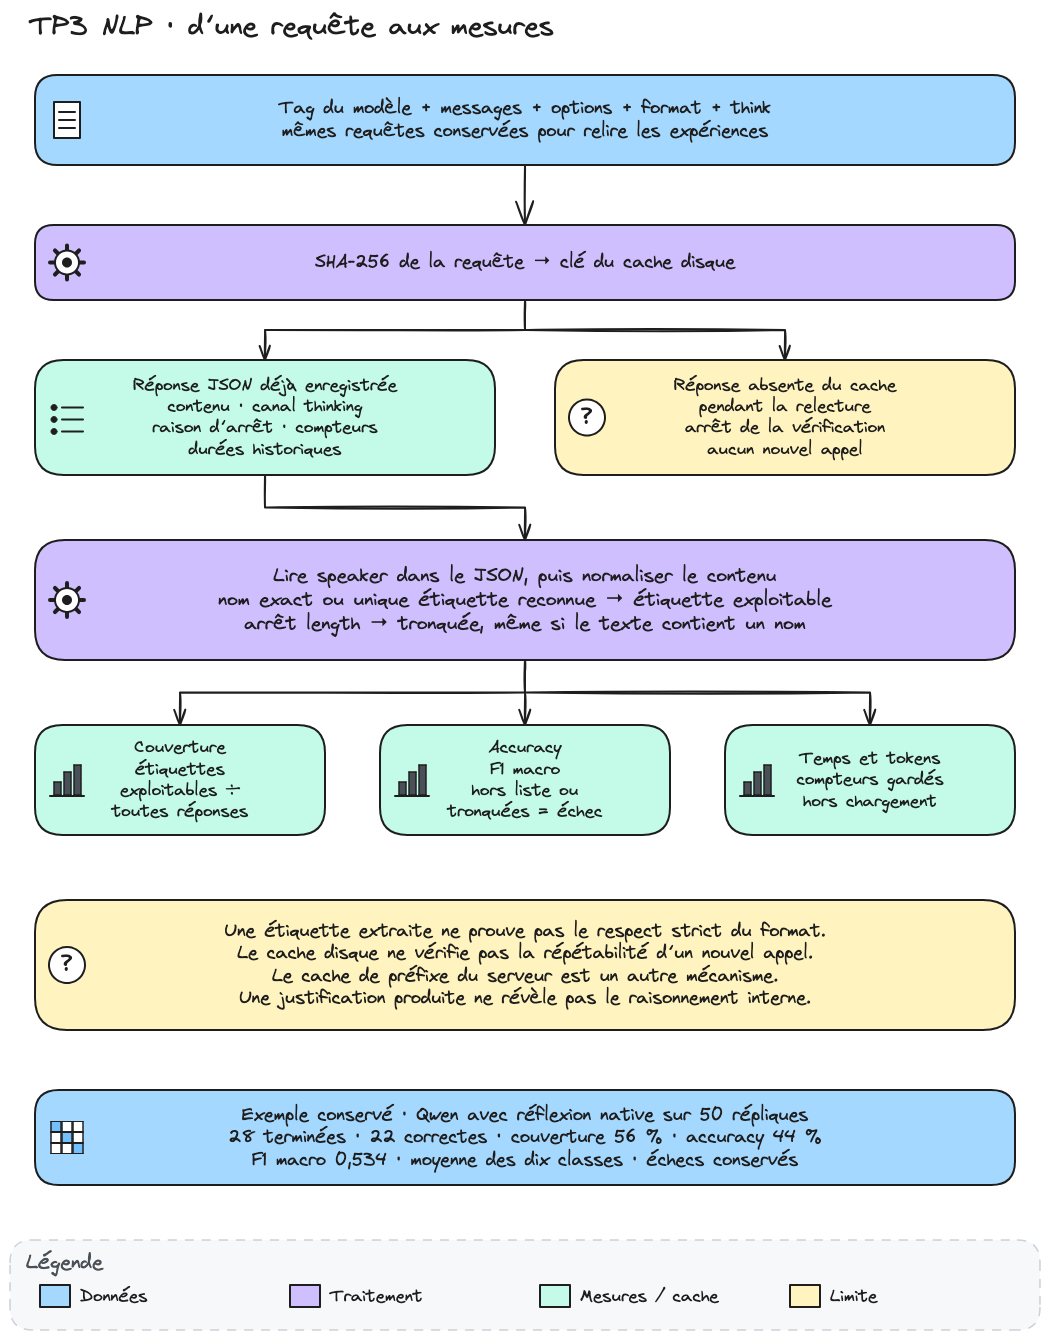

In [39]:
# Je distingue le cache, la lecture des réponses et les mesures.
from IPython.display import Image

display(Image(filename='diagrams/nlp/tp3_reponses.png', width=1000))


Les prédictions du développement fournissent maintenant de vrais cas hors liste et tronqués. Je reviens au parseur avec un cas correct et ces deux échecs enregistrés. Ce petit ensemble explique le calcul, sans constituer une nouvelle estimation des performances.


In [40]:
# Je suis trois réponses existantes depuis leur contenu jusqu'aux métriques.
demo_gemma = resultats['v0 gemma']['mesures'].copy()
demo_qwen = resultats['v0 qwen']['mesures'].copy()
demo_pg, demo_pq = lire_etiquettes(demo_gemma), lire_etiquettes(demo_qwen)
demo_sources = [demo_gemma.loc[demo_pg == demo_gemma['vrai']].head(1),
                demo_gemma.loc[demo_pg == HORS_LISTE].head(1),
                demo_qwen.loc[demo_pq == TRONQUEE].head(1)]
assert all(len(demo_source) == 1 for demo_source in demo_sources)
demo_reponses = pd.concat(demo_sources).copy()
demo_lues = lire_etiquettes(demo_reponses)
demo_vue = demo_reponses[['vrai', 'arrêt']].copy()
demo_vue['Extrait du contenu brut'] = demo_reponses['contenu'].str[:200]
demo_vue['Lecture du contenu seul'] = demo_reponses['contenu'].map(normaliser_reponse)
demo_vue['Étiquette après contrôle de fin'] = demo_lues
display(demo_vue)
assert demo_lues.iloc[0] == demo_reponses['vrai'].iloc[0]
assert demo_lues.iloc[1] == HORS_LISTE and demo_lues.iloc[2] == TRONQUEE
demo_classes = []
for demo_classe in NOMS:
    demo_tp = int(((demo_lues == demo_classe) & (demo_reponses['vrai'] == demo_classe)).sum())
    demo_fp = int(((demo_lues == demo_classe) & (demo_reponses['vrai'] != demo_classe)).sum())
    demo_fn = int(((demo_lues != demo_classe) & (demo_reponses['vrai'] == demo_classe)).sum())
    demo_denom = 2 * demo_tp + demo_fp + demo_fn
    demo_classes.append({'Classe': demo_classe, 'TP': demo_tp, 'FP': demo_fp, 'FN': demo_fn,
                         'F1': 2 * demo_tp / demo_denom if demo_denom else 0.0})
demo_comptes = pd.DataFrame(demo_classes).set_index('Classe')
display(demo_comptes)
demo_scores = scorer_table(demo_reponses)
assert np.isclose(demo_comptes['F1'].mean(), demo_scores['F1 macro'])
assert np.isclose(demo_scores['Accuracy'], 1 / 3)
assert np.isclose(demo_scores['Conformité (%)'], 100 / 3)
print('Couverture, accuracy, F1 :', demo_scores['Conformité (%)'],
      demo_scores['Accuracy'], demo_scores['F1 macro'])


Couverture, accuracy, F1 : 33.333333333333336 0.3333333333333333 0.1


,vrai,arrêt,Extrait du contenu brut,Lecture du contenu seul,Étiquette après contrôle de fin
indice,,,,,
4560,LEONTES,stop,LEONTES,LEONTES,LEONTES
3227,JULIET,stop,GERTRUDE,hors liste,hors liste
3131,JULIET,length,This is a famous soliloquy from *The Merchant ...,hors liste,tronquée


,TP,FP,FN,F1
Classe,,,,
CORIOLANUS,0,0,0,0.0
DUKE VINCENTIO,0,0,0,0.0
GLOUCESTER,0,0,0,0.0
ISABELLA,0,0,0,0.0
JULIET,0,0,2,0.0
KING RICHARD II,0,0,0,0.0
LEONTES,1,0,0,1.0
MENENIUS,0,0,0,0.0
PETRUCHIO,0,0,0,0.0


> *Mes observations :*
>
> Une réponse sur trois fournit ici une étiquette exploitable, et elle est correcte. Les deux échecs restent dans le dénominateur de l’accuracy et pénalisent le rappel de leur classe. Le F1 moyenne toujours les dix classes, y compris celles absentes de ce petit exemple.


> *Mes observations :*
>
> V0 donne 0,271 ± 0,030 de F1 moyen pour Gemma et 0,479 ± 0,027 pour Qwen. LinearSVC atteint 0,482. L’écart moyen de 0,003 avec Qwen est petit descriptivement, sans démontrer leur équivalence.
>
> Qwen dépasse Gemma dans chaque pli, de 0,208 en moyenne. Je trouve quatre sorties hors liste chez Gemma, puis une hors liste et une tronquée chez Qwen. Ces échecs restent comptés dans les scores.


Je passe ensuite v3, la version retenue sur Gemma, aux deux modèles. Je garde LinearSVC dans le tableau par fold, car c'est la référence que v3 doit dépasser.


In [41]:
# v3 sur les 769 répliques pour les deux modèles, puis F1 par fold des quatre couples.
passer_sur_folds('v3')
display(table_f1_folds(['LinearSVC TP1'] + COUPLES))
display(table_appels(COUPLES))

gemma, v3 : 769 appels, 8.4 min hors chargement
qwen, v3 : 769 appels, 19.2 min hors chargement


Fold,1,2,3,4,5,moyenne,écart-type
LinearSVC TP1,0.453,0.429,0.500,0.511,0.517,0.482,0.039
v0 gemma,0.295,0.284,0.296,0.251,0.229,0.271,0.030
v3 gemma,0.465,0.554,0.515,0.374,0.455,0.472,0.068
v0 qwen,0.473,0.508,0.487,0.489,0.437,0.479,0.027
v3 qwen,0.565,0.673,0.603,0.553,0.524,0.584,0.057


,F1 macro,Accuracy,Conformité (%),Hors liste,Tronquées,Tokens générés (médiane),Latence hors chargement (s)
v0 gemma,0.274,0.306,99.48,4,0,5.0,0.265
v3 gemma,0.476,0.489,100.00,0,0,19.0,0.641
v0 qwen,0.481,0.492,99.74,1,1,5.0,1.081
v3 qwen,0.587,0.586,100.00,0,0,10.0,1.355


Je compare enfin le gain de v3 sur v0 dans les 50 répliques de mise au point et hors d'elles. Je ramène le gain net à 100 répliques, car les deux sous-jeux n'ont pas la même taille.


In [42]:
# F1 sur les 50, les 719 et les 769 répliques, puis gain de v3 sur v0 dans et hors des 50.
noms = ['LinearSVC TP1'] + COUPLES
display(pd.DataFrame([f1_sous_jeux(nom) for nom in noms]).set_index('Modèle').round(3))
gains = [ligne_gain(modele, sous_jeu) for modele in MODELES for sous_jeu in SOUS_JEUX]
display(pd.DataFrame(gains).set_index(['Modèle', 'Sous-jeu']).round(3))

,F1 50 de mise au point,F1 719 hors mise au point,F1 769
Modèle,,,
LinearSVC TP1,0.303,0.498,0.486
v0 gemma,0.236,0.276,0.274
v3 gemma,0.453,0.478,0.476
v0 qwen,0.426,0.485,0.481
v3 qwen,0.488,0.593,0.587


F1 v0  F1 v3  Gain F1  Corrigées  Cassées  \
Modèle Sous-jeu                                                            
gemma  50 de mise au point     0.236  0.453    0.217         13        3   
       719 hors mise au point  0.276  0.478    0.202        182       51   
       769                     0.274  0.476    0.202        195       54   
qwen   50 de mise au point     0.426  0.488    0.062          3        1   
       719 hors mise au point  0.485  0.593    0.108        112       41   
       769                     0.481  0.587    0.106        115       42   

                               Gain net  Gain net pour 100 répliques  
Modèle Sous-jeu                                                       
gemma  50 de mise au point           10                       20.000  
       719 hors mise au point       131                       18.220  
       769                          141                       18.336  
qwen   50 de mise au point            2                        4.000  
       719 hors mise au point        71                        9.875  
       769                           73                        9.493

In [43]:
# Je compare la moyenne des F1 par pli au F1 des 769 prédictions regroupées.
demo_agregations = []
for demo_nom in ['LinearSVC TP1'] + COUPLES:
    demo_entree = resultats[demo_nom]
    demo_f1_global = f1_score(y_train, demo_entree['predictions'], labels=NOMS,
                              average='macro', zero_division=0)
    demo_agregations.append({'Modèle': demo_nom,
                             'Moyenne des cinq F1': demo_entree['folds']['F1 macro'].mean(),
                             'F1 regroupé sur 769': demo_f1_global})
display(pd.DataFrame(demo_agregations).set_index('Modèle').round(6))


,Moyenne des cinq F1,F1 regroupé sur 769
Modèle,,
LinearSVC TP1,0.482113,0.486212
v0 gemma,0.271177,0.273886
v3 gemma,0.472475,0.475678
v0 qwen,0.478739,0.480973
v3 qwen,0.583861,0.587223


Je garde les deux agrégations distinctes. Moyenner cinq rapports par classe ne revient pas à calculer ces rapports après avoir regroupé leurs effectifs. Les moyennes par pli servent aux comparaisons annoncées, tandis que les matrices regroupent les 769 prédictions.


> *Mes observations :*
>
> V3 atteint 0,472 ± 0,068 de F1 moyen pour Gemma et 0,584 ± 0,057 pour Qwen. Qwen dépasse LinearSVC dans les cinq plis, de 0,102 en moyenne. Les deux modèles fournissent toutes leurs étiquettes avec V3.
>
> Hors des 50 répliques, le gain de F1 de V3 sur V0 vaut 0,202 chez Gemma et 0,108 chez Qwen. Sur les 50, il valait 0,217 et 0,062. L’attente de rétrécissement décrit légèrement Gemma, mais pas Qwen.
>
> Je retiens V3 pour les deux modèles après cette consultation des 719 répliques. Cette décision utilise donc aussi leurs résultats. Elle ne compare pas V3 à V1-text sur l’ensemble du développement.
>
> H6 décrit ici deux systèmes complets qui diffèrent aussi par leur famille, leur préentraînement et leur quantification. H7 est soutenue pour le passage de V0 à V3 testé. Ce passage combine l’ajout du format et du contexte.


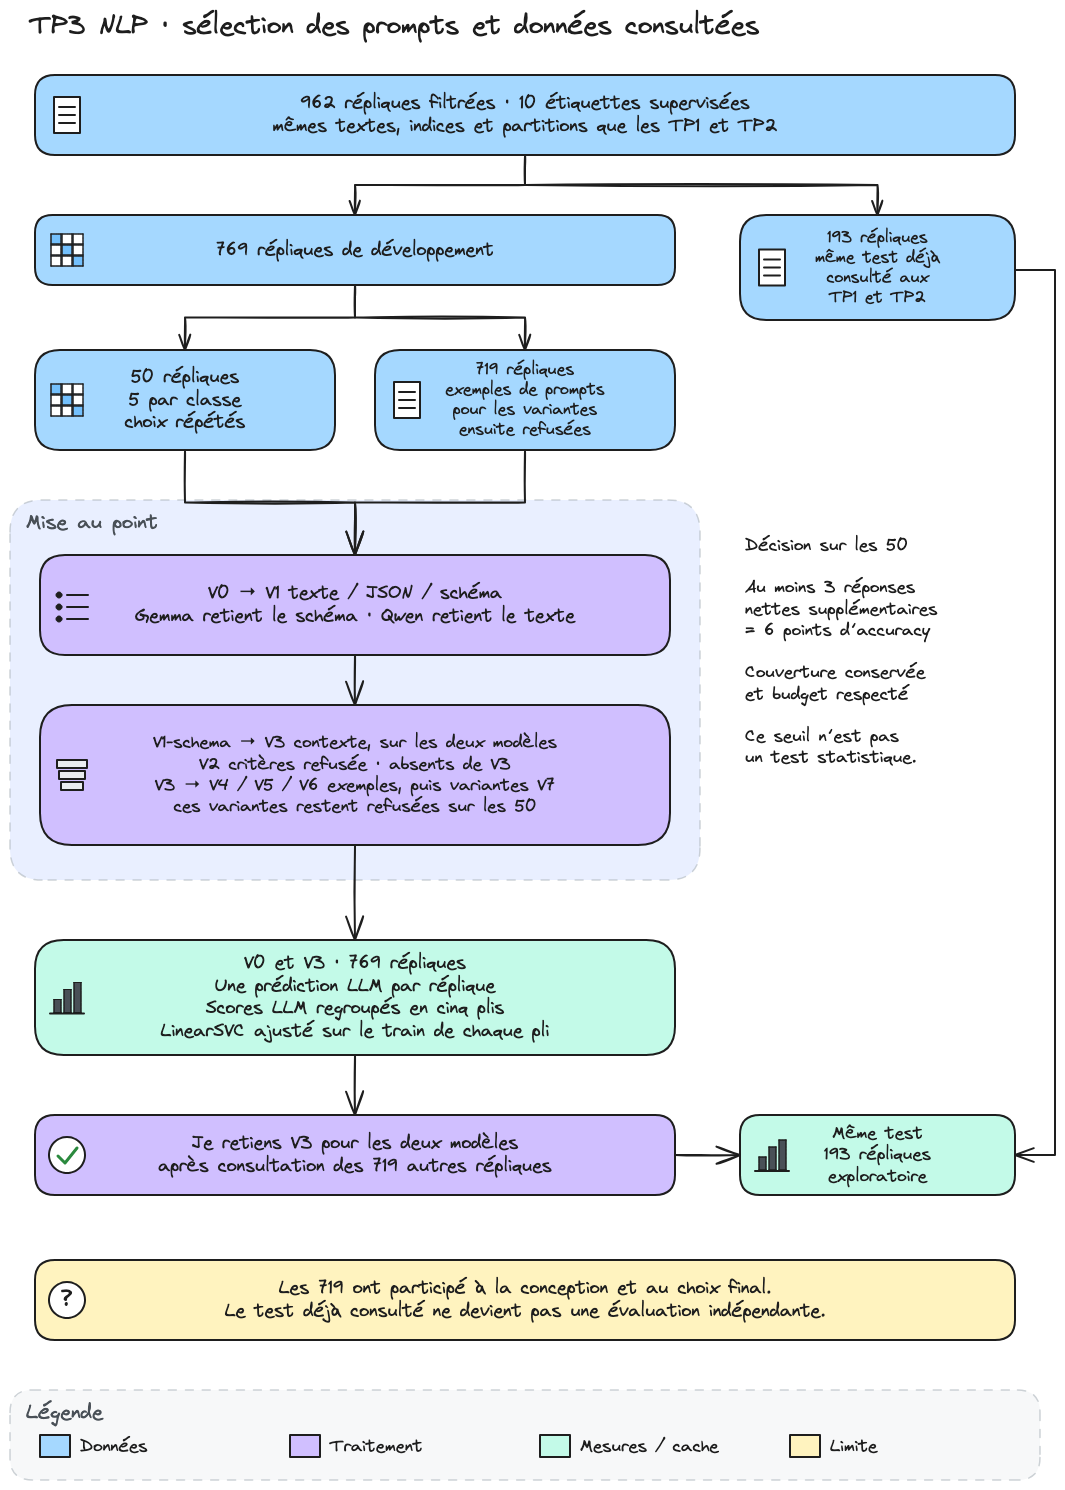

In [44]:
# Je représente les consultations successives et la filiation des prompts.
from IPython.display import Image

display(Image(filename='diagrams/nlp/tp3_protocole.png', width=1000))


## 4. Évaluation


### 4.1 Comparer sur les mêmes 769 répliques


Je rassemble accuracy et F1 par pli pour comparer les mêmes groupes de répliques. L’écart-type décrit cinq valeurs avec le diviseur n − 1. Il ne constitue pas un intervalle de confiance.


> *Mon hypothèse :* V3 sur Qwen dépasse LinearSVC, tandis que V3 sur Gemma lui reste proche. Je vérifie les désaccords de réponses et les scores par classe. Une proximité moyenne ne démontrera pas une égalité.


In [45]:
# Scores moyens des repères et des quatre couples, puis écart à LinearSVC TP1 fold par fold.
COMPARES = ['Majoritaire', 'LinearSVC TP1'] + COUPLES
REFERENCE = 'LinearSVC TP1'


def ligne_bilan(nom: str) -> dict:
    """Famille, F1 macro et accuracy moyens avec leur écart-type entre folds, et conformité."""
    table, predits = resultats[nom]['folds'], resultats[nom]['predictions']
    return {'Modèle': nom, 'Famille': resultats[nom]['famille'],
            'F1 macro': table['F1 macro'].mean(), 'F1 écart-type': table['F1 macro'].std(),
            'Accuracy': table['Accuracy'].mean(),
            'Accuracy écart-type': table['Accuracy'].std(),
            'Conformité (%)': pourcentage(predits.isin(NOMS).sum(), len(predits))}


def ecarts_par_fold(reference: str, nom: str) -> dict:
    """Écart de F1 macro à la référence dans chaque fold, folds gagnés et écart moyen."""
    ecart = resultats[nom]['folds']['F1 macro'] - resultats[reference]['folds']['F1 macro']
    return {'Modèle': nom, **{f'Fold {fold}': valeur for fold, valeur in ecart.items()},
            'Folds gagnés': int((ecart > 0).sum()), 'Écart moyen': ecart.mean()}


display(pd.DataFrame([ligne_bilan(nom) for nom in COMPARES]).set_index('Modèle').round(3))
display(pd.DataFrame([ecarts_par_fold(REFERENCE, nom) for nom in COUPLES])
        .set_index('Modèle').round(3))

,Famille,F1 macro,F1 écart-type,Accuracy,Accuracy écart-type,Conformité (%)
Modèle,,,,,,
Majoritaire,ML,0.024,0.001,0.134,0.003,100.00
LinearSVC TP1,ML,0.482,0.039,0.492,0.041,100.00
v0 gemma,LLM,0.271,0.030,0.306,0.032,99.48
v3 gemma,LLM,0.472,0.068,0.489,0.064,100.00
v0 qwen,LLM,0.479,0.027,0.491,0.026,99.74
v3 qwen,LLM,0.584,0.057,0.586,0.051,100.00


,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Folds gagnés,Écart moyen
Modèle,,,,,,,
v0 gemma,-0.157,-0.145,-0.204,-0.260,-0.288,0,-0.211
v3 gemma,0.012,0.125,0.015,-0.138,-0.063,3,-0.010
v0 qwen,0.020,0.079,-0.013,-0.023,-0.081,2,-0.003
v3 qwen,0.112,0.244,0.103,0.042,0.007,5,0.102


> *Mes observations :*
>
> v3 sur Qwen gagne les cinq folds face à LinearSVC, de 0,244 au mieux, mais de 0,007 seulement dans le fold 5. v3 sur Gemma gagne trois folds sur cinq, avec un écart moyen de −0,010 tiré par le fold 4 (−0,138). Son écart-type de 0,068 est le plus grand du tableau, donc Gemma réussit très inégalement d'un fold à l'autre. Toutes les configurations gardent au moins 99 % de conformité.


Je conserve le test exact de McNemar pour examiner les répliques où un seul modèle a raison. Il teste la répartition de ces désaccords correct/incorrect, sans tester directement le F1 macro. La sélection préalable, les comparaisons multiples et les dépendances entre répliques limitent son interprétation.


In [46]:
# Répliques où un seul des deux modèles a raison, sur les 769, puis test de McNemar exact.
from scipy.stats import binomtest

PAIRES = [('LinearSVC TP1', 'v3 gemma'), ('LinearSVC TP1', 'v3 qwen'), ('v3 gemma', 'v3 qwen'),
          ('v0 gemma', 'v3 gemma'), ('v0 qwen', 'v3 qwen')]


def comparer_paire(a: str, b: str, registre: dict = resultats,
                   vrais: pd.Series = y_train) -> dict:
    """Répliques justes pour un seul modèle ou pour les deux, puis p-value de McNemar exact."""
    juste_a = registre[a]['predictions'] == vrais
    juste_b = registre[b]['predictions'] == vrais
    seul_a, seul_b = int((juste_a & ~juste_b).sum()), int((juste_b & ~juste_a).sum())
    # Sans aucun désaccord, rien ne distingue les deux modèles
    p_value = binomtest(seul_a, seul_a + seul_b, 0.5).pvalue if seul_a + seul_b else 1.0
    return {'A': a, 'B': b, 'A seul juste': seul_a, 'B seul juste': seul_b,
            'Deux justes': int((juste_a & juste_b).sum()),
            'Deux faux': int((~juste_a & ~juste_b).sum()), 'p-value': f'{p_value:.1e}'}


display(pd.DataFrame([comparer_paire(a, b) for a, b in PAIRES]).set_index(['A', 'B']))

A seul juste  B seul juste  Deux justes  Deux faux  \
A             B                                                              
LinearSVC TP1 v3 gemma           139           137          239        254   
              v3 qwen            106           179          272        212   
v3 gemma      v3 qwen             77           152          299        241   
v0 gemma      v3 gemma            54           195          181        339   
v0 qwen       v3 qwen             42           115          336        276   

                        p-value  
A             B                  
LinearSVC TP1 v3 gemma  9.5e-01  
              v3 qwen   1.8e-05  
v3 gemma      v3 qwen   8.1e-07  
v0 gemma      v3 gemma  6.6e-20  
v0 qwen       v3 qwen   4.9e-09

> *Mes observations :*
>
> LinearSVC et V3 Gemma ont seuls raison sur 139 et 137 répliques, avec p = 0,95. Cette valeur ne démontre pas leur équivalence. Pour V3 Qwen contre LinearSVC, les désaccords valent 179 contre 106, avec p = 1,8e-05.
>
> Le passage de V0 à V3 donne aussi davantage de corrections que de dégradations chez les deux modèles. Ces comparaisons restent exploratoires après la sélection des prompts. Les 557 répliques réussies par LinearSVC ou Qwen ne sont pas le score d’un système sachant choisir entre eux.


Je lis ensuite chaque locuteur pour LinearSVC et pour v3 sur les deux modèles, car le F1 macro peut cacher une classe abandonnée. Le support rappelle combien de répliques porte chaque score.


In [47]:
# Précision, rappel et F1 de chaque locuteur pour LinearSVC et pour v3 sur les deux modèles.
from sklearn.metrics import precision_recall_fscore_support

MEILLEURS = ['LinearSVC TP1', 'v3 gemma', 'v3 qwen']


def metriques_par_classe(nom: str) -> pd.DataFrame:
    """Précision, rappel et F1 de chaque locuteur sur les 769 prédictions hors fold."""
    precision, rappel, f1, _ = precision_recall_fscore_support(
        y_train, resultats[nom]['predictions'], labels=NOMS, zero_division=0)
    return pd.DataFrame({'Précision': precision, 'Rappel': rappel, 'F1': f1}, index=NOMS)


par_classe = pd.concat({nom: metriques_par_classe(nom) for nom in MEILLEURS}, axis=1)
par_classe['Support'] = y_train.value_counts().reindex(NOMS)
display(par_classe.round(3))

LinearSVC TP1                v3 gemma                 v3 qwen  \
                    Précision Rappel     F1 Précision Rappel     F1 Précision   
CORIOLANUS              0.468  0.414  0.439     0.513  0.557  0.534     0.644   
DUKE VINCENTIO          0.466  0.620  0.532     0.471  0.720  0.569     0.818   
GLOUCESTER              0.505  0.485  0.495     0.700  0.340  0.458     0.822   
ISABELLA                0.519  0.422  0.466     0.444  0.250  0.320     0.571   
JULIET                  0.344  0.324  0.333     0.579  0.324  0.415     0.750   
KING RICHARD II         0.558  0.468  0.509     0.667  0.452  0.538     0.402   
LEONTES                 0.587  0.409  0.482     0.352  0.485  0.408     0.795   
MENENIUS                0.434  0.506  0.467     0.600  0.494  0.542     0.700   
PETRUCHIO               0.700  0.737  0.718     0.413  0.750  0.533     0.492   
ROMEO                   0.402  0.440  0.420     0.440  0.440  0.440     0.441   

                              Support  
                Rappel     F1          
CORIOLANUS       0.671  0.657      70  
DUKE VINCENTIO   0.450  0.581     100  
GLOUCESTER       0.359  0.500     103  
ISABELLA         0.500  0.533      64  
JULIET           0.485  0.589      68  
KING RICHARD II  0.790  0.533      62  
LEONTES          0.530  0.636      66  
MENENIUS         0.659  0.679      85  
PETRUCHIO        0.855  0.625      76  
ROMEO            0.693  0.539      75

> *Mes observations :*
>
> Le plus faible F1 par classe du tableau vaut 0,320, pour ISABELLA chez Gemma. V3 Qwen dépasse LinearSVC sur neuf classes, mais perd sur PETRUCHIO, avec 0,625 contre 0,718. Ses rappels et précisions varient donc malgré son avance moyenne.
>
> Pour GLOUCESTER, Qwen atteint 0,359 de rappel et 0,822 de précision. Il récupère peu de répliques de cette classe, mais ses prédictions correspondantes sont souvent correctes. Je lis ensuite les destinations des erreurs dans la matrice.


Je trace chaque matrice séparément pour garder ses cases lisibles. Une ligne correspond à l’étiquette réelle et une colonne à la prédiction. Je donne le pourcentage dans la classe réelle et l’effectif, avec la même échelle de couleurs de 0 à 100 %.


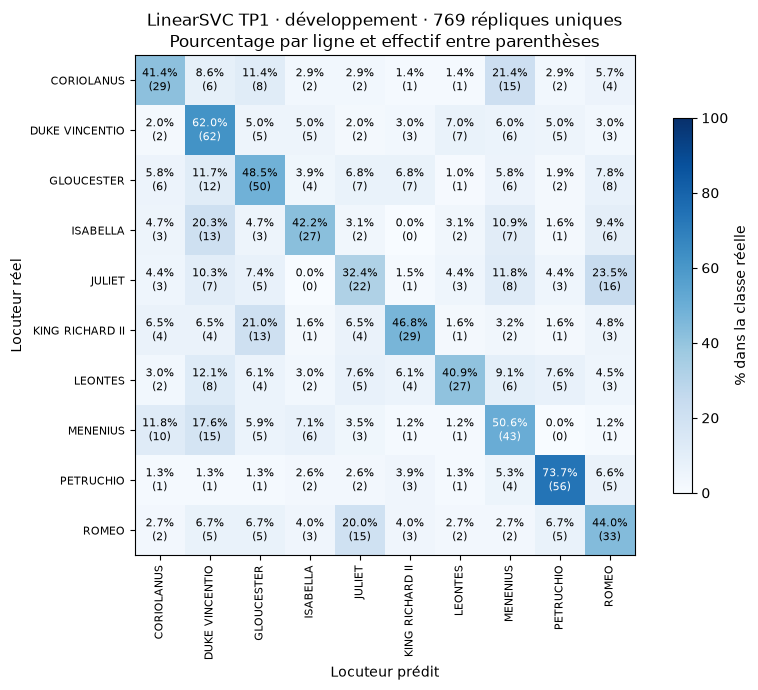

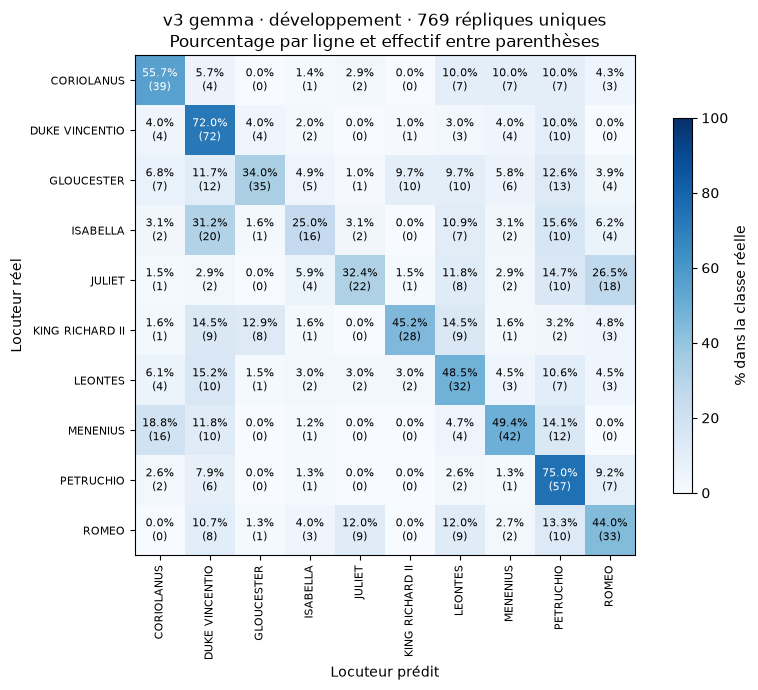

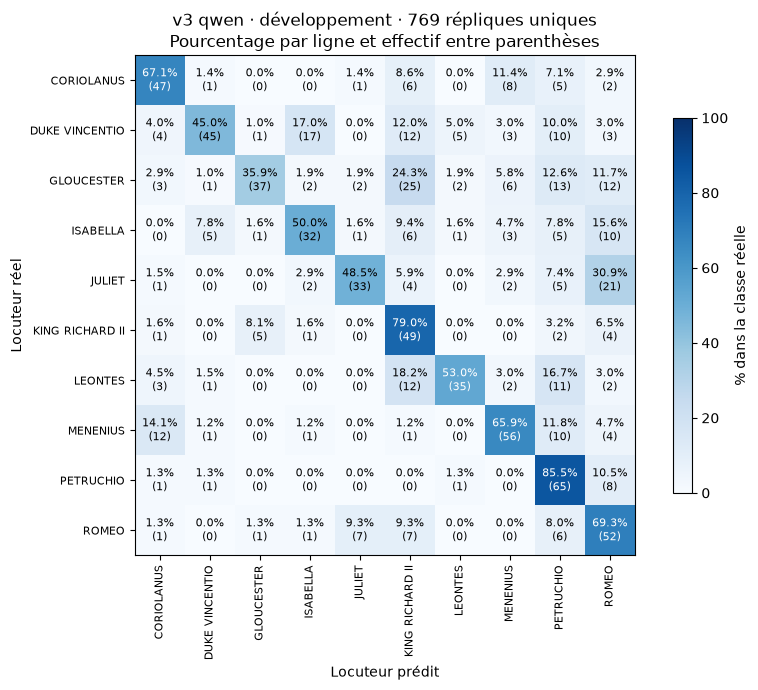

In [48]:
# Matrices de confusion de LinearSVC et de v3 sur les 769 répliques, en % du locuteur réel.
import matplotlib.pyplot as plt


def matrice_confusion(nom: str, registre: dict = resultats,
                      vrais: pd.Series = y_train) -> pd.DataFrame:
    """Effectifs réel × prédit, sorties hors liste ou tronquées dans des colonnes à part."""
    predits = registre[nom]['predictions']
    ratees = [sortie for sortie in (HORS_LISTE, TRONQUEE) if (predits == sortie).any()]
    return pd.crosstab(vrais, predits).reindex(index=NOMS, columns=NOMS + ratees, fill_value=0)


def en_pourcentage(matrice: pd.DataFrame) -> pd.DataFrame:
    """Chaque ligne en % des répliques du locuteur réel."""
    return matrice.apply(lambda ligne: pourcentage(ligne, ligne.sum()), axis=1)


def tracer_matrice(axe, nom: str, matrice: pd.DataFrame) -> None:
    """Carte d'une matrice en % par ligne, pourcentages et effectifs dans les cases."""
    parts = en_pourcentage(matrice)
    carte_image = axe.imshow(parts, cmap='Blues', vmin=0, vmax=100)
    axe.figure.colorbar(carte_image, ax=axe, label='% dans la classe réelle', shrink=0.75)
    for (ligne, colonne), valeur in np.ndenumerate(parts.to_numpy()):
        axe.text(colonne, ligne, f'{valeur:.1f}%\n({matrice.iloc[ligne, colonne]})',
                 ha='center', va='center', fontsize=8,
                 color='white' if valeur > 50 else 'black')
    axe.set_xticks(range(len(parts.columns)), parts.columns, rotation=90, fontsize=8)
    axe.set_yticks(range(len(NOMS)), NOMS, fontsize=8)
    axe.set(title=f'{nom}\nPourcentage par ligne et effectif entre parenthèses',
            xlabel='Locuteur prédit',
            ylabel='Locuteur réel')


matrices = {nom: matrice_confusion(nom) for nom in MEILLEURS}
for nom, matrice in matrices.items():
    fig, axe = plt.subplots(figsize=(9, 7))
    tracer_matrice(axe, f'{nom} · développement · 769 répliques uniques', matrice)
    plt.tight_layout()
    plt.show()

Je résume chaque matrice par son rappel moyen, ses trois plus fortes confusions et les deux couples suivis depuis le TP1. Je donne chaque case en % et en effectifs, car un petit locuteur fait varier un pourcentage avec peu de répliques.


In [49]:
# Rappel moyen, trois plus fortes confusions et couples du TP1 de chaque matrice.
CONFUSIONS_TP1 = [('JULIET', 'ROMEO'), ('ROMEO', 'JULIET'),
                  ('GLOUCESTER', 'DUKE VINCENTIO'), ('DUKE VINCENTIO', 'GLOUCESTER')]


def decrire_case(matrice: pd.DataFrame, reel: str, predit: str) -> str:
    """Part d'une case dans les répliques du locuteur réel, avec les effectifs."""
    case, total = matrice.loc[reel, predit], matrice.loc[reel].sum()
    return f'{reel} → {predit} : {pourcentage(case, total):.1f} % ({case} sur {total})'


def decrire_confusions(matrices: dict) -> None:
    """Rappel moyen, trois plus fortes confusions et couples du TP1 de chaque matrice."""
    for nom, matrice in matrices.items():
        parts = en_pourcentage(matrice)[NOMS]
        hors_diagonale = parts.where(~np.eye(len(NOMS), dtype=bool)).stack().dropna()
        print(f'{nom} : rappel moyen {np.diag(parts).mean():.1f} %')
        for titre, cases in (('plus fortes confusions', hors_diagonale.nlargest(3).index),
                             ('couples suivis depuis le TP1', CONFUSIONS_TP1)):
            print(f'   {titre}')
            for reel, predit in cases:
                print(f'      {decrire_case(matrice, reel, predit)}')


decrire_confusions(matrices)

LinearSVC TP1 : rappel moyen 48.2 %
   plus fortes confusions
      JULIET → ROMEO : 23.5 % (16 sur 68)
      CORIOLANUS → MENENIUS : 21.4 % (15 sur 70)
      KING RICHARD II → GLOUCESTER : 21.0 % (13 sur 62)
   couples suivis depuis le TP1
      JULIET → ROMEO : 23.5 % (16 sur 68)
      ROMEO → JULIET : 20.0 % (15 sur 75)
      GLOUCESTER → DUKE VINCENTIO : 11.7 % (12 sur 103)
      DUKE VINCENTIO → GLOUCESTER : 5.0 % (5 sur 100)
v3 gemma : rappel moyen 48.1 %
   plus fortes confusions
      ISABELLA → DUKE VINCENTIO : 31.2 % (20 sur 64)
      JULIET → ROMEO : 26.5 % (18 sur 68)
      MENENIUS → CORIOLANUS : 18.8 % (16 sur 85)
   couples suivis depuis le TP1
      JULIET → ROMEO : 26.5 % (18 sur 68)
      ROMEO → JULIET : 12.0 % (9 sur 75)
      GLOUCESTER → DUKE VINCENTIO : 11.7 % (12 sur 103)
      DUKE VINCENTIO → GLOUCESTER : 4.0 % (4 sur 100)
v3 qwen : rappel moyen 59.9 %
   plus fortes confusions
      JULIET → ROMEO : 30.9 % (21 sur 68)
      GLOUCESTER → KING RICHARD II : 24.3

> *Mes observations :*
>
> Les rappels moyens valent 48,2 % pour LinearSVC, 48,1 % pour Gemma et 59,9 % pour Qwen. JULIET vers ROMEO passe de 23,5 % chez LinearSVC à 30,9 % chez Qwen. Dans le sens inverse, ROMEO vers JULIET passe de 20,0 % à 9,3 %.
>
> Qwen réduit fortement GLOUCESTER–DUKE VINCENTIO, mais envoie 24,3 % de GLOUCESTER et 18,2 % de LEONTES vers KING RICHARD II. Je retrouve une avance globale avec des erreurs propres à chaque système. Le test apparié ne transforme pas ces résultats sélectionnés en garantie de généralisation.


### 4.2 Revenir aux répliques


Je regroupe d’abord les erreurs avec la reconstruction des pièces employée au TP2. Ces groupes viennent des étiquettes et de leurs positions dans le corpus, sans annotation indépendante. Je compte ensuite les prédictions par classe pour décrire leurs déséquilibres.


> *Mon hypothèse :* les erreurs des LLM restent plus souvent dans la pièce que celles de LinearSVC. J’attends aussi un gain lié aux noms cités. Le premier contrôle utilisera des groupes heuristiques et le second un indicateur lexical imparfait.


Je compare enfin les accords et les exemples d’erreurs. Des erreurs partagées peuvent provenir de plusieurs causes, dont les modèles ou les données. Elles ne démontrent pas à elles seules une ambiguïté intrinsèque des répliques.


In [50]:
# Pièces reconstruites à partir des seules étiquettes du corpus, avec la règle du TP2.
from collections import Counter

ECART_PIECE = 400  # Positions sans le locuteur au-delà desquelles il change de pièce
FENETRE_PIECE = 5  # Répliques suivantes où je cherche une réponse
SEUIL_PIECE = 20  # Réponses nécessaires pour relier deux morceaux


def morceaux_locuteurs() -> dict:
    """Positions de chaque locuteur retenu dans le corpus, coupées aux grands écarts."""
    etiquettes, morceaux = df['locuteur'].to_numpy(), {}
    for locuteur in NOMS:
        positions = np.flatnonzero(etiquettes == locuteur)
        coupures = np.flatnonzero(np.diff(positions) > ECART_PIECE) + 1
        for numero, bloc in enumerate(np.split(positions, coupures), start=1):
            morceaux[(locuteur, numero)] = bloc
    return morceaux


def compter_reponses(morceaux: dict) -> Counter:
    """Fois où deux morceaux de locuteurs différents se suivent à moins de la fenêtre."""
    morceau_de = {position: cle for cle, bloc in morceaux.items() for position in bloc}
    liens = Counter()
    for position, cle in morceau_de.items():
        for suivante in range(position + 1, position + FENETRE_PIECE + 1):
            autre = morceau_de.get(suivante)
            if autre is not None and autre[0] != cle[0]:
                liens[tuple(sorted((cle, autre)))] += 1
    return liens


def numeroter_pieces(morceaux: dict, liens: Counter) -> dict:
    """Pièce de chaque morceau : liens d'au moins SEUIL_PIECE réponses, numéros dans l'ordre."""
    parent = {cle: cle for cle in morceaux}

    def racine(cle):
        while parent[cle] != cle:
            cle = parent[cle]
        return cle

    for (a, b), nombre in liens.items():
        if nombre >= SEUIL_PIECE:
            parent[racine(a)] = racine(b)
    debuts = {}
    for cle, bloc in morceaux.items():
        debuts[racine(cle)] = min(debuts.get(racine(cle), bloc[0]), bloc[0])
    numeros = {r: k for k, r in enumerate(sorted(debuts, key=debuts.get), start=1)}
    return {cle: numeros[racine(cle)] for cle in morceaux}


# Morceaux, liens et pièces
morceaux = morceaux_locuteurs()
liens = compter_reponses(morceaux)
piece_morceau = numeroter_pieces(morceaux, liens)

# Pièce de chaque réplique de développement, par sa position dans le corpus
assert (df.loc[X_train.index, 'locuteur'] == y_train).all()  # Indices du TP1 conservés
piece_position = {p: piece_morceau[cle] for cle, bloc in morceaux.items() for p in bloc}
pieces_du_locuteur = {locuteur: {piece for (nom, _), piece in piece_morceau.items()
                                 if nom == locuteur} for locuteur in NOMS}

# Morceaux de chaque pièce, avec leurs répliques de développement entre parenthèses
developpement = set(X_train.index)
for piece in sorted(set(piece_morceau.values())):
    membres = [f'{nom} {numero} ({len(developpement.intersection(morceaux[(nom, numero)]))})'
               for (nom, numero), p in piece_morceau.items() if p == piece]
    print(f'Pièce {piece} : {", ".join(membres)}')

Pièce 1 : CORIOLANUS 1 (70), MENENIUS 1 (85)
Pièce 2 : GLOUCESTER 1 (78)
Pièce 3 : KING RICHARD II 1 (62)
Pièce 4 : JULIET 1 (67), ROMEO 1 (75)
Pièce 5 : GLOUCESTER 2 (25)
Pièce 6 : LEONTES 1 (66)
Pièce 7 : DUKE VINCENTIO 1 (100), ISABELLA 1 (64), JULIET 2 (1)
Pièce 8 : PETRUCHIO 1 (76)


> *Mes observations :*
>
> Je retrouve huit groupes heuristiques. GLOUCESTER apparaît dans deux groupes de développement, avec 78 et 25 répliques. JULIET possède aussi une réplique dans le groupe de DUKE VINCENTIO et ISABELLA.
>
> Cette dernière observation limite la description unique de JULIET dans V3. Son faible effectif ne prouve pas que cette description coûte peu. Elle pourrait aussi modifier des prédictions d’autres classes.


Je mesure la part des erreurs dont l’étiquette prédite reste dans le groupe de la réplique. Mon repère suppose une erreur uniformément répartie parmi les neuf autres classes. Ce modèle aléatoire conditionnel ne représente pas tous les comportements possibles d’un classifieur.


In [51]:
# Part des erreurs restées dans la pièce de la réplique, face au hasard, pour LinearSVC et les LLM.
INTRA = ['LinearSVC TP1'] + COUPLES


def dans_la_piece(indice, predit: str) -> bool:
    """Vrai si le locuteur prédit a un morceau dans la pièce de la réplique."""
    return piece_position[indice] in pieces_du_locuteur.get(predit, set())  # Hors liste : non


def part_intra(nom: str) -> dict:
    """Erreurs, part restée dans la pièce de la réplique et part attendue au hasard."""
    predits = resultats[nom]['predictions']
    erreurs = predits.index[predits != y_train]
    dedans = sum(dans_la_piece(i, predits.loc[i]) for i in erreurs)
    # Hasard : l'erreur tombe sur l'un des neuf autres locuteurs, chacun avec la même chance
    hasard = sum(dans_la_piece(i, autre) for i in erreurs for autre in NOMS
                 if autre != y_train.loc[i]) / (len(NOMS) - 1)
    return {'Modèle': nom, 'Erreurs': len(erreurs),
            'Dans la pièce (%)': pourcentage(dedans, len(erreurs)),
            'Hasard (%)': pourcentage(hasard, len(erreurs)), 'Rapport au hasard': dedans / hasard}


display(pd.DataFrame([part_intra(nom) for nom in INTRA]).set_index('Modèle').round(2))

,Erreurs,Dans la pièce (%),Hasard (%),Rapport au hasard
Modèle,,,,
LinearSVC TP1,391,20.20,9.15,2.21
v0 gemma,534,10.11,8.86,1.14
v3 gemma,393,18.58,8.91,2.09
v0 qwen,391,22.76,9.01,2.53
v3 qwen,318,22.01,9.96,2.21


> *Mes observations :*
>
> LinearSVC garde 20,2 % de ses erreurs dans le groupe, soit 2,21 fois son repère uniforme. V3 donne 18,6 % chez Gemma et 22,0 % chez Qwen. Ces proportions ne soutiennent pas une séparation générale entre erreurs ML et erreurs LLM.
>
> Chez Gemma, la proportion passe de 10,1 % avec V0 à 18,6 % avec V3. Qwen passe de 22,8 % à 22,0 %. Les ensembles d’erreurs changent aussi entre versions, donc je ne lis pas ces proportions comme un effet causal isolé du contexte.


Je compare le nombre de prédictions de chaque classe à son effectif réel. Un rapport supérieur à un décrit une classe prédite plus souvent qu’elle n’apparaît. Il ne suffit pas à identifier un a priori appris pendant le préentraînement.


In [52]:
# Prédictions par locuteur face aux effectifs réels, puis rapport des prédictions au réel.
RATEES = [HORS_LISTE, TRONQUEE]
predites = pd.DataFrame({nom: resultats[nom]['predictions'].value_counts() for nom in INTRA})
predites = predites.reindex(NOMS + RATEES).fillna(0).astype(int)
predites.insert(0, 'Réel', y_train.value_counts().reindex(NOMS + RATEES).fillna(0).astype(int))
display(predites)
display(predites.loc[NOMS, INTRA].div(predites.loc[NOMS, 'Réel'], axis=0).round(2))

,Réel,LinearSVC TP1,v0 gemma,v3 gemma,v0 qwen,v3 qwen
CORIOLANUS,70,62,101,76,127,73
DUKE VINCENTIO,100,133,148,153,30,55
GLOUCESTER,103,99,123,50,3,45
ISABELLA,64,52,4,36,73,56
JULIET,68,64,18,38,48,44
KING RICHARD II,62,52,8,42,164,122
LEONTES,66,46,118,91,29,44
MENENIUS,85,99,19,70,116,80
PETRUCHIO,76,80,85,138,73,132
ROMEO,75,82,141,75,104,118


,LinearSVC TP1,v0 gemma,v3 gemma,v0 qwen,v3 qwen
CORIOLANUS,0.89,1.44,1.09,1.81,1.04
DUKE VINCENTIO,1.33,1.48,1.53,0.30,0.55
GLOUCESTER,0.96,1.19,0.49,0.03,0.44
ISABELLA,0.81,0.06,0.56,1.14,0.88
JULIET,0.94,0.26,0.56,0.71,0.65
KING RICHARD II,0.84,0.13,0.68,2.65,1.97
LEONTES,0.70,1.79,1.38,0.44,0.67
MENENIUS,1.16,0.22,0.82,1.36,0.94
PETRUCHIO,1.05,1.12,1.82,0.96,1.74
ROMEO,1.09,1.88,1.00,1.39,1.57


> *Mes observations :*
>
> Les rapports de LinearSVC vont de 0,70 à 1,33. V0 Qwen prédit GLOUCESTER trois fois pour 103 répliques et KING RICHARD II 164 fois pour 62. V3 remonte GLOUCESTER à 45 prédictions.
>
> *Mon hypothèse :* l’ambiguïté autour de Richard contribue à cette confusion. Ces fréquences motivent la relecture des exemples, mais ne révèlent pas les indices effectivement utilisés par le modèle.


Je mesure l’accord sur l’étiquette, puis sur la mauvaise étiquette lorsque les deux modèles échouent. Je compte aussi les répliques ratées par les six configurations. Ces contrôles décrivent leur complémentarité sans attribuer les difficultés à une cause unique.


In [53]:
# Accord entre deux modèles : même étiquette, erreurs communes, même erreur, puis ratées par tous.
ACCORDS = [('v3 gemma', 'v3 qwen'), ('LinearSVC TP1', 'v3 gemma'), ('LinearSVC TP1', 'v3 qwen')]


def accord(a: str, b: str) -> dict:
    """Part d'étiquettes identiques, répliques fausses pour les deux et part de la même erreur."""
    predits_a, predits_b = resultats[a]['predictions'], resultats[b]['predictions']
    deux_faux = (predits_a != y_train) & (predits_b != y_train)
    meme_erreur = (deux_faux & (predits_a == predits_b)).sum()
    return {'A': a, 'B': b,
            'Même étiquette (%)': pourcentage((predits_a == predits_b).sum(), len(y_train)),
            'Deux faux': int(deux_faux.sum()),
            'Même erreur (%)': pourcentage(meme_erreur, deux_faux.sum())}


display(pd.DataFrame([accord(a, b) for a, b in ACCORDS]).set_index(['A', 'B']).round(1))
justes = pd.DataFrame({nom: resultats[nom]['predictions'] == y_train for nom in INTRA})
rates_par_tous = justes.index[~justes.any(axis=1)].sort_values()  # Ordre du corpus
print(f'Répliques ratées par les six : {len(rates_par_tous)} sur {len(justes)}, '
      f'soit {pourcentage(len(rates_par_tous), len(justes)):.1f} %')

Répliques ratées par les six : 132 sur 769, soit 17.2 %


Même étiquette (%)  Deux faux  Même erreur (%)
A             B                                                       
v3 gemma      v3 qwen                 49.4        241             33.6
LinearSVC TP1 v3 gemma                36.9        254             17.7
              v3 qwen                 40.4        212             18.4

> *Mes observations :*
>
> v3 sur Gemma et v3 sur Qwen donnent la même étiquette sur 49,4 % des répliques. Quand les deux se trompent, ils choisissent le même mauvais nom dans 33,6 % des cas. Avec LinearSVC, cette part tombe à 17,7 % pour Gemma et 18,4 % pour Qwen. Les six configurations ratent ensemble 132 répliques, soit 17,2 %.


Je réutilise l’indicateur lexical de la section 3.4 sans changer sa liste ni son masque. Je compte les corrections et dégradations de V3 face à LinearSVC dans ses deux groupes. Je ramène le gain net à 100 répliques pour comparer leurs tailles différentes.


In [54]:
# Corrections et dégradations de v3 face à LinearSVC, selon le masque lexical conservé.
MOTIF_CITE = '|'.join(rf'\b{nom}\b' for nom in NOMS_CITES)  # Mots entiers, casse conservée
cite_769 = X_train.str.contains(MOTIF_CITE)


def ligne_cite(nom: str, libelle: str, masque: pd.Series, registre: dict = resultats,
               vrais: pd.Series = y_train) -> dict:
    """Bilan face à LinearSVC sur un groupe de répliques, gain net pour 100 et justesses."""
    vrais, svc = vrais[masque], registre['LinearSVC TP1']['predictions'][masque]
    predits = registre[nom]['predictions'][masque]
    bilan = bilan_changement(vrais, svc, predits)
    return {'Modèle': nom, 'Répliques': libelle, 'Nombre': int(masque.sum()), **bilan,
            'Gain net pour 100': pourcentage(bilan['Gain net'], masque.sum()),
            'Justesse LinearSVC (%)': pourcentage((svc == vrais).sum(), masque.sum()),
            'Justesse du modèle (%)': pourcentage((predits == vrais).sum(), masque.sum())}


lignes_cite = [ligne_cite(nom, libelle, masque) for nom in ('v3 gemma', 'v3 qwen')
               for libelle, masque in (('indicateur détecté', cite_769),
                                       ('indicateur absent', ~cite_769))]
display(pd.DataFrame(lignes_cite).set_index(['Modèle', 'Répliques']).round(1))

Nombre  Corrigées  Cassées  Gain net  \
Modèle   Répliques                                                  
v3 gemma indicateur détecté     258         50       31        19   
         indicateur absent      511         87      108       -21   
v3 qwen  indicateur détecté     258         63       19        44   
         indicateur absent      511        116       87        29   

                             Gain net pour 100  Justesse LinearSVC (%)  \
Modèle   Répliques                                                       
v3 gemma indicateur détecté                7.4                    64.3   
         indicateur absent                -4.1                    41.5   
v3 qwen  indicateur détecté               17.1                    64.3   
         indicateur absent                 5.7                    41.5   

                             Justesse du modèle (%)  
Modèle   Répliques                                   
v3 gemma indicateur détecté                    71.7  
         indicateur absent                     37.4  
v3 qwen  indicateur détecté                    81.4  
         indicateur absent                     47.2

> *Mes observations :*
>
> L’indicateur détecte 258 répliques et laisse les 511 autres dans le groupe complémentaire. LinearSVC y atteint respectivement 64,3 % et 41,5 % d’accuracy. Le groupe détecté lui réussit donc déjà davantage.
>
> V3 Qwen gagne 17,1 réponses nettes pour 100 répliques détectées, contre 5,7 dans l’autre groupe. Gemma gagne 7,4 et perd 4,1. Ces associations concernent l’indicateur conservé, dont « The » fait partie, et non une annotation de noms de personnages.


Je relis les premières erreurs dans l’ordre du corpus pour rendre la sélection reproductible. Je conserve les sorties hors liste ou tronquées, puis trois échecs communs et trois réussites propres à Qwen. Cet ordre ne rend pas ces exemples représentatifs de toutes les erreurs.


In [55]:
# Répliques entières : sorties ratées de v0, puis ratées par tous et rattrapées par Qwen seul.
A_RELIRE = 3  # Répliques affichées par groupe
SORTIE_MAX = 300  # Caractères affichés d'une sortie brute


def afficher_replique(indice) -> None:
    """Locuteur réel, étiquette de chaque modèle, puis la réplique entière."""
    etiquettes = ', '.join(f'{nom} {resultats[nom]["predictions"].loc[indice]}' for nom in INTRA)
    print(f'[{indice}] réel {y_train.loc[indice]} | {etiquettes}')
    print(f'   {X_train.loc[indice]}')


# Sorties hors liste ou tronquées de v0, avec leur texte brut
for nom in ('v0 gemma', 'v0 qwen'):
    predits, table = resultats[nom]['predictions'], resultats[nom]['mesures']
    for indice in predits.index[predits.isin(RATEES)].sort_values():
        print(f'{nom} [{indice}] réel {y_train.loc[indice]}, {predits.loc[indice]}, '
              f'sortie {table.loc[indice, "contenu"][:SORTIE_MAX]!r}')

# Trois répliques ratées par les six, puis trois que seul v3 sur Qwen rattrape
print(f'\nRatées par les six, les {A_RELIRE} premières')
for indice in rates_par_tous[:A_RELIRE]:
    afficher_replique(indice)
seul_qwen = justes.index[justes['v3 qwen'] & ~justes['LinearSVC TP1'] & ~justes['v3 gemma']]
print(f'\nRattrapées par v3 sur Qwen seul : {len(seul_qwen)}, les {A_RELIRE} premières')
for indice in seul_qwen.sort_values()[:A_RELIRE]:
    afficher_replique(indice)

v0 gemma [593] réel MENENIUS, hors liste, sortie 'ANTONY'
v0 gemma [1098] réel GLOUCESTER, hors liste, sortie 'RICHARD II'
v0 gemma [3227] réel JULIET, hors liste, sortie 'GERTRUDE'
v0 gemma [5916] réel ISABELLA, hors liste, sortie 'CLAUDIUS'
v0 qwen [3131] réel JULIET, tronquée, sortie "This is a famous soliloquy from *The Merchant of Venice*, spoken by Portia. However, looking at the provided list of speakers (CORIOLANUS, DUKE VINCENTIO, GLOUCESTER, ISABELLA, JULIET, KING RICHARD II, LEONTES, MENENIUS, PETRUCHIO, ROMEO), none of them are Portia.\n\nLet's re-evaluate the quote and th"
v0 qwen [6100] réel PETRUCHIO, hors liste, sortie 'LORENZO'

Ratées par les six, les 3 premières
[34] réel MENENIUS | LinearSVC TP1 JULIET, v0 gemma PETRUCHIO, v3 gemma PETRUCHIO, v0 qwen CORIOLANUS, v3 qwen PETRUCHIO
   What then? 'Fore me, this fellow speaks! What then? what then?
[265] réel MENENIUS | LinearSVC TP1 DUKE VINCENTIO, v0 gemma GLOUCESTER, v3 gemma CORIOLANUS, v0 qwen CORIOLANUS, v3 qwen C

> *Mes observations :*
>
> Les sorties problématiques de V0 contiennent notamment d’autres noms et « RICHARD II », absent de la liste exacte. La réponse tronquée de Qwen évoque Portia avant de chercher une étiquette autorisée. J’observe ce texte sans en déduire un accès fidèle au raisonnement interne.
>
> Les trois premiers échecs communs concernent MENENIUS. Les trois premières réussites propres à Qwen concernent aussi MENENIUS, dont deux passages de la fable du ventre. Ces exemples suggèrent des pistes d’analyse, sans établir les contributions utilisées.
>
> L’hypothèse d’erreurs LLM systématiquement plus internes à une pièce n’est pas soutenue par les groupes reconstruits. L’association au masque lexical reste visible, mais ne valide pas H2 sur les noms. Les erreurs différentes motivent la simulation hybride suivante.


### 4.3 Qualité, coût et latence


> *Mon hypothèse :* les LLM dépassent cent fois le temps par réplique de LinearSVC, et Qwen dépasse deux fois celui de Gemma. Je garde H5 et H6, puis je précise les unités réellement mesurées.


Je conserve le benchmark historique de LinearSVC. Son temps par réplique est la durée de prédiction d’un lot divisée par sa taille. Ce temps amorti ne mesure pas la latence d’une requête isolée.


| Colonne | Mesure conservée |
|---|---|
| F1 macro, écart-type | Moyenne des cinq plis et dispersion descriptive |
| Conformité, tronquées | Étiquettes exploitables et arrêts sur la borne |
| Tokens du prompt, générés | Médianes des compteurs renvoyés |
| Latence par réplique | LLM, médiane par appel hors chargement. ML, temps amorti sur le lot du premier pli |
| Temps des 769 | LLM, somme des appels hors chargement. ML, cinq ajustements et prédictions d’entraînement et de validation |
| Taille | Fichiers LLM sur disque ou pipeline ML sérialisé, sans mesure de RAM |
| Bascule | Médiane des chargements observés lors de l’alternance |
| Entraînement | Ajustement ML local. Le zéro LLM exclut son préentraînement |


Ces temps ne couvrent pas toute la recherche de configurations. Les comparaisons dépendent du matériel, du cache et du type d’appel. Je conserve leurs valeurs sans les présenter comme une mesure universelle de vitesse.


In [48]:
# Temps d'ajustement, temps de prédiction par réplique et taille de LinearSVC TP1 sur le fold 1.
import pickle
import timeit

REPETITIONS = 20  # Mesures répétées, la médiane écarte les à-coups de la machine


def chronometrer_svc(fold: dict) -> dict:
    """Ajustement, prédiction par réplique (médianes) et taille de LinearSVC TP1 sur un fold."""
    textes, cibles = X_train.loc[fold['train']], y_train.loc[fold['train']]
    validation = X_train.loc[fold['validation']]
    ajustements = timeit.repeat(lambda: construire_svc_tp1().fit(textes, cibles), number=1,
                                repeat=REPETITIONS)
    pipeline = construire_svc_tp1().fit(textes, cibles)
    predictions = timeit.repeat(lambda: pipeline.predict(validation), number=1,
                                repeat=REPETITIONS)
    return {'Entraînement (s)': np.median(ajustements),
            'Latence par réplique (ms)': 1000 * np.median(predictions) / len(validation),
            'Taille (Mio)': len(pickle.dumps(pipeline)) / 2**20}


MESURES_SVC = chronometrer_svc(folds[0])
for cle, valeur in MESURES_SVC.items():
    print(f'LinearSVC TP1, {cle} : {valeur:.4f}')

LinearSVC TP1, Entraînement (s) : 0.0327
LinearSVC TP1, Latence par réplique (ms) : 0.0215
LinearSVC TP1, Taille (Mio) : 0.4700


Je rassemble ensuite chaque pipeline sur une ligne, avec le rapport de sa latence à celle de LinearSVC. Le coût de bascule est la médiane des chargements mesurés dans la section 2.5 quand le modèle change.


In [49]:
# Tableau qualité, coût et latence, une ligne par pipeline, et rapport de latence à LinearSVC.
BASCULE = bascules.iloc[:-1].groupby('Modèle')['Chargement (s)'].median()  # Appels avec bascule


def ligne_cout(nom: str) -> dict:
    """Qualité, conformité, tokens, latence, temps, taille et bascule d'une entrée LLM."""
    table, modele = resultats[nom]['mesures'], nom.split()[-1]
    score, f1 = scorer_table(table), resultats[nom]['folds']['F1 macro']
    return {'Modèle': nom, 'F1 macro': f1.mean(), 'Écart-type': f1.std(),
            'Conformité (%)': score['Conformité (%)'], 'Tronquées': score['Tronquées'],
            'Tokens du prompt': table['tokens prompt'].median(),
            'Tokens générés': score['Tokens générés (médiane)'],
            'Latence par réplique (ms)': 1000 * score['Latence hors chargement (s)'],
            'Temps des 769 (min)': temps_appels(table) / 60,
            'Taille (Mio)': tailles[MODELES[modele]] / 2**20,
            'Bascule (s)': BASCULE[modele], 'Entraînement (s)': 0.0}


def ligne_cout_svc() -> dict:
    """Les mêmes colonnes pour LinearSVC TP1, sans tokens ni bascule."""
    folds_svc = resultats['LinearSVC TP1']['folds']
    return {'Modèle': 'LinearSVC TP1', 'F1 macro': folds_svc['F1 macro'].mean(),
            'Écart-type': folds_svc['F1 macro'].std(), 'Conformité (%)': 100.0, 'Tronquées': 0,
            'Tokens du prompt': np.nan, 'Tokens générés': np.nan,
            'Latence par réplique (ms)': MESURES_SVC['Latence par réplique (ms)'],
            'Temps des 769 (min)': folds_svc['Temps (s)'].sum() / 60,
            'Taille (Mio)': MESURES_SVC['Taille (Mio)'], 'Bascule (s)': 0.0,
            'Entraînement (s)': MESURES_SVC['Entraînement (s)']}


couts = pd.DataFrame([ligne_cout_svc()] + [ligne_cout(nom) for nom in COUPLES]).set_index('Modèle')
couts['Rapport de latence à LinearSVC'] = (couts['Latence par réplique (ms)']
                                           / MESURES_SVC['Latence par réplique (ms)'])
display(couts.round(3))

,F1 macro,Écart-type,Conformité (%),Tronquées,Tokens du prompt,Tokens générés,Latence par réplique (ms),Temps des 769 (min),Taille (Mio),Bascule (s),Entraînement (s),Rapport de latence à LinearSVC
Modèle,,,,,,,,,,,,
LinearSVC TP1,0.482,0.039,100.00,0,NaN,NaN,0.021,0.004,0.470,0.000,0.033,1.000
v0 gemma,0.271,0.030,99.48,0,128.0,5.0,265.410,3.589,9253.559,4.025,0.000,12367.219
v3 gemma,0.472,0.068,100.00,0,412.0,19.0,640.744,8.380,9253.559,4.025,0.000,29856.532
v0 qwen,0.479,0.027,99.74,1,134.0,5.0,1080.799,17.817,11069.843,2.958,0.000,50361.620
v3 qwen,0.584,0.057,100.00,0,428.0,10.0,1354.839,19.169,11069.843,2.958,0.000,63130.957


> *Mes observations :*
>
> Les médianes LLM vont de 265 à 1 355 millisecondes par appel hors chargement. Le benchmark ML donne quelques centièmes de milliseconde par réplique amortie sur le lot. Leur rapport dépasse mille dans ce protocole, malgré des unités de traitement différentes.
>
> La somme des appels LLM sur les 769 répliques va de 3,6 à 19,2 minutes hors chargement. Les fichiers modèles dépassent 9 000 Mio chacun, contre moins d’un Mio pour le pipeline sérialisé. Je distingue ces volumes de la mémoire d’exécution.


Je place le F1 moyen face aux temps enregistrés, sur une échelle logarithmique. La barre verticale représente l’écart-type des cinq plis. L’axe horizontal rappelle que le point ML est amorti sur un lot et que les LLM sont mesurés par appel.


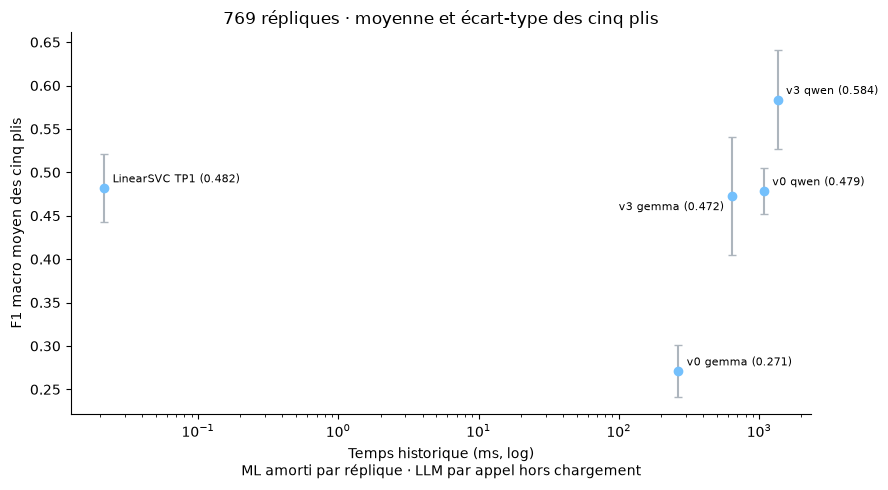

In [58]:
# F1 macro moyen face à la latence par réplique, échelle logarithmique, écart-type en barre.
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(couts['Latence par réplique (ms)'], couts['F1 macro'], yerr=couts['Écart-type'],
            fmt='o', color='#74c0fc', ecolor='#adb5bd', capsize=3)
for nom, ligne in couts.iterrows():
    gauche = nom == 'v3 gemma'  # Étiquette à gauche, sinon elle recouvre celle de v0 qwen
    ax.annotate(f'{nom} ({ligne["F1 macro"]:.3f})',
                (ligne['Latence par réplique (ms)'], ligne['F1 macro']),
                textcoords='offset points', xytext=(-6, -10) if gauche else (6, 4),
                ha='right' if gauche else 'left', fontsize=8)
ax.set_xscale('log')
ax.set(xlabel='Temps historique (ms, log)\nML amorti par réplique · LLM par appel hors chargement',
       ylabel='F1 macro moyen des cinq plis',
       title='769 répliques · moyenne et écart-type des cinq plis')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

> *Mes observations :*
>
> V3 Qwen a le F1 moyen le plus élevé du graphique et une durée par appel bien supérieure au temps ML amorti. Les barres montrent la dispersion des plis. Leur recouvrement, ou son absence, ne remplace pas un test de différence.


Je simule un routage à partir des prédictions déjà disponibles. Je classe globalement les marges hors pli de LinearSVC et envoie les plus faibles au LLM. Ces marges viennent de modèles différents et ne sont pas des probabilités de confiance calibrées.


Je fais varier la part nominale de 0 à 100 %. Le temps estimé additionne le temps ML amorti et cette part multipliée par la médiane LLM. Il suppose ce coût constant et ne mesure ni routage, ni chargement, ni latence complète du système.


In [51]:
# Pipeline hybride simulé : LinearSVC garde les répliques où il est sûr, v3 répond aux autres.
PARTS_LLM = np.round(np.linspace(0, 1, 11), 1)  # Part des répliques envoyées au LLM
HYBRIDES = ['v3 gemma', 'v3 qwen']


def marges_svc() -> pd.Series:
    """Écart entre les deux meilleurs scores de LinearSVC TP1, hors fold, pour chaque réplique."""
    marges, svc = pd.Series(index=X_train.index, dtype=float), resultats['LinearSVC TP1']
    for fold in folds:
        validation = X_train.loc[fold['validation']]
        pipeline = construire_svc_tp1().fit(X_train.loc[fold['train']],
                                            y_train.loc[fold['train']])
        assert (pipeline.predict(validation) == svc['predictions'].loc[fold['validation']]).all()
        tries = np.sort(pipeline.decision_function(validation), axis=1)
        marges.loc[fold['validation']] = tries[:, -1] - tries[:, -2]
    return marges


def hybride(nom: str, marges: pd.Series, part: float) -> dict:
    """F1 macro par fold et latence attendue quand le LLM répond aux plus faibles marges."""
    au_llm = marges.rank(method='first') <= part * len(marges)
    predits = resultats['LinearSVC TP1']['predictions'].where(~au_llm,
                                                              resultats[nom]['predictions'])
    f1 = pd.Series([f1_score(y_train.loc[fold['validation']], predits.loc[fold['validation']],
                             labels=NOMS, average='macro', zero_division=0) for fold in folds])
    latence = (MESURES_SVC['Latence par réplique (ms)']
               + part * couts.loc[nom, 'Latence par réplique (ms)'])
    return {'LLM': nom, 'Part au LLM (%)': round(100 * part), 'Appels au LLM': int(au_llm.sum()),
            'F1 macro': f1.mean(), 'Écart-type': f1.std(), 'Latence moyenne (ms)': latence}


marges = marges_svc()
simulation = pd.DataFrame([hybride(nom, marges, part) for nom in HYBRIDES for part in PARTS_LLM])
for nom in HYBRIDES:  # Aux deux bouts, LinearSVC seul puis le LLM seul
    bouts = simulation[simulation['LLM'] == nom].set_index('Part au LLM (%)')['F1 macro']
    assert np.isclose(bouts[0], couts.loc['LinearSVC TP1', 'F1 macro'])
    assert np.isclose(bouts[100], couts.loc[nom, 'F1 macro'])

# F1 et latence par part, puis la meilleure part de chaque LLM sur les 769
vue = simulation.pivot(index='Part au LLM (%)', columns='LLM',
                       values=['F1 macro', 'Latence moyenne (ms)'])
display(vue.round(3))
for _, ligne in simulation.loc[simulation.groupby('LLM')['F1 macro'].idxmax()].iterrows():
    print(f'{ligne["LLM"]} : meilleure part {ligne["Part au LLM (%)"]} %, '
          f'F1 macro {ligne["F1 macro"]:.3f} ± {ligne["Écart-type"]:.3f}, '
          f'{ligne["Appels au LLM"]} appels, {ligne["Latence moyenne (ms)"]:.0f} ms par réplique')

F1 macro         Latence moyenne (ms)          
LLM             v3 gemma v3 qwen             v3 gemma   v3 qwen
Part au LLM (%)                                                
0                  0.482   0.482                0.021     0.021
10                 0.495   0.506               64.096   135.505
20                 0.497   0.521              128.170   270.989
30                 0.512   0.548              192.245   406.473
40                 0.507   0.563              256.319   541.957
50                 0.530   0.584              320.394   677.441
60                 0.515   0.588              384.468   812.925
70                 0.505   0.592              448.542   948.409
80                 0.500   0.591              512.617  1083.892
90                 0.488   0.597              576.691  1219.376
100                0.472   0.584              640.766  1354.860

v3 gemma : meilleure part 50 %, F1 macro 0.530 ± 0.038, 384 appels, 320 ms par réplique
v3 qwen : meilleure part 90 %, F1 macro 0.597 ± 0.055, 692 appels, 1219 ms par réplique


In [60]:
# Je montre les nombres réellement routés, sans changer les parts ni les prédictions.
demo_routage = simulation[['LLM', 'Part au LLM (%)', 'Appels au LLM']].copy()
demo_routage['Part réelle (%)'] = pourcentage(demo_routage['Appels au LLM'], len(X_train))
display(demo_routage.set_index(['LLM', 'Part au LLM (%)']).round(2))


Appels au LLM  Part réelle (%)
LLM      Part au LLM (%)                                
v3 gemma 0                            0             0.00
         10                          76             9.88
         20                         153            19.90
         30                         230            29.91
         40                         307            39.92
         50                         384            49.93
         60                         461            59.95
         70                         538            69.96
         80                         615            79.97
         90                         692            89.99
         100                        769           100.00
v3 qwen  0                            0             0.00
         10                          76             9.88
         20                         153            19.90
         30                         230            29.91
         40                         307            39.92
         50                         384            49.93
         60                         461            59.95
         70                         538            69.96
         80                         615            79.97
         90                         692            89.99
         100                        769           100.00

> *Mes observations :*
>
> La simulation Gemma atteint 0,530 ± 0,038 à 50 %, soit 384 appels sur 769. Qwen atteint 0,584 à la même part, avec une estimation proche de 677 millisecondes. Ce chiffre est calculé à partir des mesures historiques.
>
> Le maximum observé de Qwen vaut 0,597 ± 0,055 à 90 %, soit 692 appels. Je sélectionne ces proportions sur les mêmes 769 répliques. La faible différence avec Qwen seul ne démontre ni supériorité générale ni équivalence.


Je trace enfin le F1 macro selon la part envoyée au LLM, une courbe par modèle. Les deux bouts redonnent LinearSVC seul et le LLM seul.


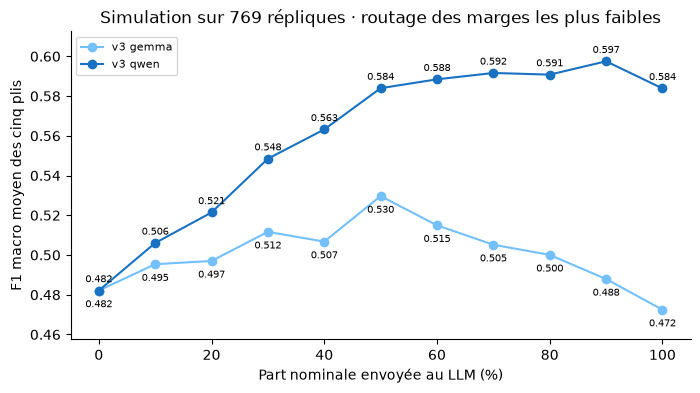

In [61]:
# F1 macro du pipeline hybride selon la part des répliques envoyées au LLM.
fig, ax = plt.subplots(figsize=(8, 4))
for nom, couleur, decalage in zip(HYBRIDES, ('#74c0fc', '#1971c2'), (-12, 6)):
    courbe = simulation[simulation['LLM'] == nom]
    ax.plot(courbe['Part au LLM (%)'], courbe['F1 macro'], marker='o', color=couleur, label=nom)
    for part, f1 in zip(courbe['Part au LLM (%)'], courbe['F1 macro']):  # Gemma sous ses points
        ax.annotate(f'{f1:.3f}', (part, f1), textcoords='offset points', xytext=(0, decalage),
                    ha='center', fontsize=7)
ax.set(xlabel='Part nominale envoyée au LLM (%)', ylabel='F1 macro moyen des cinq plis',
       title='Simulation sur 769 répliques · routage des marges les plus faibles')
ax.margins(y=0.12)  # Place pour les valeurs sous les points de Gemma
ax.legend(fontsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.show()

> *Ma conclusion :*
>
> Les rapports temporels observés soutiennent la partie descriptive de H5 et H6 dans ce protocole. Le critère « gain supérieur à l’écart-type » reste une préférence de décision, pas un test statistique. Les deux modèles diffèrent aussi autrement que par leur taille.
>
> L’hybride montre un compromis possible sur ces prédictions. Il reste une simulation dont la proportion a été choisie sur le développement. Le test suivant n’évalue pas cet hybride, donc je ne le désigne pas comme choix établi pour le déploiement.


### 4.4 Retenir les versions et consulter le même test


Je conserve V3 pour les deux modèles après la comparaison sur le développement. Je garde V0 comme témoin et je réajuste LinearSVC sur les 769 répliques. V0 et V3 ne contiennent aucun exemple local.


> *Mon hypothèse :* V3 Qwen reste devant LinearSVC, puis LinearSVC reste proche de V3 Gemma. Je mesure les écarts sur les mêmes 193 répliques. Cette comparaison reste exploratoire, car le test a déjà été consulté aux TP1 et TP2.


L’absence de ces répliques dans l’ajustement local ne permet pas de les dire inconnues du préentraînement. Retenir les versions avant cette nouvelle consultation ne rend pas le test neuf. Je conserve sa chronologie dans mes conclusions.


In [62]:
# Test : repères ML réajustés sur les 769 répliques, puis v0 et v3 des deux modèles sur les 193.
resultats_test = {}  # nom -> prédictions des 193 répliques de test, mesures et temps


def evaluer_ml_test(nom: str, construire_pipeline) -> None:
    """Pipeline neuf ajusté sur les 769 répliques, puis une seule prédiction du test."""
    debut = time.perf_counter()
    pipeline = construire_pipeline().fit(X_train, y_train)
    resultats_test[nom] = {'famille': 'ML', 'temps': time.perf_counter() - debut,
                           'predictions': pd.Series(pipeline.predict(X_test), index=X_test.index)}


def evaluer_llm_test(nom: str, modele: str) -> None:
    """Une version figée sur les 193 répliques de test, sans exemple, appels mis en cache."""
    version = VERSIONS[nom]
    assert not version['tirage']  # Rien n'est tiré du développement
    appel = version['appel']
    table = mesurer_appels(modele, version, X_test.index, appel['format'], appel['think'],
                           textes=X_test)
    table['vrai'] = y_test
    resultats_test[f'{nom} {modele}'] = {'famille': 'LLM', 'predictions': lire_etiquettes(table),
                                         'mesures': table, 'temps': temps_appels(table)}


# Repères ML, puis v0 et v3 de chaque modèle, tous les appels de Gemma avant ceux de Qwen
for nom, construire in REPERES.items():
    evaluer_ml_test(nom, construire)
travaux = [(modele, lambda nom=nom, modele=modele: evaluer_llm_test(nom, modele))
           for modele in MODELES for nom in CONFIGURATIONS_FOLDS]
grouper_par_modele(travaux)
for nom in COUPLES:
    print(f'{nom} : {len(resultats_test[nom]["mesures"])} appels, '
          f'{resultats_test[nom]["temps"] / 60:.1f} min hors chargement')

v0 gemma : 193 appels, 0.9 min hors chargement
v3 gemma : 193 appels, 2.1 min hors chargement
v0 qwen : 193 appels, 4.5 min hors chargement
v3 qwen : 193 appels, 5.1 min hors chargement


Je conserve les 1 000 rééchantillonnages de 193 répliques avec remise, identiques entre modèles. Les quantiles donnent un intervalle percentile conditionnel aux prédictions disponibles. Il ne couvre pas toute l’incertitude liée à l’entraînement, à la sélection ou aux dépendances du corpus.


In [54]:
# Scores du test avec intervalle bootstrap à 95 %, face au F1 moyen des cinq folds.
TIRAGES_BOOTSTRAP = 1000
TESTES = ['Majoritaire', 'LinearSVC TP1'] + COUPLES


def f1_noms(vrais: pd.Series, predits: pd.Series) -> float:
    """F1 macro sur les dix noms, une sortie hors liste comptée comme une erreur."""
    return f1_score(vrais, predits, labels=NOMS, average='macro', zero_division=0)


def intervalle_bootstrap(predits: pd.Series, vrais: pd.Series = y_test) -> tuple:
    """Intervalle à 95 % du F1 macro, mêmes tirages de répliques pour tous les modèles."""
    generateur = np.random.default_rng(RANDOM_STATE)
    tirages = generateur.integers(0, len(vrais), (TIRAGES_BOOTSTRAP, len(vrais)))
    valeurs = [f1_noms(vrais.iloc[tirage], predits.iloc[tirage]) for tirage in tirages]
    return tuple(np.percentile(valeurs, [2.5, 97.5]))


def ligne_test(nom: str) -> dict:
    """F1 des folds, F1 et accuracy du test avec son intervalle, conformité et temps."""
    predits = resultats_test[nom]['predictions']
    bas, haut = intervalle_bootstrap(predits)
    return {'Modèle': nom, 'F1 folds': resultats[nom]['folds']['F1 macro'].mean(),
            'F1 test': f1_noms(y_test, predits), 'Intervalle bas': bas, 'Intervalle haut': haut,
            'Accuracy test': accuracy_score(y_test, predits),
            'Conformité (%)': pourcentage(predits.isin(NOMS).sum(), len(predits)),
            'Temps (s)': resultats_test[nom]['temps']}


bilan_test = pd.DataFrame([ligne_test(nom) for nom in TESTES]).set_index('Modèle')
assert round(bilan_test.loc['LinearSVC TP1', 'F1 test'], 3) == 0.563  # Repère du TP1
display(bilan_test.round(3))

,F1 folds,F1 test,Intervalle bas,Intervalle haut,Accuracy test,Conformité (%),Temps (s)
Modèle,,,,,,,
Majoritaire,0.024,0.024,0.016,0.031,0.135,100.000,0.000
LinearSVC TP1,0.482,0.563,0.487,0.624,0.565,100.000,0.041
v0 gemma,0.271,0.314,0.238,0.376,0.326,99.482,54.221
v3 gemma,0.472,0.527,0.450,0.590,0.539,100.000,126.455
v0 qwen,0.479,0.537,0.466,0.593,0.549,99.482,272.024
v3 qwen,0.584,0.658,0.585,0.715,0.658,100.000,306.678


> *Mes observations :*
>
> LinearSVC retrouve 0,563 de F1, avec l’intervalle percentile [0,487, 0,624]. V3 Qwen atteint 0,658 avec [0,585, 0,715], et V3 Gemma 0,527. Le classement observé reste celui des moyennes des plis.
>
> Les F1 du test dépassent ceux du développement pour les configurations mesurées. Cette association ne prouve pas une facilité intrinsèque de ces répliques. Le temps ML affiché mesure son ajustement, alors que les durées LLM cumulent leurs appels hors chargement.


Je conserve les comparaisons appariées sur les 193 répliques. Je réutilise ensuite le même indicateur lexical, sans changer sa définition. Cette analyse poursuit l’exploration du même test.


In [64]:
# Désaccords sur le test, McNemar et masque lexical conservé.
display(pd.DataFrame([comparer_paire(a, b, resultats_test, y_test) for a, b in PAIRES])
        .set_index(['A', 'B']))
cite_test = X_test.str.contains(MOTIF_CITE)
lignes_cite_test = [ligne_cite(nom, libelle, masque, resultats_test, y_test)
                    for nom in ('v3 gemma', 'v3 qwen')
                    for libelle, masque in (('indicateur détecté', cite_test),
                                            ('indicateur absent', ~cite_test))]
display(pd.DataFrame(lignes_cite_test).set_index(['Modèle', 'Répliques']).round(1))

A seul juste  B seul juste  Deux justes  Deux faux  \
A             B                                                              
LinearSVC TP1 v3 gemma            43            38           66         46   
              v3 qwen             31            49           78         35   
v3 gemma      v3 qwen             16            39           88         50   
v0 gemma      v3 gemma            14            55           49         75   
v0 qwen       v3 qwen              7            28           99         59   

                        p-value  
A             B                  
LinearSVC TP1 v3 gemma  6.6e-01  
              v3 qwen   5.7e-02  
v3 gemma      v3 qwen   2.7e-03  
v0 gemma      v3 gemma  6.9e-07  
v0 qwen       v3 qwen   5.1e-04

Nombre  Corrigées  Cassées  Gain net  \
Modèle   Répliques                                                  
v3 gemma indicateur détecté      65         12       15        -3   
         indicateur absent      128         26       28        -2   
v3 qwen  indicateur détecté      65         17        3        14   
         indicateur absent      128         32       28         4   

                             Gain net pour 100  Justesse LinearSVC (%)  \
Modèle   Répliques                                                       
v3 gemma indicateur détecté               -4.6                    70.8   
         indicateur absent                -1.6                    49.2   
v3 qwen  indicateur détecté               21.5                    70.8   
         indicateur absent                 3.1                    49.2   

                             Justesse du modèle (%)  
Modèle   Répliques                                   
v3 gemma indicateur détecté                    66.2  
         indicateur absent                     47.7  
v3 qwen  indicateur détecté                    92.3  
         indicateur absent                     52.3

> *Mes observations :*
>
> Qwen et LinearSVC ont seuls raison sur 49 et 31 répliques, avec p = 0,057. LinearSVC et Gemma ont seuls raison sur 43 et 38 répliques, avec p = 0,66. Ces tests concernent les désaccords de correction et ne démontrent aucune égalité des F1.
>
> L’indicateur lexical détecte 65 répliques et laisse 128 répliques dans l’autre groupe. Qwen gagne respectivement 21,5 et 3,1 réponses nettes pour 100 face à LinearSVC. Ce découpage conserve « The » et les autres mots de la liste.


Je trace séparément les matrices du test exploratoire, avec effectifs et pourcentages. Les classes comptent entre 16 et 26 répliques. Une seule réponse fait donc varier leur rappel d’environ 3,8 à 6,3 points.


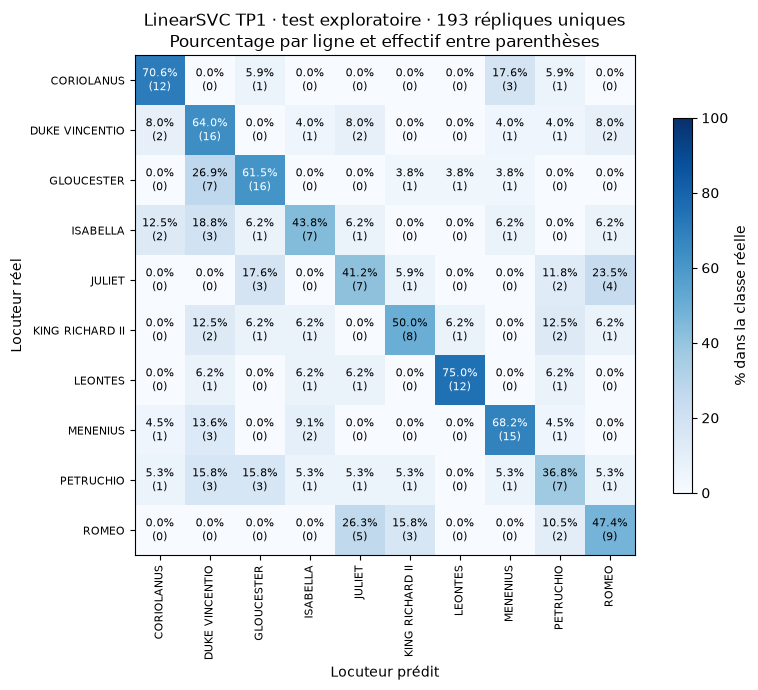

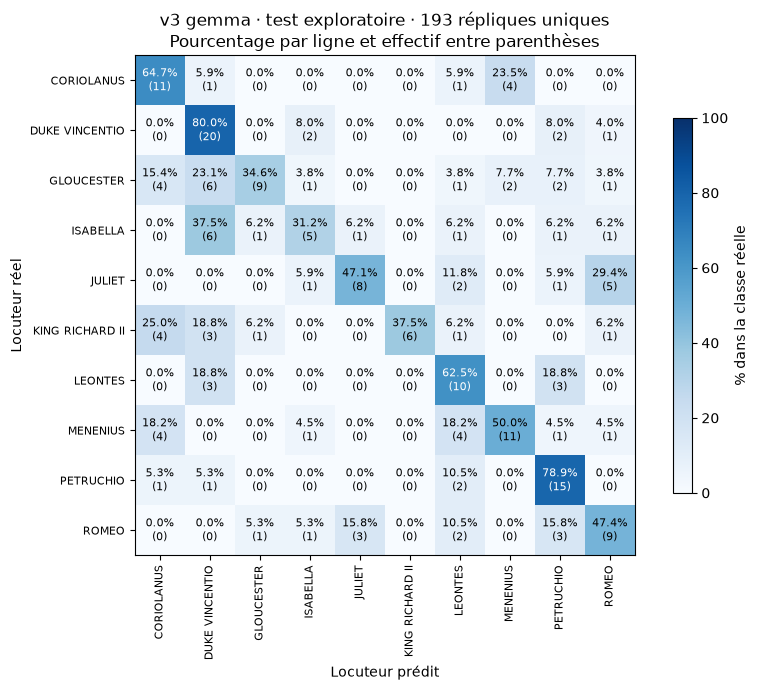

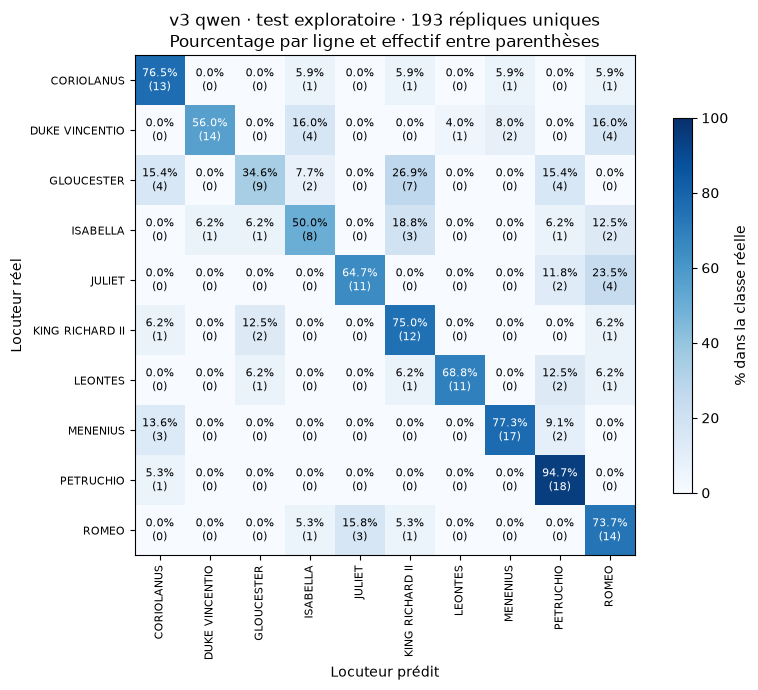

In [65]:
# Matrices du même test exploratoire, une figure lisible par modèle.
matrices_test = {nom: matrice_confusion(nom, resultats_test, y_test) for nom in MEILLEURS}
for nom, matrice in matrices_test.items():
    fig, axe = plt.subplots(figsize=(9, 7))
    tracer_matrice(axe, f'{nom} · test exploratoire · 193 répliques uniques', matrice)
    plt.tight_layout()
    plt.show()


In [66]:
# Rappel moyen, trois plus fortes confusions et couples du TP1 sur le test.
decrire_confusions(matrices_test)

LinearSVC TP1 : rappel moyen 55.8 %
   plus fortes confusions
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      ROMEO → JULIET : 26.3 % (5 sur 19)
      JULIET → ROMEO : 23.5 % (4 sur 17)
   couples suivis depuis le TP1
      JULIET → ROMEO : 23.5 % (4 sur 17)
      ROMEO → JULIET : 26.3 % (5 sur 19)
      GLOUCESTER → DUKE VINCENTIO : 26.9 % (7 sur 26)
      DUKE VINCENTIO → GLOUCESTER : 0.0 % (0 sur 25)
v3 gemma : rappel moyen 53.4 %
   plus fortes confusions
      ISABELLA → DUKE VINCENTIO : 37.5 % (6 sur 16)
      JULIET → ROMEO : 29.4 % (5 sur 17)
      KING RICHARD II → CORIOLANUS : 25.0 % (4 sur 16)
   couples suivis depuis le TP1
      JULIET → ROMEO : 29.4 % (5 sur 17)
      ROMEO → JULIET : 15.8 % (3 sur 19)
      GLOUCESTER → DUKE VINCENTIO : 23.1 % (6 sur 26)
      DUKE VINCENTIO → GLOUCESTER : 0.0 % (0 sur 25)
v3 qwen : rappel moyen 67.1 %
   plus fortes confusions
      GLOUCESTER → KING RICHARD II : 26.9 % (7 sur 26)
      JULIET → ROMEO : 23.5 % (4 sur 17)
   

> *Mes observations :*
>
> Les rappels moyens valent 55,8 % pour LinearSVC, 53,4 % pour Gemma et 67,1 % pour Qwen. GLOUCESTER vers DUKE VINCENTIO concerne respectivement 7, 6 et 0 répliques sur 26. Qwen envoie toutefois 7 répliques de GLOUCESTER vers KING RICHARD II.
>
> Je retrouve l’ordre attendu des scores, avec un écart de F1 de 0,095 entre V3 Qwen et LinearSVC. Le recouvrement des intervalles n’est pas un test de différence. La valeur de McNemar et la chronologie du test limitent toute conclusion confirmatoire.


### 4.5 Mon journal d’expériences


Je conserve les essais acceptés et refusés, avec leurs décisions d’origine. Je sépare les phases pour retrouver ce que chaque comparaison a réellement testé.


#### Contrôles et choix pratiques


| Essai | Observation | Décision et limite |
|---|---|---|
| 1. Répétabilité | Chaque paire historique rend le même texte aux deux températures | Réglages conservés, accord local seulement |
| 2. Cache de préfixe | Baisse du temps après répétition, effet différent après changement de réplique | Contrôle local, distinct du cache disque |
| 3. Bascule | Plusieurs secondes de chargement lors des changements | Appels groupés par modèle |
| 4. Modèle de mise au point | Médianes directes proches de 0,26 et 1,09 seconde | Gemma mène les itérations, budgets projetés depuis les médianes |


#### Choix des prompts sur les 50 répliques


| Essai | Observation | Décision et limite |
|---|---|---|
| 5. Format | 100 % d’étiquettes exploitables partout, gain net maximal de trois | V1-schema pour Gemma et V1-text pour Qwen. H4 partiellement examinée |
| 6. V2 critères | F1 Gemma 0,306, gain net deux | Refusée, ses critères restent absents de V3 |
| 7. V3 contexte | F1 Gemma 0,453, gain net sept | Retenue. H2 sur les noms n’est pas directement testée par le masque lexical |
| 8. V4 dix exemples | F1 0,222, gain net −8 | V3 conservée, résultat limité à ce tirage |
| 9. V5 trente exemples | F1 0,352, gain net −3 | V3 conservée, exemples et longueur changent ensemble |
| 10. V6 exemples difficiles | F1 0,350, gain net nul face à V5 | V3 conservée, aucune équivalence démontrée |
| 11. Transfert de V3 | F1 Qwen 0,488 contre 0,461, gain net nul | Parent V1-schema, refus selon la règle des 50 |
| 12. V7 justification ou réflexion | Gemma perd cinq réponses nettes. Qwen natif termine 28 réponses et en réussit 22 | Variantes refusées, coût et budget font partie du résultat |


#### Comparaisons élargies


| Essai | Observation | Décision et limite |
|---|---|---|
| 13. Développement complet | F1 moyen V3 de 0,472 pour Gemma et 0,584 pour Qwen, contre 0,482 pour LinearSVC | V3 retenue pour les deux après consultation des 719 répliques |
| 14. Même test | F1 de 0,658 pour V3 Qwen, 0,563 pour LinearSVC et 0,527 pour V3 Gemma | Classement observé conservé, évaluation exploratoire |


### 4.6 Ce que je peux conclure


Je rapproche qualité et temps en gardant leurs définitions. Les points de développement sont des moyennes par pli et ceux du test des scores sur les 193 répliques. Les barres du test représentent le bootstrap conditionnel aux prédictions.


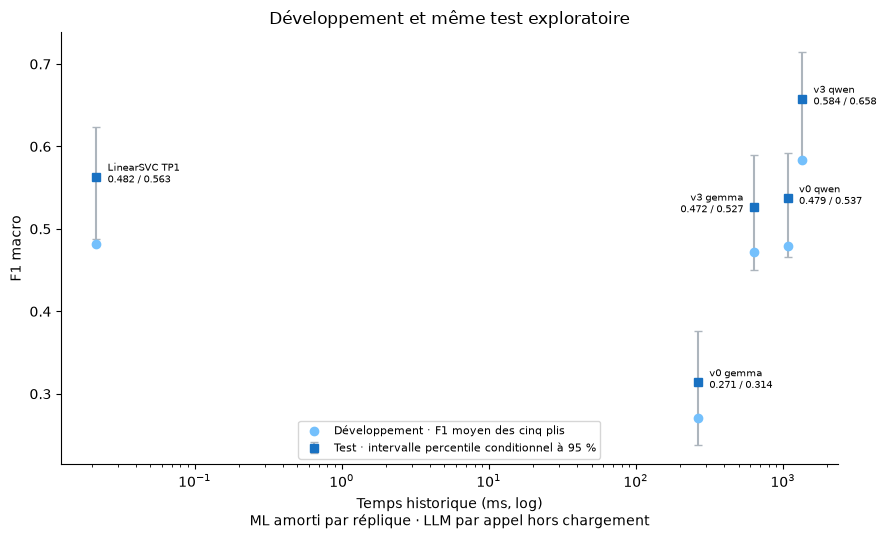

In [67]:
# Synthèse : F1 des folds et du test face à la latence par réplique, intervalle du test en barre.
SYNTHESE = ['LinearSVC TP1'] + COUPLES
latences = couts.loc[SYNTHESE, 'Latence par réplique (ms)']
test = bilan_test.loc[SYNTHESE]
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(latences, test['F1 folds'], color='#74c0fc', zorder=3,
           label='Développement · F1 moyen des cinq plis')
barres = [test['F1 test'] - test['Intervalle bas'], test['Intervalle haut'] - test['F1 test']]
ax.errorbar(latences, test['F1 test'], yerr=barres, fmt='s', color='#1971c2', ecolor='#adb5bd',
            capsize=3, label='Test · intervalle percentile conditionnel à 95 %')
for nom in SYNTHESE:
    gauche = nom == 'v3 gemma'  # Étiquette à gauche, sinon elle recouvre celle de v0 qwen
    ax.annotate(f'{nom}\n{test.loc[nom, "F1 folds"]:.3f} / {test.loc[nom, "F1 test"]:.3f}',
                (latences[nom], test.loc[nom, 'F1 test']), textcoords='offset points',
                xytext=(-8, -4) if gauche else (8, -4), ha='right' if gauche else 'left',
                fontsize=7)
ax.set_xscale('log')
ax.set(xlabel='Temps historique (ms, log)\nML amorti par réplique · LLM par appel hors chargement',
       ylabel='F1 macro',
       title='Développement et même test exploratoire')
ax.legend(fontsize=8, loc='lower center')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

> *Mes observations :*
>
> V3 Qwen garde le meilleur F1 parmi les configurations évaluées sur le test. Son coût d’appel reste très supérieur au temps ML amorti. Cette figure présente le compromis observé, sans mesurer toute la recherche ni valider un choix de déploiement.


V0 Qwen reste proche de LinearSVC sur le développement, tandis que V0 Gemma est nettement plus bas. V3 améliore les deux configurations minimales. Le questionnaire sur les pièces ne permet pas d’attribuer une part de ce gain à une connaissance précise.


Les trois sélections d’exemples et les variantes de réflexion ne passent pas la règle sur les 50 répliques. Je ne généralise pas cet échec à d’autres exemples, modèles ou budgets. La réflexion native de Qwen illustre surtout le besoin de lire ensemble qualité et couverture.


L’hybride décrit un compromis possible, sélectionné sur le développement et sans évaluation indépendante. Les marges ML ne fournissent pas encore un seuil de routage validé. Je garde LinearSVC comme repère de coût et V3 Qwen comme meilleur score observé parmi les configurations testées.


Le même corpus intervient dans plusieurs étapes de conception et le test a déjà été consulté. Les modèles préentraînés ne sont pas contrôlés pour une exposition antérieure à Shakespeare. Ces limites portent sur la portée de mes conclusions, même lorsque les calculs sont reproductibles.


Je reviens aux hypothèses initiales sans transformer une observation locale en verdict général.


| Hypothèse | Bilan | Éléments observés |
|---|---|---|
| H1, connaissance préalable | Ordre attendu sur le développement, exception Qwen sur les 50 | V0 donne 0,271 et 0,479 contre 0,482 pour LinearSVC. La proximité de Qwen ne prouve pas l’équivalence |
| H2, contexte et noms | Gain de contexte observé, rôle des noms non directement testé | L’indicateur inclut des mots génériques. Ses sous-groupes restent descriptifs |
| H3, exemples | Gain annoncé absent dans les sélections testées | V4 à V6 perdent trois à huit réponses nettes. Sensibilité à plusieurs tirages non mesurée |
| H4, format | Vérification partielle | Conformité déjà complète. Pas de comparaison de tous les formats sur les cinq plis |
| H5, coût | Rapport local très élevé, critère de choix heuristique | Temps ML amorti et médianes LLM mesurent des traitements différents |
| H6, grand modèle | Qwen devant dans les comparaisons réalisées | Famille, préentraînement, tokenizer et quantification diffèrent aussi. RAM non mesurée |
| H7, transfert | Gain de V0 à V3 observé sur les deux modèles | F1 positif face au parent sur les 50, mais gain net nul pour Qwen |
| H8, raisonnement | Texte de justification observé, variantes non retenues | Aucun gain net positif. Partie sur les noms limitée par l’indicateur lexical |
| Gain de V3 plus faible hors des 50 | Légèrement chez Gemma, pas chez Qwen | Gain net pour 100 de 20 à 18,2 et de 4 à 9,9 |
| Erreurs plus souvent dans la pièce | Non soutenue par les groupes reconstruits | V3 donne 18,6 % et 22,0 %, contre 20,2 % pour LinearSVC |


> *Ma conclusion :*
>
> Cette investigation me conduit à vérifier le traitement réel d’une réponse avant d’interpréter son score. Je dois suivre le parent exact du prompt et les données déjà consultées. Le gain de V3 Qwen est observé, mais sa généralisation reste à établir.
>
> Je sépare désormais étiquette exploitable, réponse correcte et coût mesuré. Je vérifie aussi ce que détecte un indicateur avant de lui donner un nom. Une explication plausible en lisant une réplique ne remplace pas un contrôle qui isole cette explication.


### Pour aller plus loin


Ces pistes restent hors des expériences réalisées.


- Évaluer un routage et sa proportion sur des données réservées avant la sélection.
- Clarifier les identités derrière GLOUCESTER et JULIET avant de modifier leur contexte.
- Réserver une validation distincte pour choisir les prompts et répéter plusieurs sélections d’exemples.
- Comparer des exemples choisis par similarité, sans supposer qu’ils feront mieux que les tirages actuels.
- Examiner un autre budget de réflexion en comptant toujours les réponses tronquées.
- Vérifier la calibration d’un score avant de l’utiliser pour router les appels.
- Comparer un ajustement local au prompting si les données et le budget permettent un protocole séparé.
